# Machine Learning Project: Customer Shopping Dataset

This project aims to analyze a customer shopping behavior dataset by building and comparing a wide range of supervised and unsupervised machine learning models. The ultimate goal is to classify customers, predict future behaviors, and uncover hidden patterns within the data.

The dataset we will be using contains informations about customers' shopping:
- Customer ID
- Age
- Gender
- Item Purchased
- Category
- Purchase Amount
- Location
- Size
- Color
- Season
- Review Rating
- Subscription Status
- Payment Method
- Shipping Type
- Discount Applied
- Promo Code Used
- Previous Purchases
- Preferred Payment Method
- Frequency of Purchases




# Imports


All essential libraries for data manipulation, visualization, model building, performance evaluation, and result analysis are imported here

In [ ]:
# Data manipulation & visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Model selection & preprocessing tools
from sklearn.experimental import enable_halving_search_cv
from sklearn.model_selection import HalvingGridSearchCV, HalvingRandomSearchCV

from sklearn.model_selection import (train_test_split,
                                     GridSearchCV,
                                     RandomizedSearchCV,
                                     cross_val_score,
                                     KFold,
                                     HalvingGridSearchCV,
                                     StratifiedKFold)
from sklearn.preprocessing import (LabelEncoder,
                                   StandardScaler,
                                   OneHotEncoder,
                                   Normalizer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import (SelectKBest,
                                       f_classif)

# Classification models
from sklearn.tree import (DecisionTreeClassifier,
                          plot_tree)
from sklearn.ensemble import (RandomForestClassifier,
                              GradientBoostingClassifier,
                              VotingClassifier,
                              BaggingClassifier,
                              AdaBoostClassifier,
                              ExtraTreesClassifier,
                              StackingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neural_network import MLPClassifier
from sklearn.utils import resample

# Clustering models
from sklearn.cluster import (KMeans,
                             BisectingKMeans,
                             DBSCAN)

# Evaluation metrics
from sklearn.metrics import (classification_report,
                             confusion_matrix,
                             accuracy_score,
                             precision_score,
                             recall_score,
                             f1_score,
                             silhouette_score,
                             calinski_harabasz_score,
                             davies_bouldin_score,
                             roc_curve,
                             auc,
                             make_scorer)

# Additional ML tools
from sklearn.decomposition import PCA
from sklearn.calibration import calibration_curve, CalibratedClassifierCV

# Gradient boosting (XGBoost)
from xgboost import XGBClassifier

# Class balancing techniques
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE, ADASYN, RandomOverSampler
from imblearn.combine import SMOTEENN, SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

# Kaggle setup

Preparation of the working environment, including the download of the dataset from Kaggle and configuring credentials or required directories

Select the kaggle.json file in your file system, which is the API token you created or received

In [ ]:
!pip install kaggle --quiet
!pip install pandas scikit-learn tensorflow --quiet

from google.colab import files
files.upload()

!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle (2).json


Loading the dataset

In [ ]:
!kaggle datasets download bhadramohit/customer-shopping-latest-trends-dataset --force
!unzip -q customer-shopping-latest-trends-dataset.zip
df = pd.read_csv("shopping_trends.csv")

Dataset URL: https://www.kaggle.com/datasets/bhadramohit/customer-shopping-latest-trends-dataset
License(s): Community Data License Agreement - Sharing - Version 1.0
  0% 0.00/75.9k [00:00<?, ?B/s]
100% 75.9k/75.9k [00:00<00:00, 118MB/s]
replace shopping_trends.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y


# Overview

Checking if the database was dowloaded correctly and taking a quick look to his general structure

Database's first 5 rows

In [ ]:
print(df.head())

   Customer ID  Age Gender Item Purchased  Category  Purchase Amount (USD)  \
0            1   55   Male         Blouse  Clothing                     53   
1            2   19   Male        Sweater  Clothing                     64   
2            3   50   Male          Jeans  Clothing                     73   
3            4   21   Male        Sandals  Footwear                     90   
4            5   45   Male         Blouse  Clothing                     49   

        Location Size      Color  Season  Review Rating Subscription Status  \
0       Kentucky    L       Gray  Winter            3.1                 Yes   
1          Maine    L     Maroon  Winter            3.1                 Yes   
2  Massachusetts    S     Maroon  Spring            3.1                 Yes   
3   Rhode Island    M     Maroon  Spring            3.5                 Yes   
4         Oregon    M  Turquoise  Spring            2.7                 Yes   

  Payment Method  Shipping Type Discount Applied Promo C

Database's general informations

In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Customer ID               3900 non-null   int64  
 1   Age                       3900 non-null   int64  
 2   Gender                    3900 non-null   object 
 3   Item Purchased            3900 non-null   object 
 4   Category                  3900 non-null   object 
 5   Purchase Amount (USD)     3900 non-null   int64  
 6   Location                  3900 non-null   object 
 7   Size                      3900 non-null   object 
 8   Color                     3900 non-null   object 
 9   Season                    3900 non-null   object 
 10  Review Rating             3900 non-null   float64
 11  Subscription Status       3900 non-null   object 
 12  Payment Method            3900 non-null   object 
 13  Shipping Type             3900 non-null   object 
 14  Discount

Description of all the features

In [ ]:
df.describe(include='all')

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Payment Method,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Preferred Payment Method,Frequency of Purchases
count,3900.000000,3900.000000,3900,3900,3900,3900.000000,3900,3900,3900,3900,3900.000000,3900,3900,3900,3900,3900,3900.000000,3900,3900
unique,NaN,NaN,2,25,4,NaN,50,4,25,4,NaN,2,6,6,2,2,NaN,6,7
top,NaN,NaN,Male,Blouse,Clothing,NaN,Montana,M,Olive,Spring,NaN,No,Credit Card,Free Shipping,No,No,NaN,PayPal,Every 3 Months
freq,NaN,NaN,2652,171,1737,NaN,96,1755,177,999,NaN,2847,696,675,2223,2223,NaN,677,584
mean,1950.500000,44.068462,NaN,NaN,NaN,59.764359,NaN,NaN,NaN,NaN,3.749949,NaN,NaN,NaN,NaN,NaN,25.351538,NaN,NaN
std,1125.977353,15.207589,NaN,NaN,NaN,23.685392,NaN,NaN,NaN,NaN,0.716223,NaN,NaN,NaN,NaN,NaN,14.447125,NaN,NaN
min,1.000000,18.000000,NaN,NaN,NaN,20.000000,NaN,NaN,NaN,NaN,2.500000,NaN,NaN,NaN,NaN,NaN,1.000000,NaN,NaN
25%,975.750000,31.000000,NaN,NaN,NaN,39.000000,NaN,NaN,NaN,NaN,3.100000,NaN,NaN,NaN,NaN,NaN,13.000000,NaN,NaN
50%,1950.500000,44.000000,NaN,NaN,NaN,60.000000,NaN,NaN,NaN,NaN,3.700000,NaN,NaN,NaN,NaN,NaN,25.000000,NaN,NaN
75%,2925.250000,57.000000,NaN,NaN,NaN,81.000000,NaN,NaN,NaN,NaN,4.400000,NaN,NaN,NaN,NaN,NaN,38.000000,NaN,NaN


Counting categoric column

In [ ]:
print(df['Gender'].value_counts())

Gender
Male      2652
Female    1248
Name: count, dtype: int64


In [ ]:
print(df['Item Purchased'].value_counts())

Item Purchased
Blouse        171
Pants         171
Jewelry       171
Shirt         169
Dress         166
Sweater       164
Jacket        163
Coat          161
Sunglasses    161
Belt          161
Sandals       160
Socks         159
Skirt         158
Scarf         157
Shorts        157
Hat           154
Handbag       153
Hoodie        151
Shoes         150
T-shirt       147
Sneakers      145
Boots         144
Backpack      143
Gloves        140
Jeans         124
Name: count, dtype: int64


In [ ]:
print(df['Category'].value_counts())

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64


In [ ]:
print(df['Location'].value_counts())

Location
Montana           96
California        95
Idaho             93
Illinois          92
Alabama           89
Minnesota         88
New York          87
Nevada            87
Nebraska          87
Delaware          86
Maryland          86
Vermont           85
Louisiana         84
North Dakota      83
West Virginia     81
Missouri          81
New Mexico        81
Mississippi       80
Kentucky          79
Arkansas          79
Georgia           79
Indiana           79
Connecticut       78
North Carolina    78
Maine             77
Ohio              77
Virginia          77
Texas             77
Tennessee         77
South Carolina    76
Oklahoma          75
Wisconsin         75
Colorado          75
Oregon            74
Pennsylvania      74
Michigan          73
Washington        73
Alaska            72
Massachusetts     72
Utah              71
Wyoming           71
New Hampshire     71
South Dakota      70
Iowa              69
Florida           68
New Jersey        67
Arizona           65
Hawa

In [ ]:
print(df['Size'].value_counts())

Size
M     1755
L     1053
S      663
XL     429
Name: count, dtype: int64


In [ ]:
print(df['Color'].value_counts())

Color
Olive        177
Yellow       174
Silver       173
Teal         172
Green        169
Black        167
Cyan         166
Violet       166
Gray         159
Maroon       158
Orange       154
Charcoal     153
Pink         153
Blue         152
Magenta      152
Purple       151
Peach        149
Red          148
Beige        147
Indigo       147
Lavender     147
Turquoise    145
White        142
Brown        141
Gold         138
Name: count, dtype: int64


In [ ]:
print(df['Season'].value_counts())

Season
Spring    999
Fall      975
Winter    971
Summer    955
Name: count, dtype: int64


In [ ]:
print(df['Subscription Status'].value_counts())

Subscription Status
No     2847
Yes    1053
Name: count, dtype: int64


In [ ]:
print(df['Payment Method'].value_counts())

Payment Method
Credit Card      696
Venmo            653
Cash             648
PayPal           638
Debit Card       633
Bank Transfer    632
Name: count, dtype: int64


In [ ]:
print(df['Shipping Type'].value_counts())

Shipping Type
Free Shipping     675
Standard          654
Store Pickup      650
Next Day Air      648
Express           646
2-Day Shipping    627
Name: count, dtype: int64


In [ ]:
print(df['Discount Applied'].value_counts())

Discount Applied
No     2223
Yes    1677
Name: count, dtype: int64


In [ ]:
print(df['Promo Code Used'].value_counts())

Promo Code Used
No     2223
Yes    1677
Name: count, dtype: int64


In [ ]:
print(df['Preferred Payment Method'].value_counts())

Preferred Payment Method
PayPal           677
Credit Card      671
Cash             670
Debit Card       636
Venmo            634
Bank Transfer    612
Name: count, dtype: int64


In [ ]:
print(df['Frequency of Purchases'].value_counts())

Frequency of Purchases
Every 3 Months    584
Annually          572
Quarterly         563
Monthly           553
Bi-Weekly         547
Fortnightly       542
Weekly            539
Name: count, dtype: int64


# Cleaning and Preprocessing

Data cleaning and preparation: handling missing values, removing outliers, encoding categorical variables, and defining the target variable. This step is crucial to ensure data quality and reliable model performance

## Cleaning

The dataset has already been cleaned before

In [ ]:
df.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


## Defining target variables

In [ ]:
df2=df.copy()
# Target: Subscription Status
y = df['Subscription Status']
X = df.drop(columns=['Subscription Status', 'Customer ID'])

# Defining categorical and numeric features
cat_feats = [c for c in X.columns if X[c].dtype == 'object']
num_feats = [c for c in X.columns if X[c].dtype != 'object']

# Preprocessing: scaling for numericals, one-hot encoding for categorials
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_feats),
    ('cat', OneHotEncoder(drop='first'), cat_feats)
])

# Applying transformations
X_processed = preprocessor.fit_transform(X)

# Train-test split
X_train, X_test, y_train_raw, y_test_raw = train_test_split(
    X_processed, y, test_size=0.2, random_state=42, stratify=y
)

# Encode target labels: 'No' becomes 0, 'Yes' becomes 1
le = LabelEncoder()
y_train = le.fit_transform(y_train_raw) # Fit on training labels and transform
y_test = le.transform(y_test_raw) # Transform test labels using same encoder

print(f"Train/Test shape: {X_train.shape}/{X_test.shape}")

Train/Test shape: (3120, 134)/(780, 134)


# EDA: Exploratory Data Analysis

In-depth data exploration through descriptive statistics and visualizations. Feature distributions, variable relationships, correlations, and categorical differences are examined to better understand the dataset and identify useful patterns for modeling

## Description using ProfileReport

It's possible to obtain a complete and interactive EDA report, which provides:
- descriptive statistics for all columns
- interactive distributions (histograms, boxplots, pie charts)
- correlation matrix (Pearson, Spearman, Kendall)
- missing values ​​analysis with heatmap and bar chart
- automatic outlier detection
- automatic cleaning suggestions

In [ ]:
!pip install ydata_profiling
from ydata_profiling import ProfileReport

profile = ProfileReport(df, explorative=True)

display(profile)

Output hidden; open in https://colab.research.google.com to view.

Note: ProfileReport is done on the basic dataframe where Customer ID and Subscription Status are still present

## Correlation heatmap

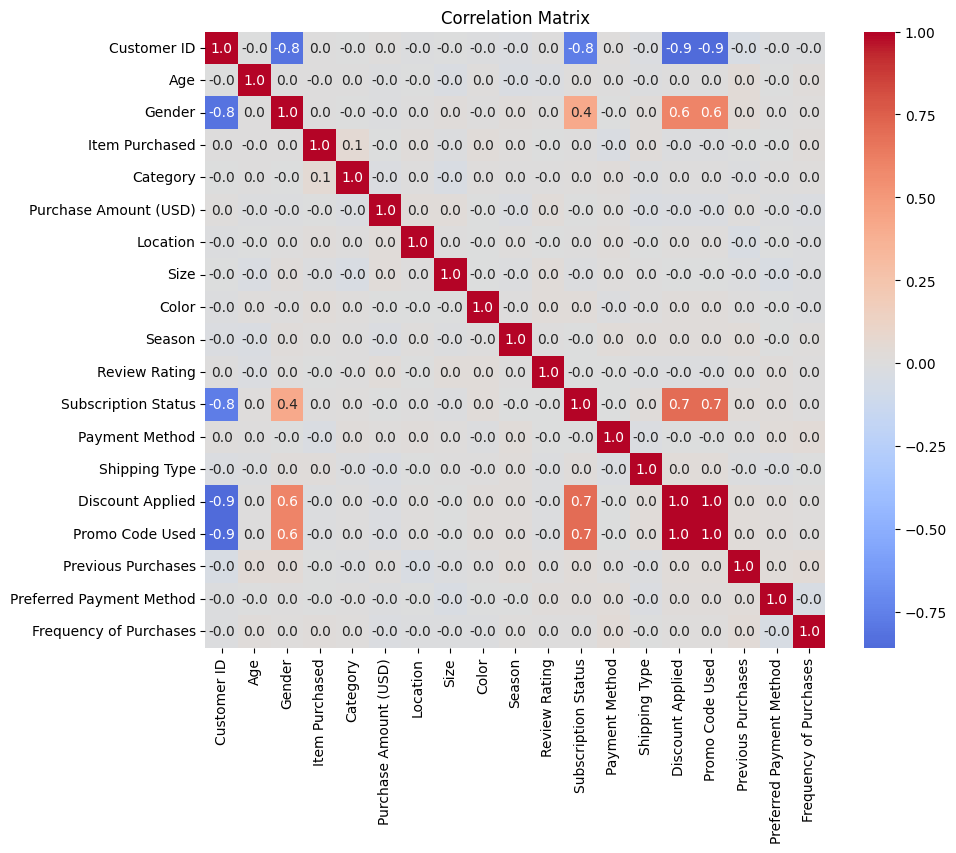

In [ ]:
plt.figure(figsize=(10, 8))
# Convert categorical variables for correlation
df_corr = df.copy()
le = LabelEncoder()
categorical_cols = ['Gender',
                    'Item Purchased',
                    'Category',
                    'Location',
                    'Size',
                    'Color',
                    'Season',
                    'Subscription Status',
                    'Payment Method',
                    'Shipping Type',
                    'Discount Applied',
                    'Promo Code Used',
                    'Preferred Payment Method',
                    'Frequency of Purchases']
for col in categorical_cols:
    df_corr[col] = le.fit_transform(df_corr[col])

correlation_matrix = df_corr.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".1f", cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.show()

It seems Subscription Status (the target variable) has some correlation with Gender, Promo Code Used and Discount Applied

## Feature importance

Analysis of feature relevance using statistical tests (ANOVA / F-test) and tree-based models (Random Forest). This helps identify the most predictive variables and improve model performance

### ANOVA/F-test method


Top 10 features according to ANOVA/F-test:

Discount Applied_Yes      2859.015543
Promo Code Used_Yes       2859.015543
Gender_Male                652.574400
Item Purchased_Blouse        8.704450
Previous Purchases           7.011299
Location_Kansas              6.081808
Color_Turquoise              3.813245
Item Purchased_Jeans         2.938339
Location_Maine               2.849535
Item Purchased_Sweater       2.817905
dtype: float64


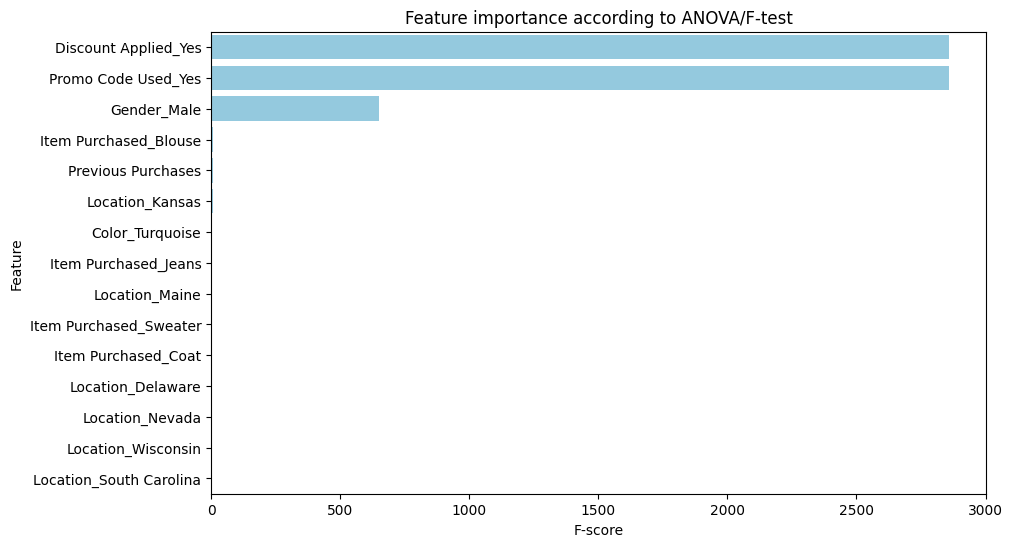

In [ ]:
selector = SelectKBest(f_classif, k="all")
selector.fit(X_train, y_train)

# Retrieving feature names from the ColumnTransformer
feature_names = []

# Numeric names (same)
feature_names.extend(num_feats)

# Category names (expanded from OneHotEncoder)
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(cat_feats)
feature_names.extend(cat_feature_names)

# Series with ANOVA scores
anova_scores = pd.Series(selector.scores_, index=feature_names).sort_values(ascending=False)

print("\nTop 10 features according to ANOVA/F-test:\n")
print(anova_scores.head(10))

# Visualization
plt.figure(figsize=(10,6))
sns.barplot(x=anova_scores.head(15), y=anova_scores.head(15).index, color="skyblue")
plt.title("Feature importance according to ANOVA/F-test")
plt.xlabel("F-score")
plt.ylabel("Feature")
plt.show()

Note: F-score measures the level of correlation between a feature and the target variable. It's different from the F1-score used to understand how good a model is

### Random forest method


Top 10 features according to Random Forest:

Promo Code Used_Yes      0.200672
Discount Applied_Yes     0.195810
Gender_Male              0.049041
Purchase Amount (USD)    0.039933
Age                      0.039106
Previous Purchases       0.039055
Review Rating            0.033886
Size_M                   0.007823
Season_Summer            0.007576
Season_Winter            0.007026
dtype: float64


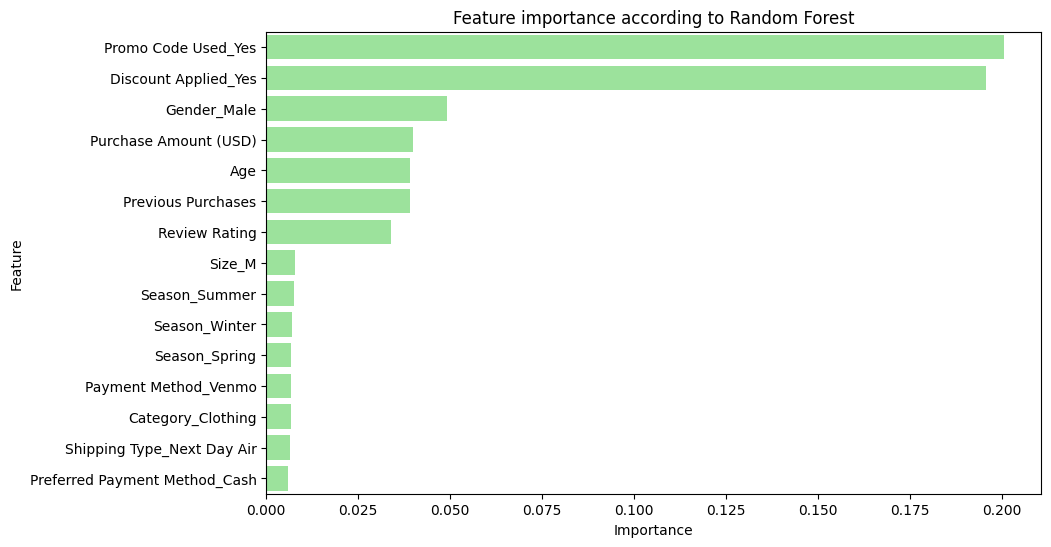

In [ ]:
# Random Forest Feature Importance
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)

# Retrieving feature names from the ColumnTransformer
feature_names = []
feature_names.extend(num_feats)
cat_encoder = preprocessor.named_transformers_['cat']
cat_feature_names = cat_encoder.get_feature_names_out(cat_feats)
feature_names.extend(cat_feature_names)

# Series with feature importance
rf_importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

print("\nTop 10 features according to Random Forest:\n")
print(rf_importances.head(10))

# Visualization
plt.figure(figsize=(10,6))
sns.barplot(x=rf_importances.head(15), y=rf_importances.head(15).index, color="lightgreen")
plt.title("Feature importance according to Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

### Performance comparison

In [ ]:
# Retrieving feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# ANOVA feature ranking
selector = SelectKBest(f_classif, k="all")
selector.fit(X_train, y_train)
anova_scores = pd.Series(selector.scores_, index=feature_names).sort_values(ascending=False)

# Random Forest feature ranking
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(X_train, y_train)
rf_importances = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False)

# Confronting Logistic Regression with assigned features
print("Confronting Logistic Regression:")
for k in [2, 5, 10, X_train.shape[1]]:
    # Top-k according to ANOVA
    top_features_anova = anova_scores.head(k).index
    # Finding the numerical indices of these features in the feature_names array
    anova_indices = [np.where(feature_names == f)[0][0] for f in top_features_anova]

    # Use indexes to select columns from X_train and X_test
    Xk_train_anova = X_train[:, anova_indices]
    Xk_test_anova = X_test[:, anova_indices]

    lr = LogisticRegression(max_iter=5000, random_state=0)
    lr.fit(Xk_train_anova, y_train)
    acc_anova = accuracy_score(y_test, lr.predict(Xk_test_anova))

    # Top-k according to Random Forest
    top_features_rf = rf_importances.head(k).index
    # Finding the numerical indices of these features in the feature_names array
    rf_indices = [np.where(feature_names == f)[0][0] for f in top_features_rf]

    # Use indexes to select columns from X_train and X_test
    Xk_train_rf = X_train[:, rf_indices]
    Xk_test_rf = X_test[:, rf_indices]

    lr.fit(Xk_train_rf, y_train)
    acc_rf = accuracy_score(y_test, lr.predict(Xk_test_rf))

    print(f"Top {k} features -> ANOVA acc: {acc_anova:.3f} | RF acc: {acc_rf:.3f}")

Confronting Logistic Regression:
Top 2 features -> ANOVA acc: 0.864 | RF acc: 0.864
Top 5 features -> ANOVA acc: 0.862 | RF acc: 0.864
Top 10 features -> ANOVA acc: 0.862 | RF acc: 0.864
Top 134 features -> ANOVA acc: 0.851 | RF acc: 0.851


Accuracy increases with fewer relevant features, while it decreases in the last iteration because we use *all* the features (134 after one-hot encoding). In this case, the model introduces noise and
redundancy, worsening generalization compared to when it uses
only the most informative variables.

## Distribution of key features

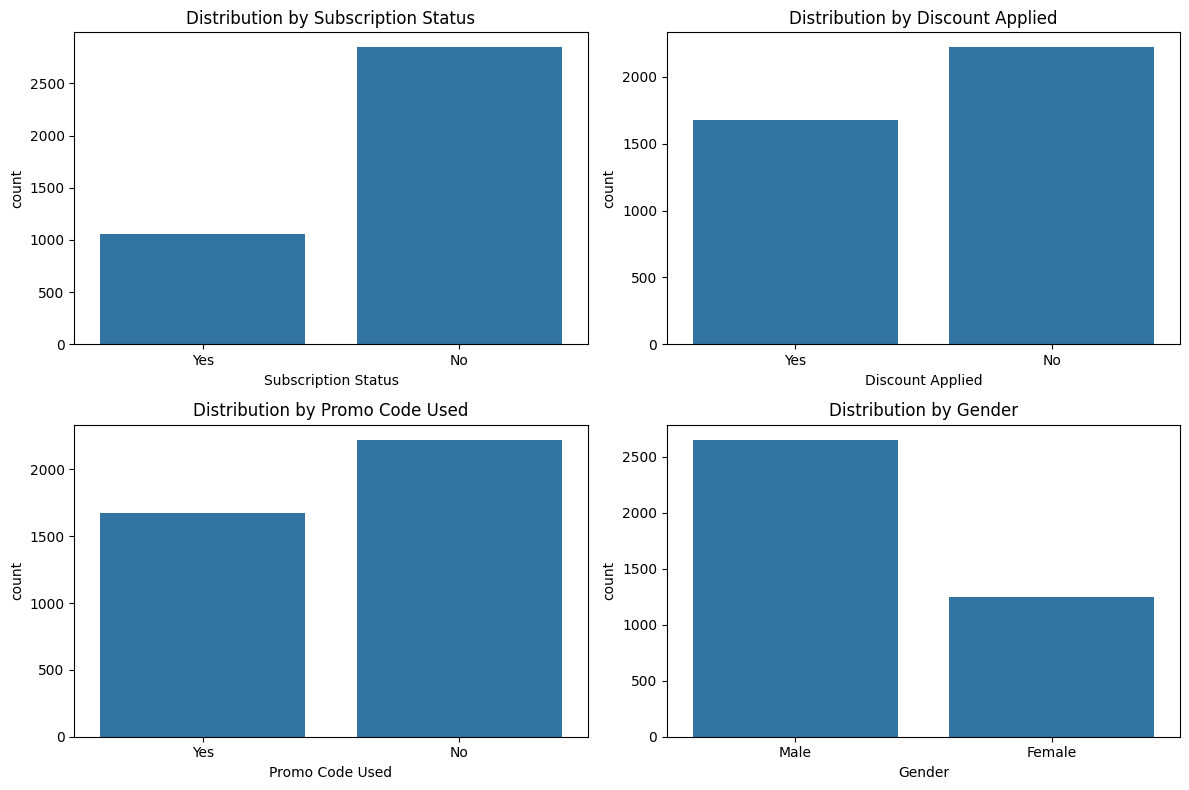

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Distribution by Subscription Status
sns.countplot(x="Subscription Status", data=df, ax=axes[0][0])
axes[0][0].set_title("Distribution by Subscription Status")

# Distribution by Discount Applied
sns.countplot(x="Discount Applied", data=df, ax=axes[0][1])
axes[0][1].set_title("Distribution by Discount Applied")

# Distribution by Promo Code Used
sns.countplot(x="Promo Code Used", data=df, ax=axes[1][0])
axes[1][0].set_title("Distribution by Promo Code Used")

# Distribution by Gender
sns.countplot(x="Gender", data=df, ax=axes[1][1])
axes[1][1].set_title("Distribution by Gender")

plt.tight_layout()
plt.show()

## Relationships between key features

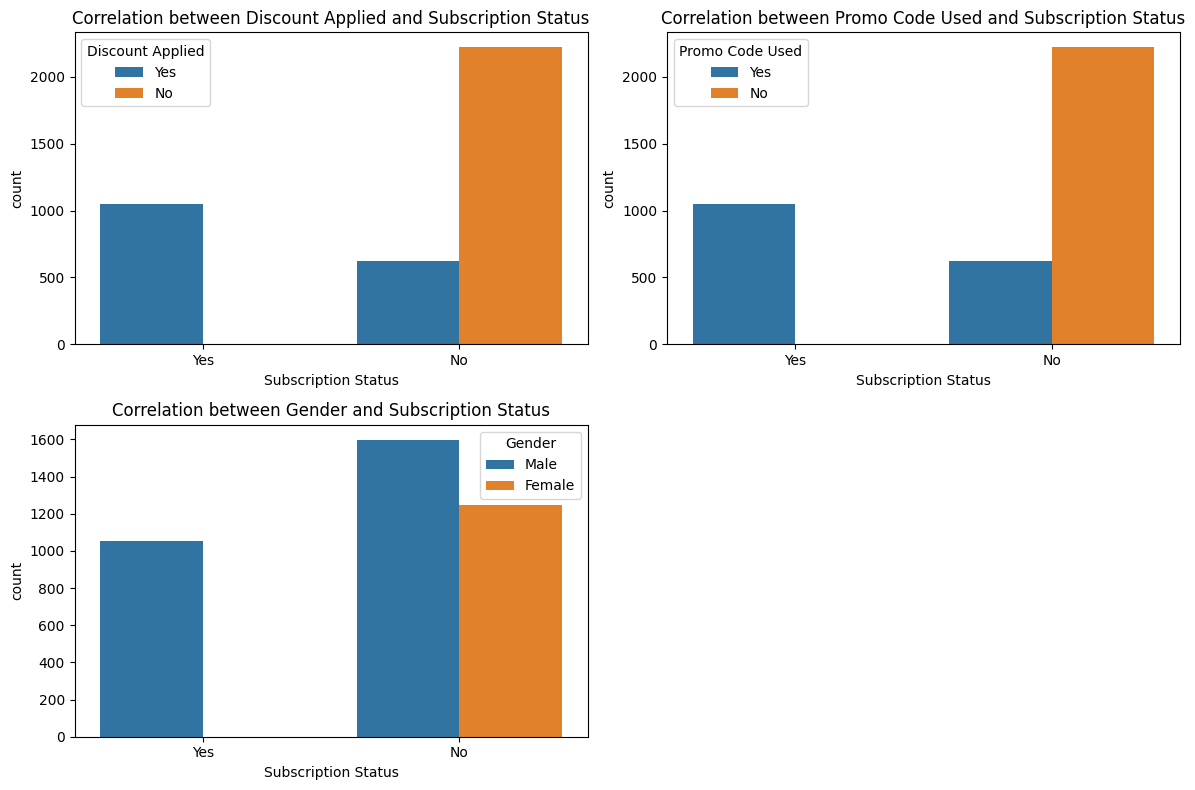

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Discount Applied - Subscription Status
sns.countplot(x="Subscription Status", hue="Discount Applied", data=df, ax=axes[0][0])
axes[0][0].set_title("Correlation between Discount Applied and Subscription Status")

# Promo Code Used - Subscription Status
sns.countplot(x="Subscription Status", hue="Promo Code Used", data=df, ax=axes[0][1])
axes[0][1].set_title("Correlation between Promo Code Used and Subscription Status")

# Gender - Subscription Status
sns.countplot(x="Subscription Status", hue="Gender", data=df, ax=axes[1][0])
axes[1][0].set_title("Correlation between Gender and Subscription Status")

axes[1][1].axis("off")

plt.tight_layout()
plt.show()

It seems Discount Applied and Promo Code Used have the same behaviour, this is obvious since if anyone uses a promo code, he will have a discount.<br>
Now we will directly analise the correlation of these two features.

In [ ]:
ct = pd.crosstab(df['Discount Applied'], df['Promo Code Used'])
ct_norm = pd.crosstab(df['Discount Applied'], df['Promo Code Used'], normalize='index')

# Added suffixes to distinguish them
ct.columns = [f"{col} (count)" for col in ct.columns]
ct_norm.columns = [f"{col} (norm)" for col in ct_norm.columns]

pd.concat([ct, ct_norm], axis=1)

,No (count),Yes (count),No (norm),Yes (norm)
Discount Applied,,,,
No,2223,0,1.0,0.0
Yes,0,1677,0.0,1.0


In the previous image we could also see that when Subscription Status = Yes then Discount Applied (and Promo Code Used) = Yes. This could cause a data leakage problem, where supervised methods could think that this is a bidirectional bound.

# Models

We will apply different models to the dataset:
- Decision Tree
- Logistic Regression
- Support Vector Machines
- Ensemble Methods (Voting, Bagging, Stacking, AdaBoost, RandomForest, ExtraTrees)
- Gradient Boosting
- XGBoost
- Multi Layer Perceptron
- Clustering (K-Means, Bisection K-Means, DBSCAN)<br>

For each model we will first show the baseline model (with default parameters). Then we will try to find an improved version searching the best parameters combination using:
- GridSearchCV
  - Try all possible combinations of the specified hyperparameters.
  - Guarantees the best combination in the grid, but can be very time-consuming.
- RandomizedSearchCV
  - Randomly extracts a limited number of combinations from the hyperparameter distribution.
  - Faster and more suitable for large search spaces, but does not guarantee that all the best combinations will be tried.
- HalvingGridSearchCV
  - More efficient variant of GridSearch: tests many combinations with few resources and discards the worst, progressively increasing resources for the best.
  - Tradeoff between accuracy and computational efficiency.

To compare the performance of the two versions, we will use 4 different metrics:
- accuracy = overall accuracy of predictions
- precision = correct positive predictions / total predicted positives
- recall = correct positive predictions / total actual positives
- f1-score = harmonic mean of precision and recall



## Decision Tree

Default model

In [ ]:
# Training the default Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

# Prediction on test data
y_pred_dt = dt.predict(X_test)

# Default model evaluation
print("Decision Tree Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_dt):.4f}")

Decision Tree Results:
Accuracy: 0.8103
Precision: 0.6667
Recall: 0.5972
F1-Score: 0.6300


### Analysis after tuning

In [ ]:
# Finding the best hyperparameters using Grid Search
dt_params = {
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'ccp_alpha': [0, 0.01, 0.1],
}

grid = GridSearchCV(dt, dt_params, cv=5) # 5-fold cross validation
grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'ccp_alpha': [0, 0.01, 0.1],
                         'max_depth': [3, 5, 7, None],
                         'min_samples_split': [2, 5, 10]})

Best model found with tuning

In [ ]:
best_dt = grid.best_estimator_
y_pred_dt = best_dt.predict(X_test)

# Evaluation of the optimized model
print("Decision Tree Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_dt):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_dt):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_dt):.4f}")

# Showing the parameters chosen by Grid Search
print("Best Params chosen:", grid.best_params_)

Decision Tree Results (Tuned):
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992
Best Params chosen: {'ccp_alpha': 0.01, 'max_depth': 3, 'min_samples_split': 2}


## Logistic Regression

Default model

In [ ]:
# Training the default Logistic Regression
lr = LogisticRegression(max_iter=5000, random_state=42)
lr.fit(X_train, y_train)

# Predictions on the test data
y_pred_lr = lr.predict(X_test)

# Default model evaluation
print("Logistic Regression Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_lr):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_lr):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_lr):.4f}\n")

Logistic Regression Results:
Accuracy: 0.8513
Precision: 0.6806
Recall: 0.8483
F1-Score: 0.7553



### Analysis after tuning

In [ ]:
# Hyperparameter Tuning with Randomized Search
lr_params = {
    'penalty': ['l1', 'l2'], # type of regularization (L1 = Lasso, L2 = Ridge)
    'C': [0.01, 0.1, 1, 10], # regularization strength (lower = stronger penalty)
    'solver': ['saga'],
    'max_iter': [500, 1000, 2000] # number of iterations for convergence
}

random_search = RandomizedSearchCV(LogisticRegression(random_state=42),
                                   param_distributions=lr_params,
                                   n_iter=5, # number of random combinations
                                   cv=3, # fewer folds, 3-fold cross validation
                                   n_jobs=-1, # parallelize
                                   verbose=1,
                                   random_state=42)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


RandomizedSearchCV(cv=3, estimator=LogisticRegression(random_state=42),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'C': [0.01, 0.1, 1, 10],
                                        'max_iter': [500, 1000, 2000],
                                        'penalty': ['l1', 'l2'],
                                        'solver': ['saga']},
                   random_state=42, verbose=1)

Best model found with tuning

In [ ]:
best_lr = random_search.best_estimator_
y_pred_best = best_lr.predict(X_test)

# Evaluation of the optimized model
print("Logistic Regression Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_best):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_best):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_best):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_best):.4f}")

# Display chosen hyperparameters
print("Best Params chosen:", random_search.best_params_)

Logistic Regression Results (Tuned):
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992
Best Params chosen: {'solver': 'saga', 'penalty': 'l1', 'max_iter': 1000, 'C': 0.1}


## SVM (Linear kernel, Polinomial kernel, RBF kernel)

Baseline comparison of different SVM kernels

In [ ]:
# Create three different SVMs:
# - Linear kernel: works well for linearly separable data
# - Polynomial kernel: can capture non-linear relationships (controlled by degree)
# - RBF (Radial Basis Function): very flexible, good default choice for non-linear problems
svm_linear = SVC(kernel='linear', random_state=42)
svm_poly = SVC(kernel='poly', degree=3, random_state=42)
svm_rbf = SVC(kernel='rbf', random_state=42)

# Train and evaluate each kernel on the test set
for svm, name in [(svm_linear, 'Linear SVM'), (svm_poly, 'Polynomial SVM'), (svm_rbf, 'RBF SVM')]:
    svm.fit(X_train, y_train)
    y_pred_svm = svm.predict(X_test)

    print(f"{name} Results:")
    print(f"Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")
    print(f"Precision: {precision_score(y_test, y_pred_svm):.4f}")
    print(f"Recall: {recall_score(y_test, y_pred_svm):.4f}")
    print(f"F1-Score: {f1_score(y_test, y_pred_svm):.4f}\n")

Linear SVM Results:
Accuracy: 0.8667
Precision: 0.6801
Recall: 0.9573
F1-Score: 0.7953

Polynomial SVM Results:
Accuracy: 0.8244
Precision: 0.6623
Recall: 0.7156
F1-Score: 0.6879

RBF SVM Results:
Accuracy: 0.8603
Precision: 0.6667
Recall: 0.9668
F1-Score: 0.7892



### Analysis after tuning: Lineal kernel

In [ ]:
svm_linear_params = {
    'C': [0.1, 1, 10] # regularization parameter (higher = less regularization)
}

grid_linear = GridSearchCV(LinearSVC(random_state=42, max_iter=5000),
                           svm_linear_params, cv=5, n_jobs=-1)
grid_linear.fit(X_train, y_train)


GridSearchCV(cv=5, estimator=LinearSVC(max_iter=5000, random_state=42),
             n_jobs=-1, param_grid={'C': [0.1, 1, 10]})

Best model found with tuning

In [ ]:
svm_linear = grid_linear.best_estimator_
y_pred_linear = svm_linear.predict(X_test)

# Evaluation of the optimized model
print("Linear Kernel SVM Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_linear):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_linear):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_linear):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_linear):.4f}")

# Showing the parameters chosen by the Grid Search
print("Best Parameters:", grid_linear.best_params_)

Linear Kernel SVM Results (Tuned):
Accuracy: 0.8526
Precision: 0.6778
Recall: 0.8673
F1-Score: 0.7609
Best Parameters: {'C': 0.1}


### Analysis after tuning: Polynomial kernel

In [ ]:
svm_polynomial_params = {
    'kernel': ['poly'],
    'C': [0.1, 1, 10], # regularization parameter
    'degree': [2, 3, 4], # polynomia degree
    'gamma': ['scale', 'auto'], # kernel coefficient
    'coef0': [0, 1] # controls the bias influence
}

halving_poly = HalvingGridSearchCV(
    SVC(kernel='poly'),
    svm_polynomial_params,
    factor=2,
    cv=5,
    n_jobs=-1
)
halving_poly.fit(X_train, y_train)

HalvingGridSearchCV(estimator=SVC(kernel='poly'), factor=2, n_jobs=-1,
                    param_grid={'C': [0.1, 1, 10], 'coef0': [0, 1],
                                'degree': [2, 3, 4], 'gamma': ['scale', 'auto'],
                                'kernel': ['poly']})

Best model found with tuning

In [ ]:
svm_poly = halving_poly.best_estimator_
y_pred_poly = svm_poly.predict(X_test)

# Evaluation of the optimized model
print("Polynomial Kernel SVM Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_poly):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_poly):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_poly):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_poly):.4f}")

# Showing the parameters chosen by the Halving Search
print("Best Parameters:", halving_poly.best_params_)

Polynomial Kernel SVM Results (Tuned):
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992
Best Parameters: {'C': 0.1, 'coef0': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'}


### Analysis after tuning: RBF kernel

In [ ]:
# RBF is very sensitive to both C and gamma, so tuning is especially important here
# C -> regularization parameter (higher = less regularization)
# gamma -> kernel coefficient
svm_rbf_params = {
    'kernel': ['rbf'],
    # The range [0.1, 1, 10] is too narrow
    'C': np.logspace(-2, 3, 6), # [0.01, 0.1, 1, 10, 100, 1000]
    'gamma': np.logspace(-3, 2, 6) # [0.001, 0.01, 0.1, 1, 10, 100]
}

from sklearn.model_selection import HalvingGridSearchCV

halving_rbf = HalvingGridSearchCV(
    SVC(kernel='rbf'),
    param_grid=svm_rbf_params,
    factor=2,
    cv=5, # 5-fold cross validation
    n_jobs=-1
)
halving_rbf.fit(X_train, y_train)

HalvingGridSearchCV(estimator=SVC(), factor=2, n_jobs=-1,
                    param_grid={'C': array([1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02, 1.e+03]),
                                'gamma': array([1.e-03, 1.e-02, 1.e-01, 1.e+00, 1.e+01, 1.e+02]),
                                'kernel': ['rbf']})

Best model found with tuning

In [ ]:
svm_rbf = halving_rbf.best_estimator_
y_pred_rbf = svm_rbf.predict(X_test)

# Evaluation of the optimized model
print("RBF Kernel SVM Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rbf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rbf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rbf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rbf):.4f}")

# Showing the parameters chosen by the Halving Search
print("Best Parameters:", halving_rbf.best_params_)

RBF Kernel SVM Results (Tuned):
Accuracy: 0.8205
Precision: 0.6682
Recall: 0.6682
F1-Score: 0.6682
Best Parameters: {'C': np.float64(100.0), 'gamma': np.float64(0.1), 'kernel': 'rbf'}


### Confronting all the SMV

In [ ]:
# Now we search over all three kernel types together to find the overall best SVM model
results = {
    "Linear": {
        "best_params": grid_linear.best_params_,
        "cv_score": grid_linear.best_score_
    },
    "Poly": {
        "best_params": halving_poly.best_params_,
        "cv_score": halving_poly.best_score_
    },
    "RBF": {
        "best_params": halving_rbf.best_params_,
        "cv_score": halving_rbf.best_score_
    }
}

# Display cross-validation results for each kernel
print(f"Tuning:")
for model, info in results.items():
    print(f"{model} -> CV Score: {info['cv_score']:.4f}, Params: {info['best_params']}")

# Evaluate the best model of each kernel on the test set
print(f"\nTesting:")
comparisons = {}
for name, grid in [("Linear", grid_linear), ("Poly", halving_poly), ("RBF", halving_rbf)]:
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    comparisons[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred)
    }

# Print test performance metrics for comparison
for model, metrics in comparisons.items():
    print(f"{model} -> Accuracy: {metrics['Accuracy']:.4f}, F1: {metrics['F1']:.4f}")

Tuning:
Linear -> CV Score: 0.8135, Params: {'C': 0.1}
Poly -> CV Score: 0.8332, Params: {'C': 0.1, 'coef0': 1, 'degree': 2, 'gamma': 'scale', 'kernel': 'poly'}
RBF -> CV Score: 0.8148, Params: {'C': np.float64(100.0), 'gamma': np.float64(0.1), 'kernel': 'rbf'}

Testing:
Linear -> Accuracy: 0.8526, F1: 0.7609
Poly -> Accuracy: 0.8641, F1: 0.7992
RBF -> Accuracy: 0.8205, F1: 0.6682


The RBF kernel outperformed both the Linear and Polynomial kernels, achieving the best cross-validation score and the highest test accuracy and F1-score

## Ensemble Methods

Ensemble methods combine multiple individual models to create a more robust and accurate overall predictive model, leveraging the "wisdom of the crowd" principle to improve performance and reduce errors compared to any single model

### Voting

We will use Decision Tree, Logistic Regression and SVM as hard voting estimators because they are:
- relatively easy to implement and require few resources
- eterogeneous, so it's harder for them to fail all together

Default model

In [ ]:
# Linear kernel was the best svm without tuning
voting = VotingClassifier(
    estimators = [('dt', dt), ('lr', lr), ('svm', svm_linear)],
    voting='hard') # majority rule voting
voting.fit(X_train, y_train)
y_pred_voting = voting.predict(X_test)

# Evaluating the hard voting ensemble on the test set
print("Voting Classifier Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_voting):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_voting):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_voting):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_voting):.4f}\n")

Voting Classifier Results:
Accuracy: 0.8538
Precision: 0.6803
Recall: 0.8673
F1-Score: 0.7625



#### Analysis after tuning

In [ ]:
# Rebuilding the RBF SVM with optimal hyperparameters and enabling probability estimates
# RBF kernel was the best svm with tuning
svm_rbf = SVC(
    kernel='rbf',
    probability=True,  # required for soft voting
    C=halving_rbf.best_params_['C'],
    gamma=halving_rbf.best_params_['gamma'],
    random_state=42
)
svm_rbf.fit(X_train, y_train)

voting = VotingClassifier(
    estimators=[('dt', best_dt), ('lr', best_lr), ('svm', svm_rbf)],
    voting='soft'  # uses predicted probabilities for averaging
)
voting.fit(X_train, y_train)
y_pred_voting = voting.predict(X_test)


To tune the soft voting method we didn't research the best parameters, but we used the best versions of Decision Tree, Logistic Regression and SVM found before

Best model found with tuning

In [ ]:
# Evaluating the soft voting ensemble on the test set
print("VotingClassifier Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_voting):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_voting):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_voting):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_voting):.4f}")

VotingClassifier Results (Tuned):
Accuracy: 0.8538
Precision: 0.6690
Recall: 0.9100
F1-Score: 0.7711


### Bagging

Default model

In [ ]:
# Train a basic Bagging ensemble using a Decision Tree as the base estimator
bagging = BaggingClassifier(estimator=dt, n_estimators=10, random_state=42)
bagging.fit(X_train, y_train)
y_pred_bagging = bagging.predict(X_test)

# Evaluate the performance of the untuned Bagging model
print("Bagging Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bagging):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_bagging):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_bagging):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_bagging):.4f}\n")

Bagging Results:
Accuracy: 0.8282
Precision: 0.6791
Recall: 0.6919
F1-Score: 0.6854



#### Analysis after tuning

In [ ]:
# Define hyperparameter grid for tuning the Bagging ensemble
bagging_params = {
    'n_estimators': [5, 10, 20], # number of base estimators
    'max_samples': [0.5, 0.75, 1.0], # fraction of training samples per estimator
    'max_features': [0.5, 0.75, 1.0] # fraction of features per estimator
}

# Create a BaggingClassifier using the tuned Decision Tree (best_dt)
bagging = BaggingClassifier(estimator=best_dt, random_state=42)

# Perform grid search to find the best Bagging configuration
grid = GridSearchCV(bagging, bagging_params, cv=5)
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=BaggingClassifier(estimator=DecisionTreeClassifier(ccp_alpha=0.01,
                                                                          max_depth=3,
                                                                          random_state=42),
                                         random_state=42),
             param_grid={'max_features': [0.5, 0.75, 1.0],
                         'max_samples': [0.5, 0.75, 1.0],
                         'n_estimators': [5, 10, 20]})

Best model found with tuning

In [ ]:
# Use the best Bagging model found by GridSearchCV
best_bagging = grid.best_estimator_
y_pred_bagging = best_bagging.predict(X_test)

# Evaluate the tuned Bagging model on the test set
print("Bagging Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bagging):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_bagging):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_bagging):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_bagging):.4f}")

# Display the best hyperparameters found
print("Best Bagging params:", grid.best_params_)

Bagging Results (Tuned):
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992
Best Bagging params: {'max_features': 0.5, 'max_samples': 0.5, 'n_estimators': 5}


### Stacking

Default model

In [ ]:
# Basic stacking with two base models (Decision Tree and Logistic Regression)
estimators = [('dt', dt), ('lr', lr)]
stacking = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression())
stacking.fit(X_train, y_train)
y_pred_stacking = stacking.predict(X_test)

# Evaluation of basic stacking model
print("Stacking Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_stacking):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_stacking):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_stacking):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_stacking):.4f}\n")

Stacking Results:
Accuracy: 0.8244
Precision: 0.6713
Recall: 0.6872
F1-Score: 0.6792



#### Analysis after tuning

In [ ]:
# Define a simplified hyperparameter grid for tuning the final estimator
stacking_params = {
    'final_estimator__penalty': ['l1', 'l2'], # use only L2 regularization
    'final_estimator__C': [0.01, 0.1, 1], # reduced range for regularization strength
    'final_estimator__solver': ['saga'] # solver compatible with L2 and large datasets
}

# Use tuned base models and Logistic Regression as final estimator
estimators = [('dt', best_dt), ('lr', best_lr)]
stacking = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(max_iter=1000, n_jobs=-1),
    passthrough=True  # include original features in final estimator
)

# Use StratifiedKFold with fewer splits to reduce runtime
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Perform randomized search with fewer iterations
random_search = RandomizedSearchCV(
    estimator=stacking,
    param_distributions=stacking_params,
    n_iter=3, # fewer combinations to test
    cv=cv,
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=StackingClassifier(estimators=[('dt',
                                                             DecisionTreeClassifier(ccp_alpha=0.01,
                                                                                    max_depth=3,
                                                                                    random_state=42)),
                                                            ('lr',
                                                             LogisticRegression(C=0.1,
                                                                                max_iter=1000,
                                                                                penalty='l1',
                                                                                random_state=42,
                                                                                solver='saga'))],
                                                final_estimator=LogisticRegression(max_iter=1000,
                                                                                   n_jobs=-1),
                                                passthrough=True),
                   n_iter=3, n_jobs=-1,
                   param_distributions={'final_estimator__C': [0.01, 0.1, 1],
                                        'final_estimator__penalty': ['l1',
                                                                     'l2'],
                                        'final_estimator__solver': ['saga']},
                   random_state=42)

Best model found with tuning

In [ ]:
# Evaluate the best stacking model found
best_stacking = random_search.best_estimator_
y_pred_stacking = best_stacking.predict(X_test)

print("Stacking Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_stacking):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_stacking):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_stacking):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_stacking):.4f}")

# Display the best hyperparameters found
print("Best stacking params:", random_search.best_params_)

Stacking Results (Tuned):
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992
Best stacking params: {'final_estimator__solver': 'saga', 'final_estimator__penalty': 'l1', 'final_estimator__C': 0.01}


### AdaBoost

Default model

In [ ]:
# Train a basic AdaBoost classifier with 100 weak learners (default: DecisionTreeClassifier)
adaboost = AdaBoostClassifier(n_estimators=100, random_state=42)
adaboost.fit(X_train, y_train)
y_pred_adaboost = adaboost.predict(X_test)

# Evaluate the performance of the untuned AdaBoost model
print("AdaBoost Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_adaboost):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_adaboost):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_adaboost):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_adaboost):.4f}\n")

AdaBoost Results:
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992



#### Analysis after tuning

In [ ]:
# Define hyperparameter grid for tuning AdaBoost
adaboost_params = {
    'n_estimators': [50, 100, 200], # number of boosting rounds
    'learning_rate': [0.01, 0.1, 1] # weight applied to each weak learner
}

# Initialize AdaBoost classifier for tuning
adaboost = AdaBoostClassifier(random_state=42)

# Perform grid search with 5-fold cross-validation to find best hyperparameters
grid = GridSearchCV(adaboost, adaboost_params, cv=5)
grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=AdaBoostClassifier(random_state=42),
             param_grid={'learning_rate': [0.01, 0.1, 1],
                         'n_estimators': [50, 100, 200]})

Best model found with tuning

In [ ]:
# Use the best AdaBoost model found by GridSearchCV
best_adaboost = grid.best_estimator_
y_pred_adaboost = best_adaboost.predict(X_test)

# Evaluate the tuned AdaBoost model on the test set
print("AdaBoost Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_adaboost):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_adaboost):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_adaboost):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_adaboost):.4f}")

# Display the best hyperparameters selected
print("Best AdaBoost params:", grid.best_params_)

AdaBoost Results (Tuned):
Accuracy: 0.8641
Precision: 0.6656
Recall: 1.0000
F1-Score: 0.7992
Best AdaBoost params: {'learning_rate': 1, 'n_estimators': 100}


### RandomForest

Default model

In [ ]:
# Train a basic Random Forest classifier with 100 trees
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

# Evaluate the performance of the untuned Random Forest model
print("Random Forest Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.4f}")

Random Forest Results:
Accuracy: 0.8513
Precision: 0.6740
Recall: 0.8720
F1-Score: 0.7603


#### Analysis after tuning

In [ ]:
# Define hyperparameter grid for tuning the Random Forest model
rf_params = {
    'n_estimators': [50, 100, 150], # number of trees in the forest
    'max_depth': [10, 20, 30], # maximum depth of each tree
    'min_samples_split': [2, 5], # minimum samples required to split a node
    'max_features': ['sqrt', 'log2'] # number of features to consider at each split
}

random_search = RandomizedSearchCV(RandomForestClassifier(random_state=42),
                                   param_distributions=rf_params,
                                   n_iter=5, # just 5 combinations
                                   cv=3,
                                   n_jobs=-1,
                                   verbose=1,
                                   random_state=42)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'max_depth': [10, 20, 30],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_split': [2, 5],
                                        'n_estimators': [50, 100, 150]},
                   random_state=42, verbose=1)

Best model found with tuning

In [ ]:
# Use the best Random Forest model found by RandomizedSearchCV
best_rf = random_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)

# Evaluate the tuned Random Forest model on the test set
print("Random Forest Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_rf):.4f}")

# Display the best hyperparameters selected by the randomized search
print("Best Random Forest params:", random_search.best_params_)

Random Forest Results (Tuned):
Accuracy: 0.8513
Precision: 0.6667
Recall: 0.9005
F1-Score: 0.7661
Best Random Forest params: {'n_estimators': 100, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 20}


### ExtraTrees

Default model

In [ ]:
# Train a basic ExtraTrees model
et = ExtraTreesClassifier(n_estimators=100, random_state=42)
et.fit(X_train, y_train)
y_pred_et = et.predict(X_test)

# Evaluate the untuned ExtraTrees model
print("ExtraTrees Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_et):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_et):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_et):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_et):.4f}\n")

ExtraTrees Results:
Accuracy: 0.8500
Precision: 0.6836
Recall: 0.8294
F1-Score: 0.7495



#### Analysis after tuning

In [ ]:
# Define a simplified hyperparameter distribution for fast tuning
et_params = {
    'n_estimators': [100, 150, 200], # number of trees
    'max_depth': [None, 10, 20], # tree depth
    'min_samples_split': [2, 5], # minimum samples to split a node
    'max_features': ['sqrt', 'log2'] # number of features to consider at each split
}

# Initialize ExtraTrees for randomized search
et = ExtraTreesClassifier(random_state=42)

# Run RandomizedSearchCV with fewer iterations and folds
random_search = RandomizedSearchCV(
    estimator=et,
    param_distributions=et_params,
    n_iter=5, # test only 5 random combinations
    cv=3, # 3-fold cross-validation for speed
    n_jobs=-1,
    random_state=42
)
random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=3, estimator=ExtraTreesClassifier(random_state=42),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'max_depth': [None, 10, 20],
                                        'max_features': ['sqrt', 'log2'],
                                        'min_samples_split': [2, 5],
                                        'n_estimators': [100, 150, 200]},
                   random_state=42)

Best model found with tuning

In [ ]:
# Evaluate the best ExtraTrees model found
best_et = random_search.best_estimator_
y_pred_et = best_et.predict(X_test)

print("ExtraTrees Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_et):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_et):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_et):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_et):.4f}")

# Display the best hyperparameters selected by the randomized search
print("Best ExtraTrees params:", random_search.best_params_)

ExtraTrees Results (Tuned):
Accuracy: 0.8628
Precision: 0.6699
Recall: 0.9716
F1-Score: 0.7930
Best ExtraTrees params: {'n_estimators': 150, 'min_samples_split': 5, 'max_features': 'sqrt', 'max_depth': 10}


## Gradient Boosting

Default model

In [ ]:
# Initialize the Gradient Boosting classifier with 100 trees and a fixed random seed for reproducibility
gb = GradientBoostingClassifier(n_estimators=100, random_state=42)

# Train the model on the training data
gb.fit(X_train, y_train)

# Predict the labels for the test set
y_pred_gb = gb.predict(X_test)

# Print evaluation metrics for the Gradient Boosting model
print("Gradient Boosting Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_gb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_gb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_gb):.4f}\n")

Gradient Boosting Results:
Accuracy: 0.8449
Precision: 0.6607
Recall: 0.8768
F1-Score: 0.7536



### Analysis after tuning

In [ ]:
# Define the hyperparameter space for randomized search
gb_params = {
    'n_estimators': [50, 100, 150], # Number of boosting stages (trees)
    'learning_rate': [0.05, 0.1, 0.2], # Shrinks contribution of each tree
    'max_depth': [3, 5, 7], # Controls tree complexity
    'subsample': [0.6, 0.8, 1] # Fraction of samples used per tree
}

# Initialize RandomizedSearchCV to explore a few random combinations
random_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42), # Base model
    param_distributions=gb_params, # Hyperparameter space
    n_iter=5, # Number of random combinations to try
    cv=3, # 3-fold cross-validation
    n_jobs=-1, # Use all available CPU cores
    verbose=1, # Show progress during training
    random_state=42 # Ensure reproducibility
)

# Fit the randomized search on the scaled training data
random_search.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


RandomizedSearchCV(cv=3, estimator=GradientBoostingClassifier(random_state=42),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'learning_rate': [0.05, 0.1, 0.2],
                                        'max_depth': [3, 5, 7],
                                        'n_estimators': [50, 100, 150],
                                        'subsample': [0.6, 0.8, 1]},
                   random_state=42, verbose=1)

Best model found with tuning

In [ ]:
# Retrieve the best Gradient Boosting model found during GridSearchCV
best_gb = random_search.best_estimator_

# Use the tuned model to make predictions on the test set
y_pred_gb = best_gb.predict(X_test)

# Print evaluation metrics for the tuned Gradient Boosting model
print("Gradient Boosting Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_gb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_gb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_gb):.4f}")

# Display the best hyperparameters selected during tuning
print("Best GradientBoosting params:", random_search.best_params_)

Gradient Boosting Results (Tuned):
Accuracy: 0.8500
Precision: 0.6556
Recall: 0.9384
F1-Score: 0.7719
Best GradientBoosting params: {'subsample': 0.6, 'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.05}


## XGBoost

Default model

In [ ]:
# Initialize and train the XGBoost classifier
xgb = XGBClassifier(random_state=42)
xgb.fit(X_train, y_train)

# Predict labels for the test set
y_pred_xgb = xgb.predict(X_test)

# Print evaluation metrics for the XGBoost model
print("XGBoost Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_xgb):.4f}")

XGBoost Results:
Accuracy: 0.8179
Precision: 0.6590
Recall: 0.6777
F1-Score: 0.6682


#### Analysis after tuning

In [ ]:
# Define a broader hyperparameter space for randomized search
xgb_params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.05, 0.1, 0.2],
    'max_depth': [3, 5, 7],
    'subsample': [0.6, 0.8, 1.0]
}

# Initialize randomized search with limited iterations
random_search = RandomizedSearchCV(
    estimator=XGBClassifier(random_state=42, eval_metric='logloss'),
    param_distributions=xgb_params,
    n_iter=5, # only 5 random combinations
    cv=3,
    n_jobs=-1,
    verbose=1,
    random_state=42
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=False,
                                           eval_metric='logloss',
                                           feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_cons...
                                           max_delta_step=None, max_depth=None,
                                           max_leaves=None,
                                           min_child_weight=None, missing=nan,
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=None,
                                           num_parallel_tree=None, ...),
                   n_iter=5, n_jobs=-1,
                   param_distributions={'learning_rate': [0.05, 0.1, 0.2],
                                        'max_depth': [3, 5, 7],
                                        'n_estimators': [50, 100, 150],
                                        'subsample': [0.6, 0.8, 1.0]},
                   random_state=42, verbose=1)

Best model found with tuning

In [ ]:
# Retrieve the best XGBoost model found during RandomizedSearchCV
best_xgb = random_search.best_estimator_

# Use the tuned model to make predictions on the test set
y_pred_xgb = best_xgb.predict(X_test)

# Print evaluation metrics for the tuned XGBoost model
print("XGBoost Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_xgb):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_xgb):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_xgb):.4f}")

# Display the best hyperparameters selected during tuning
print("Best XGBoost params:", random_search.best_params_)

XGBoost Results (Tuned):
Accuracy: 0.8474
Precision: 0.6544
Recall: 0.9242
F1-Score: 0.7662
Best XGBoost params: {'subsample': 0.6, 'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.05}


## Multi Layer Perceptron

Default model

In [ ]:
# Initialize a Multi-Layer Perceptron (MLP) classifier with one hidden layer of 100 neurons,
# a maximum of 1000 iterations for training, and a fixed random state for reproducibility
mlp = MLPClassifier(hidden_layer_sizes=(100,), max_iter=1000, random_state=42)

# Train the MLP model using the training data
mlp.fit(X_train, y_train)

# Predict the labels for the test data using the trained MLP model
y_pred_mlp = mlp.predict(X_test)

# Print evaluation metrics to assess the performance of the MLP classifier
print("MLP Results:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_mlp):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mlp):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_mlp):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_mlp):.4f}\n")

MLP Results:
Accuracy: 0.8115
Precision: 0.6569
Recall: 0.6351
F1-Score: 0.6458



### Analysis after tuning

In [ ]:
# Define a reduced hyperparameter grid for faster search
param_grid = {
    'hidden_layer_sizes': [(50,), (100,), (150,), (100, 50)],
    'activation': ['relu', 'tanh'],
    'solver': ['adam', 'sgd'],
    'alpha': [0.0001, 0.001],
    'learning_rate': ['adaptive', 'constant']
}

# Initialize MLP with early stopping and fewer iterations
mlp = MLPClassifier(
    max_iter=1000,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=10
)

# Use RandomizedSearchCV for faster hyperparameter tuning
random_search = RandomizedSearchCV(
    mlp,
    param_grid,
    n_iter=6, # Try 6 random combinations
    cv=3, # Use 3-fold cross-validation
    n_jobs=-1, # Use all available CPU cores
    random_state=42
)

# Fit the model to the scaled training data
random_search.fit(X_train, y_train)

RandomizedSearchCV(cv=3,
                   estimator=MLPClassifier(early_stopping=True, max_iter=1000,
                                           random_state=42),
                   n_iter=6, n_jobs=-1,
                   param_distributions={'activation': ['relu', 'tanh'],
                                        'alpha': [0.0001, 0.001],
                                        'hidden_layer_sizes': [(50,), (100,),
                                                               (150,),
                                                               (100, 50)],
                                        'learning_rate': ['adaptive',
                                                          'constant'],
                                        'solver': ['adam', 'sgd']},
                   random_state=42)

Best model found with tuning

In [ ]:
# Retrieve the best estimator found during hyperparameter tuning
best_mlp = random_search.best_estimator_

# Use the best model to make predictions on the test set
y_pred_mlp = best_mlp.predict(X_test)

# Print evaluation metrics for the tuned MLP model
print("MLP Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test, y_pred_mlp):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_mlp):.4f}")
print(f"Recall: {recall_score(y_test, y_pred_mlp):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred_mlp):.4f}")

# Display the best hyperparameter combination found by RandomizedSearchCV
print("Best MLP params:", random_search.best_params_)


MLP Results (Tuned):
Accuracy: 0.8436
Precision: 0.6816
Recall: 0.7915
F1-Score: 0.7325
Best MLP params: {'solver': 'adam', 'learning_rate': 'adaptive', 'hidden_layer_sizes': (100, 50), 'alpha': 0.0001, 'activation': 'tanh'}


## Clustering

Implementation of unsupervised learning techniques to discover hidden customer segments. Models such as K-Means, Bisecting K-Means, and DBSCAN are applied, with performance evaluated using clustering metrics and visualization tools.<br><br>
To measure clustering methods' goodness we will use the following three metrics:
- Silhouette Score (-1, 1): Measures how similar a point is to its own cluster compared to other clusters (the higher the better)

- Calinski-Harabasz Index: Ratio of between-clusters dispersion to within-cluster dispersion (the higher the better)

- Davies-Bouldin Index: Average similarity between each cluster and its most similar cluster (the lower the better)

### K-Means

Default model

In [ ]:
# K-Means can work with sparse matrices
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans.fit(X_train)
train_labels = kmeans.labels_
test_labels = kmeans.predict(X_test)

# but clustering metrics need dense ones
X_train_dense = X_train.toarray()
X_test_dense = X_test.toarray()

print(f"Train Silhouette Score: {silhouette_score(X_train_dense, train_labels):.4f}")
print(f"Train Calinski-Harabasz Index: {calinski_harabasz_score(X_train_dense, train_labels):.4f}")
print(f"Train Davies-Bouldin Index: {davies_bouldin_score(X_train_dense, train_labels):.4f}")

Train Silhouette Score: 0.0614
Train Calinski-Harabasz Index: 214.8775
Train Davies-Bouldin Index: 3.7973


#### Analysis after tuning

Tuning k

In [ ]:
# Scale the features

# K-Means uses Euclidean distance, so features need to be on the same scale
# StandardScaler centers and scales each feature to mean=0, std=1
X_train_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_dense)


# Test a range of cluster numbers

cluster_range = range(2, 100) # try 2 to 100 clusters

sil_scores = []
ch_scores = []
db_scores = []

for k in cluster_range:
    # Initialize K-Means
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++', # smart initialization to improve convergence
        n_init=30, # run K-Means 30 times to avoid bad local minima
        max_iter=500, # max iterations per run
        random_state=42
    )

    # Fit K-Means
    kmeans.fit(X_scaled)
    labels = kmeans.labels_

    # Compute evaluation metrics
    sil_scores.append(silhouette_score(X_scaled, labels)) # higher is better
    ch_scores.append(calinski_harabasz_score(X_scaled, labels)) # higher is better
    db_scores.append(davies_bouldin_score(X_scaled, labels)) # lower is better


# Display results

print("K | Silhouette | Calinski-Harabasz | Davies-Bouldin")
for i, k in enumerate(cluster_range):
    print(f"{k} | {sil_scores[i]:.4f} | {ch_scores[i]:.2f} | {db_scores[i]:.4f}")

# Identify best k for each metric
best_sil = cluster_range[np.argmax(sil_scores)]
best_ch = cluster_range[np.argmax(ch_scores)]
best_db = cluster_range[np.argmin(db_scores)]

print(f"\nBest k according to Silhouette: {best_sil}")
print(f"Best k according to Calinski-Harabasz: {best_ch}")
print(f"Best k according to Davies-Bouldin: {best_db}")

# Fit final K-Means using the best k (e.g., best silhouette)

final_k = best_sil  # choose metric to prioritize
kmeans_final = KMeans(
    n_clusters=final_k,
    init='k-means++',
    n_init=30,
    max_iter=500,
    random_state=42
)
kmeans_final.fit(X_scaled)

# Labels can now be used for analyses, downstream tasks, or evaluations
final_labels = kmeans_final.labels_
print(f"Final KMeans fitted with k={final_k}")

K | Silhouette | Calinski-Harabasz | Davies-Bouldin
2 | 0.0177 | 56.95 | 7.3270
3 | 0.0311 | 52.69 | 5.0200
4 | 0.0219 | 47.12 | 6.1779
5 | 0.0277 | 44.87 | 5.3659
6 | 0.0270 | 39.86 | 5.4021
7 | 0.0295 | 37.27 | 5.2050
8 | 0.0336 | 37.19 | 4.8689
9 | 0.0386 | 36.51 | 4.8163
10 | 0.0411 | 35.69 | 4.7676
11 | 0.0451 | 35.13 | 4.4703
12 | 0.0496 | 34.63 | 4.3365
13 | 0.0517 | 33.95 | 4.1518
14 | 0.0544 | 34.02 | 4.2030
15 | 0.0572 | 33.67 | 3.9608
16 | 0.0594 | 32.26 | 4.1077
17 | 0.0630 | 32.61 | 3.9186
18 | 0.0651 | 32.03 | 3.9005
19 | 0.0699 | 32.32 | 3.6878
20 | 0.0733 | 32.60 | 3.6936
21 | 0.0709 | 30.90 | 3.6325
22 | 0.0672 | 28.87 | 3.4908
23 | 0.0747 | 29.25 | 3.2728
24 | 0.0780 | 29.60 | 3.3259
25 | 0.0809 | 29.31 | 3.3127
26 | 0.0895 | 29.67 | 3.2465
27 | 0.0935 | 29.94 | 3.2607
28 | 0.0951 | 29.99 | 3.1182
29 | 0.1010 | 30.64 | 2.9288
30 | 0.1114 | 31.21 | 3.0280
31 | 0.1077 | 31.02 | 3.0978
32 | 0.1132 | 31.44 | 3.0686
33 | 0.1208 | 31.77 | 2.9424
34 | 0.1189 | 31.97 | 2.9641

The following graph shows each metric's value in correlation with the number of clusters used

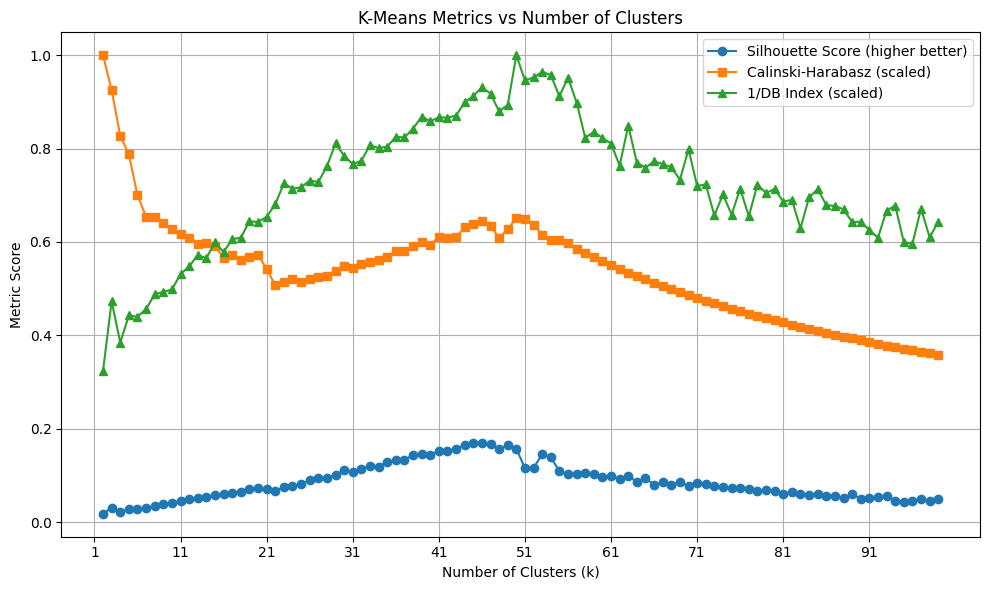

In [ ]:
# Plot metrics for visual inspection
plt.figure(figsize=(10,6))
plt.plot(cluster_range, sil_scores, marker='o', label='Silhouette Score (higher better)')
plt.plot(cluster_range, ch_scores/np.max(ch_scores), marker='s', label='Calinski-Harabasz (scaled)')
plt.plot(cluster_range, (1/np.array(db_scores))/np.max(1/np.array(db_scores)), marker='^', label='1/DB Index (scaled)')


plt.xticks(np.arange(1, 101, 10))

plt.xlabel('Number of Clusters (k)')
plt.ylabel('Metric Score')
plt.title('K-Means Metrics vs Number of Clusters')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Tuning other parameters with the best k found in the previous section

In [ ]:
best_k = 46
print(f"Best k according to silhouette: {best_k}")

# Scale the data
X_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_scaled = StandardScaler().fit_transform(X_dense)

# Parameter grid
inits = ['k-means++', 'random']
n_inits = [10, 20, 30]
max_iters = [300, 500, 700]
best_score = -1
best_params = {}

for init in inits:
    for n_init in n_inits:
        for max_iter in max_iters:
            kmeans = KMeans(n_clusters=best_k, init=init, n_init=n_init, max_iter=max_iter, random_state=42)
            labels = kmeans.fit_predict(X_scaled)
            score = silhouette_score(X_scaled, labels)

            if score > best_score:
                best_score = score
                best_params_fixed= {'init': init, 'n_init': n_init, 'max_iter': max_iter}

print("Best params:", best_params)
print("Best silhouette score:", best_score)
best_score_fixed = best_score
best_kmeans_fixed = KMeans(n_clusters=best_k, **best_params_fixed, random_state=42)
best_kmeans_fixed.fit(X_scaled)

Best k according to silhouette: 46
Best params: {}
Best silhouette score: 0.17030722594957043


KMeans(n_clusters=46, n_init=10, random_state=42)

Combined tuning



In [ ]:

# Prepare data
X_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_scaled = StandardScaler().fit_transform(X_dense)


# Define search space
k_values = range(41, 51)  # k around 46 ±5
inits = ['k-means++', 'random']
n_inits = [10, 20, 30]
max_iters = [300, 500, 700]

# Manual grid search over k and parameters
best_score_var = -1
best_params_var = {}

for k in k_values:
    for init in inits:
        for n_init in n_inits:
            for max_iter in max_iters:
                kmeans = KMeans(
                    n_clusters=k,
                    init=init,
                    n_init=n_init,
                    max_iter=max_iter,
                    random_state=42
                )
                labels = kmeans.fit_predict(X_scaled)
                score = silhouette_score(X_scaled, labels)

                if score > best_score_var:
                    best_score_var = score
                    best_params_var = {
                        'k': k,
                        'init': init,
                        'n_init': n_init,
                        'max_iter': max_iter
                    }


# Fit final KMeans with best parameters
best_kmeans_var = KMeans(
    n_clusters=best_params_var['k'],
    init=best_params_var['init'],
    n_init=best_params_var['n_init'],
    max_iter=best_params_var['max_iter'],
    random_state=42
)
best_kmeans_var.fit(X_scaled)
final_labels_var = best_kmeans_var.labels_

# Print results
print("Best parameters found:")
print(best_params_var)
print("Best silhouette score:", best_score_var)
print(f"Final KMeans fitted with k={best_params_var['k']}")


Best parameters found:
{'k': 46, 'init': 'k-means++', 'n_init': 10, 'max_iter': 300}
Best silhouette score: 0.17030722594957043
Final KMeans fitted with k=46


Best model found with tuning

In [ ]:
# Convert sparse to dense
X_train_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train

print("Confront K-Means Tuned\n")

# ---- k fixed ----
train_labels_fixed = best_kmeans_fixed.labels_
print("Search with fixed k:")
print(f"Best params: {best_params_fixed}")
print(f"Best silhouette score (CV): {best_score_fixed:.4f}")
print(f"Silhouette Train: {silhouette_score(X_train_dense, train_labels_fixed):.4f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_train_dense, train_labels_fixed):.4f}")
print(f"Davies-Bouldin: {davies_bouldin_score(X_train_dense, train_labels_fixed):.4f}")
print("-" * 50)

# ---- k variable ----
train_labels_var = best_kmeans_var.labels_
print("Search with variable k:")
print(f"Best params: {best_params_var}")
print(f"Best silhouette score (CV): {best_score_var:.4f}")
print(f"Silhouette Train: {silhouette_score(X_train_dense, train_labels_var):.4f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_train_dense, train_labels_var):.4f}")
print(f"Davies-Bouldin: {davies_bouldin_score(X_train_dense, train_labels_var):.4f}")


Confront K-Means Tuned

Search with fixed k:
Best params: {'init': 'k-means++', 'n_init': 10, 'max_iter': 300}
Best silhouette score (CV): 0.1703
Silhouette Train: 0.0128
Calinski-Harabasz: 6.5823
Davies-Bouldin: 5.6990
--------------------------------------------------
Search with variable k:
Best params: {'k': 46, 'init': 'k-means++', 'n_init': 10, 'max_iter': 300}
Best silhouette score (CV): 0.1703
Silhouette Train: 0.0128
Calinski-Harabasz: 6.5823
Davies-Bouldin: 5.6990


### Bisecting K-Means

Default model

In [ ]:
bisect_km = BisectingKMeans(n_clusters=2, random_state=42)
bisect_km.fit(X_train)
train_labels_bisect = bisect_km.labels_

# Silhouette accepts sparse
print(f"Train Silhouette Score: {silhouette_score(X_train, train_labels_bisect):.4f}")

# Conversion to dense for CH and DB
X_dense = X_train.toarray()
print(f"Train Calinski-Harabasz Index: {calinski_harabasz_score(X_dense, train_labels_bisect):.4f}")
print(f"Train Davies-Bouldin Index: {davies_bouldin_score(X_dense, train_labels_bisect):.4f}")

Train Silhouette Score: 0.0607
Train Calinski-Harabasz Index: 212.4363
Train Davies-Bouldin Index: 3.8191


#### Analysis after tuning




Tuning k (number of clusters)


In [ ]:
# Scale the features
# KMeans uses Euclidean distance, so features need to be on the same scale
# StandardScaler centers and scales each feature to mean=0, std=1
X_train_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train_dense)


# Test a range of cluster numbers
cluster_range = range(2, 100) # try 2 to 100 clusters

sil_scores = []
ch_scores = []
db_scores = []

for k in cluster_range:

    # Initialize Bisecting K-Means
    bisect_km = BisectingKMeans(n_clusters=k, random_state=42)

    # Fit Bisecting K-Means
    bisect_km.fit(X_scaled)
    labels = bisect_km.labels_

    # Compute evaluation metrics
    sil_scores.append(silhouette_score(X_scaled, labels)) # higher is better
    ch_scores.append(calinski_harabasz_score(X_scaled, labels)) # higher is better
    db_scores.append(davies_bouldin_score(X_scaled, labels)) # lower is better


# Display results
print("K | Silhouette | Calinski-Harabasz | Davies-Bouldin")
for i, k in enumerate(cluster_range):
    print(f"{k} | {sil_scores[i]:.4f} | {ch_scores[i]:.2f} | {db_scores[i]:.4f}")

# Identify best k for each metric
best_sil = cluster_range[np.argmax(sil_scores)]
best_ch = cluster_range[np.argmax(ch_scores)]
best_db = cluster_range[np.argmin(db_scores)]

print(f"\nBest k according to Silhouette: {best_sil}")
print(f"Best k according to Calinski-Harabasz: {best_ch}")
print(f"Best k according to Davies-Bouldin: {best_db}")


# Fit final Bisecting K-Means using the best k (e.g., best silhouette)
final_k = best_sil  # choose metric to prioritize
bisect_km_final = BisectingKMeans(n_clusters=final_k, random_state=42)
bisect_km_final.fit(X_scaled)

# Labels can now be used for analysis, downstream tasks, or evaluation
final_labels = bisect_km_final.labels_
print(f"Final Bisecting K-Means fitted with k={final_k}")

K | Silhouette | Calinski-Harabasz | Davies-Bouldin
2 | 0.0165 | 53.69 | 7.5613
3 | 0.0213 | 50.78 | 6.7271
4 | 0.0169 | 40.86 | 7.1532
5 | 0.0228 | 42.84 | 6.5286
6 | 0.0243 | 39.50 | 6.3214
7 | 0.0276 | 37.48 | 5.8980
8 | 0.0279 | 34.85 | 5.5687
9 | 0.0314 | 34.00 | 5.2932
10 | 0.0269 | 31.74 | 5.4424
11 | 0.0307 | 31.39 | 5.2541
12 | 0.0343 | 31.11 | 5.0975
13 | 0.0384 | 31.09 | 4.9567
14 | 0.0396 | 30.17 | 4.8210
15 | 0.0438 | 30.29 | 4.6996
16 | 0.0480 | 30.43 | 4.5659
17 | 0.0487 | 29.74 | 4.4475
18 | 0.0483 | 28.98 | 4.3379
19 | 0.0485 | 28.38 | 4.2612
20 | 0.0476 | 27.64 | 4.1734
21 | 0.0465 | 27.19 | 4.3365
22 | 0.0504 | 27.54 | 4.2502
23 | 0.0546 | 27.89 | 4.1731
24 | 0.0589 | 28.26 | 4.0925
25 | 0.0613 | 28.28 | 4.0681
26 | 0.0606 | 27.81 | 4.0044
27 | 0.0610 | 27.56 | 4.0057
28 | 0.0601 | 27.07 | 3.9454
29 | 0.0575 | 26.75 | 4.0561
30 | 0.0558 | 26.37 | 4.0610
31 | 0.0555 | 26.04 | 4.1438
32 | 0.0564 | 25.95 | 4.2264
33 | 0.0469 | 25.47 | 4.3574
34 | 0.0449 | 24.82 | 4.4963

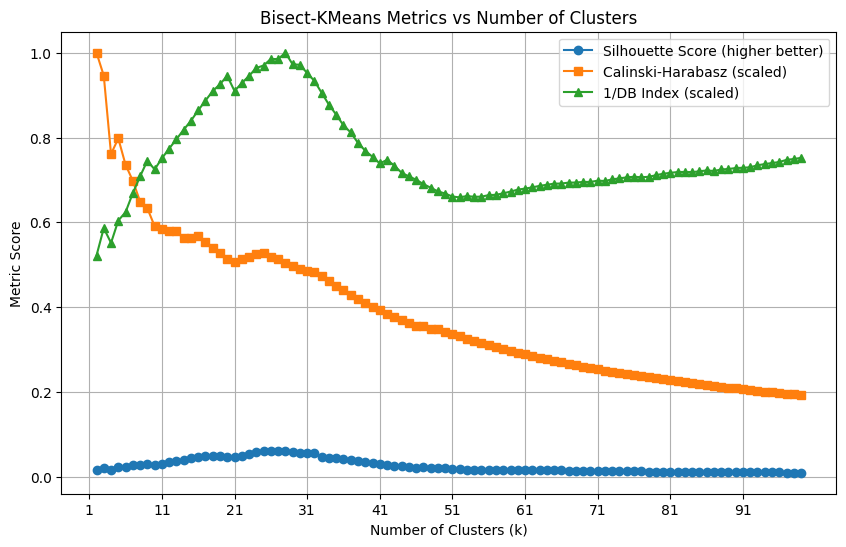

In [ ]:

# Plot metrics for visual inspection
plt.figure(figsize=(10,6))
plt.plot(cluster_range, sil_scores, marker='o', label='Silhouette Score (higher better)')
plt.plot(cluster_range, ch_scores/np.max(ch_scores), marker='s', label='Calinski-Harabasz (scaled)')
plt.plot(cluster_range, (1/np.array(db_scores))/np.max(1/np.array(db_scores)), marker='^', label='1/DB Index (scaled)')

plt.xticks(np.arange(1, 101, 10))
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Metric Score')
plt.title('Bisect-KMeans Metrics vs Number of Clusters')
plt.legend()
plt.grid(True)
plt.show()



Tuning other parameters with the best k found in the previous section


In [ ]:

# Best k chosen from precedent analysis
best_k = final_k
print(f"Best k according to silhouette: {best_k}")


# Input data
# Keep sparse for fitting, but convert convert to dense for CH and DB metrics
X_input = X_train
X_dense = X_input.toarray() if hasattr(X_input, "toarray") else X_input


# GridSearch parameters with fixed k
inits = ["k-means++", "random"]
n_inits = [1, 5, 10]
max_iters = [100, 300, 500]

best_score_fixed = -1
best_params_fixed = {}
best_bisect_kmeans_fixed = None

for init in inits:
    for n_init in n_inits:
        for max_iter in max_iters:
            model = BisectingKMeans(
                n_clusters=best_k,
                init=init,
                n_init=n_init,
                max_iter=max_iter,
                random_state=42
            )
            labels = model.fit_predict(X_input)
            score = silhouette_score(X_dense, labels) # use dense data for silhouette

            if score > best_score_fixed:
                best_score_fixed = score
                best_params_fixed = {'init': init, 'n_init': n_init, 'max_iter': max_iter}
                best_bisect_kmeans_fixed = model

print("Best params (BisectingKMeans, k fisso):", best_params_fixed)
print("Best silhouette score:", best_score_fixed)


# Final fitting for variable k (example variable k = range around best_k)
k_values = range(max(2, best_k-2), best_k+3) # variable k ±2
best_score_var = -1
best_params_var = {}
best_bisect_kmeans_var = None

for k in k_values:
    for n_init in n_inits:
        for max_iter in max_iters:
            model = BisectingKMeans(
                n_clusters=k,
                n_init=n_init,
                max_iter=max_iter,
                random_state=42
            )
            labels = model.fit_predict(X_input)
            score = silhouette_score(X_dense, labels)

            if score > best_score_var:
                best_score_var = score
                best_params_var = {'k': k, 'n_init': n_init, 'max_iter': max_iter}
                best_bisect_kmeans_var = model

print("Best params (BisectingKMeans, k variabile):", best_params_var)
print("Best silhouette score:", best_score_var)

Best k according to silhouette: 25
Best params (BisectingKMeans, k fisso): {'init': 'k-means++', 'n_init': 5, 'max_iter': 100}
Best silhouette score: 0.028031013866828818
Best params (BisectingKMeans, k variabile): {'k': 27, 'n_init': 5, 'max_iter': 100}
Best silhouette score: 0.028692332068450295


Combined tuning

In [ ]:
# Prepare data
X_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train
X_scaled = StandardScaler().fit_transform(X_dense)


# Define search space
k_values = range(2, final_k+5) # example: final_k must be defined
n_inits = [1, 5, 10]
max_iters = [100, 300, 500]


# Grid search over k and parameters
best_score_var = -1
best_params_var = {}
best_bisect_kmeans_var = None

for k in k_values:
    for n_init in n_inits:
        for max_iter in max_iters:
            bisect_kmeans = BisectingKMeans(
                n_clusters=k,
                n_init=n_init,
                max_iter=max_iter,
                random_state=42
            )
            labels = bisect_kmeans.fit_predict(X_scaled)
            score = silhouette_score(X_scaled, labels)

            if score > best_score_var:
                best_score_var = score
                best_params_var = {'k': k, 'n_init': n_init, 'max_iter': max_iter}
                best_bisect_kmeans_var = bisect_kmeans


# Fit final BisectingKMeans with fixed k (example: k=final_k)
best_bisect_kmeans_var = BisectingKMeans(
    n_clusters=final_k, # fixed k
    n_init=best_params_var['n_init'],
    max_iter=best_params_var['max_iter'],
    random_state=42
)
best_bisect_kmeans_var.fit(X_scaled)
best_params_var = {'k': final_k, 'n_init': best_params_var['n_init'], 'max_iter': best_params_var['max_iter']}
best_score_var = silhouette_score(X_scaled, best_bisect_kmeans_var.labels_)

Best model found with tuning

In [ ]:
# Convert sparse to dense for metrics that require array-like
X_train_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train

print("Confront Bisecting K-Means Tuned\n")

# ---- k fixed ----
train_labels_fixed = best_bisect_kmeans_fixed.labels_
print("Search with fixed k:")
print(f"Best params: {best_params_fixed}")
print(f"Best silhouette score (CV): {best_score_fixed:.4f}")
print(f"Silhouette Train: {silhouette_score(X_train_dense, train_labels_fixed):.4f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_train_dense, train_labels_fixed):.4f}")
print(f"Davies-Bouldin: {davies_bouldin_score(X_train_dense, train_labels_fixed):.4f}")
print("-" * 50)

# ---- k variabile ----
train_labels_var = best_bisect_kmeans_var.labels_
print("Search with variable k:")
print(f"Best params: {best_params_var}")
print(f"Best silhouette score (CV): {best_score_var:.4f}")
print(f"Silhouette Train: {silhouette_score(X_train_dense, train_labels_var):.4f}")
print(f"Calinski-Harabasz: {calinski_harabasz_score(X_train_dense, train_labels_var):.4f}")
print(f"Davies-Bouldin: {davies_bouldin_score(X_train_dense, train_labels_var):.4f}")

Confront Bisecting K-Means Tuned

Search with fixed k:
Best params: {'init': 'k-means++', 'n_init': 5, 'max_iter': 100}
Best silhouette score (CV): 0.0280
Silhouette Train: 0.0280
Calinski-Harabasz: 51.7079
Davies-Bouldin: 3.5550
--------------------------------------------------
Search with variable k:
Best params: {'k': 25, 'n_init': 1, 'max_iter': 100}
Best silhouette score (CV): 0.0613
Silhouette Train: 0.0192
Calinski-Harabasz: 18.9290
Davies-Bouldin: 5.0179


### DBSCAN

Default model

Best parameters -> eps: 0.94, min_samples: 3
Number of clusters found: 2
Best Silhouette Score: 0.0058


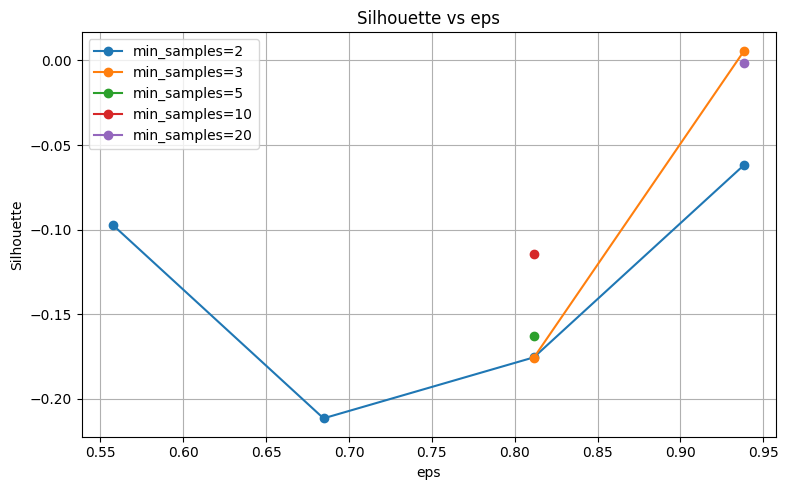

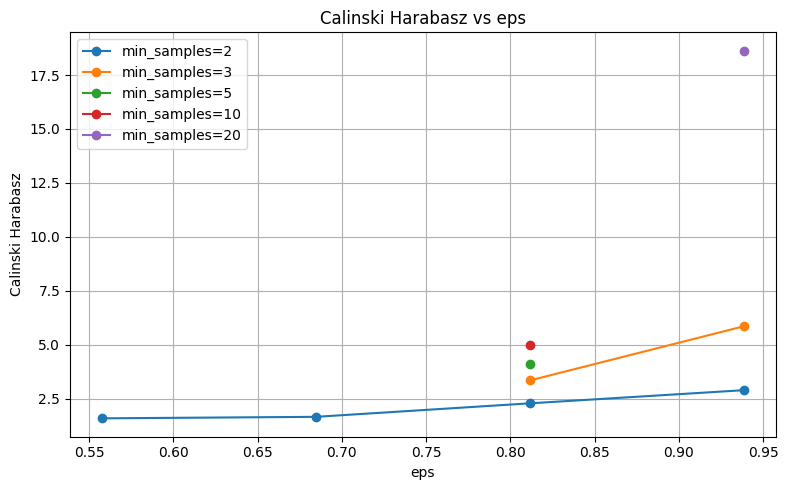

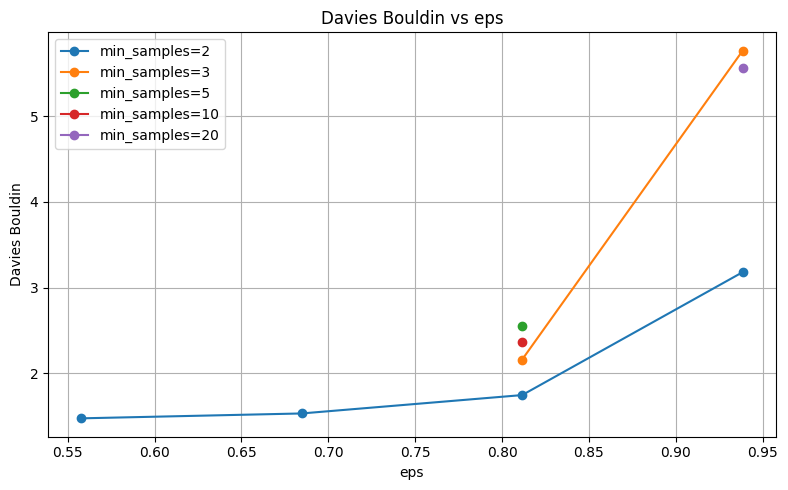

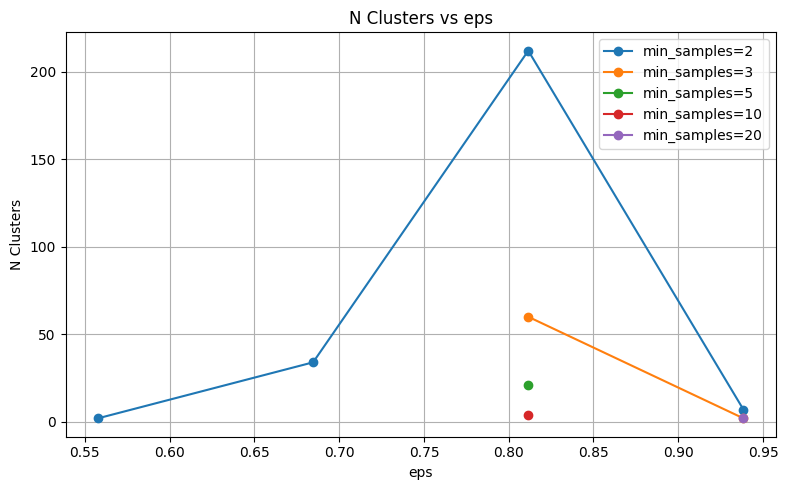

In [ ]:
# Scale the data
X_scaled = Normalizer().fit_transform(X_train)
X_dense = X_scaled.toarray() if hasattr(X_scaled, "toarray") else X_scaled

# Automatic parameter search
best_score = -1
best_params = None
best_labels = None

min_samples_values = [2, 3, 5, 10, 20]
eps_values = np.linspace(0.05, 5.0, 40)

# --- collect results ---
results = []

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(X_scaled)

        # Count the number of clusters (ignore noise label -1)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

        if n_clusters > 1:  # Only consider meaningful clusterings
            sil = silhouette_score(X_scaled, labels)
            ch = calinski_harabasz_score(X_dense, labels)
            db = davies_bouldin_score(X_dense, labels)

            results.append({
                "eps": eps,
                "min_samples": min_samples,
                "silhouette": sil,
                "calinski_harabasz": ch,
                "davies_bouldin": db,
                "n_clusters": n_clusters
            })

            # Track the best clustering based on silhouette score
            if sil > best_score:
                best_score = sil
                best_params = (eps, min_samples)
                best_labels = labels

# Final results
if best_params:
    eps, min_samples = best_params
    print(f"Best parameters -> eps: {eps:.2f}, min_samples: {min_samples}")
    print(f"Number of clusters found: {len(set(best_labels)) - (1 if -1 in best_labels else 0)}")
    print(f"Best Silhouette Score: {best_score:.4f}")
else:
    print("No meaningful clustering found.")

# Visualization
if results:
    df = pd.DataFrame(results)
    metrics = ["silhouette", "calinski_harabasz", "davies_bouldin", "n_clusters"]

    for metric in metrics:
        plt.figure(figsize=(8,5))
        for ms in df["min_samples"].unique():
            subset = df[df["min_samples"] == ms]
            plt.plot(subset["eps"], subset[metric], marker="o", label=f"min_samples={ms}")
        plt.xlabel("eps")
        plt.ylabel(metric.replace("_", " ").title())
        plt.title(f"{metric.replace('_', ' ').title()} vs eps")
        plt.legend()
        plt.grid(True)
        plt.tight_layout()
        plt.show()

best_dbscan_labels = best_labels

These graphs show the correlation between the eps (radius of the area within which the points are located) and the 3 metrics and the number of clusters

# Confront between all models

##Classification methods

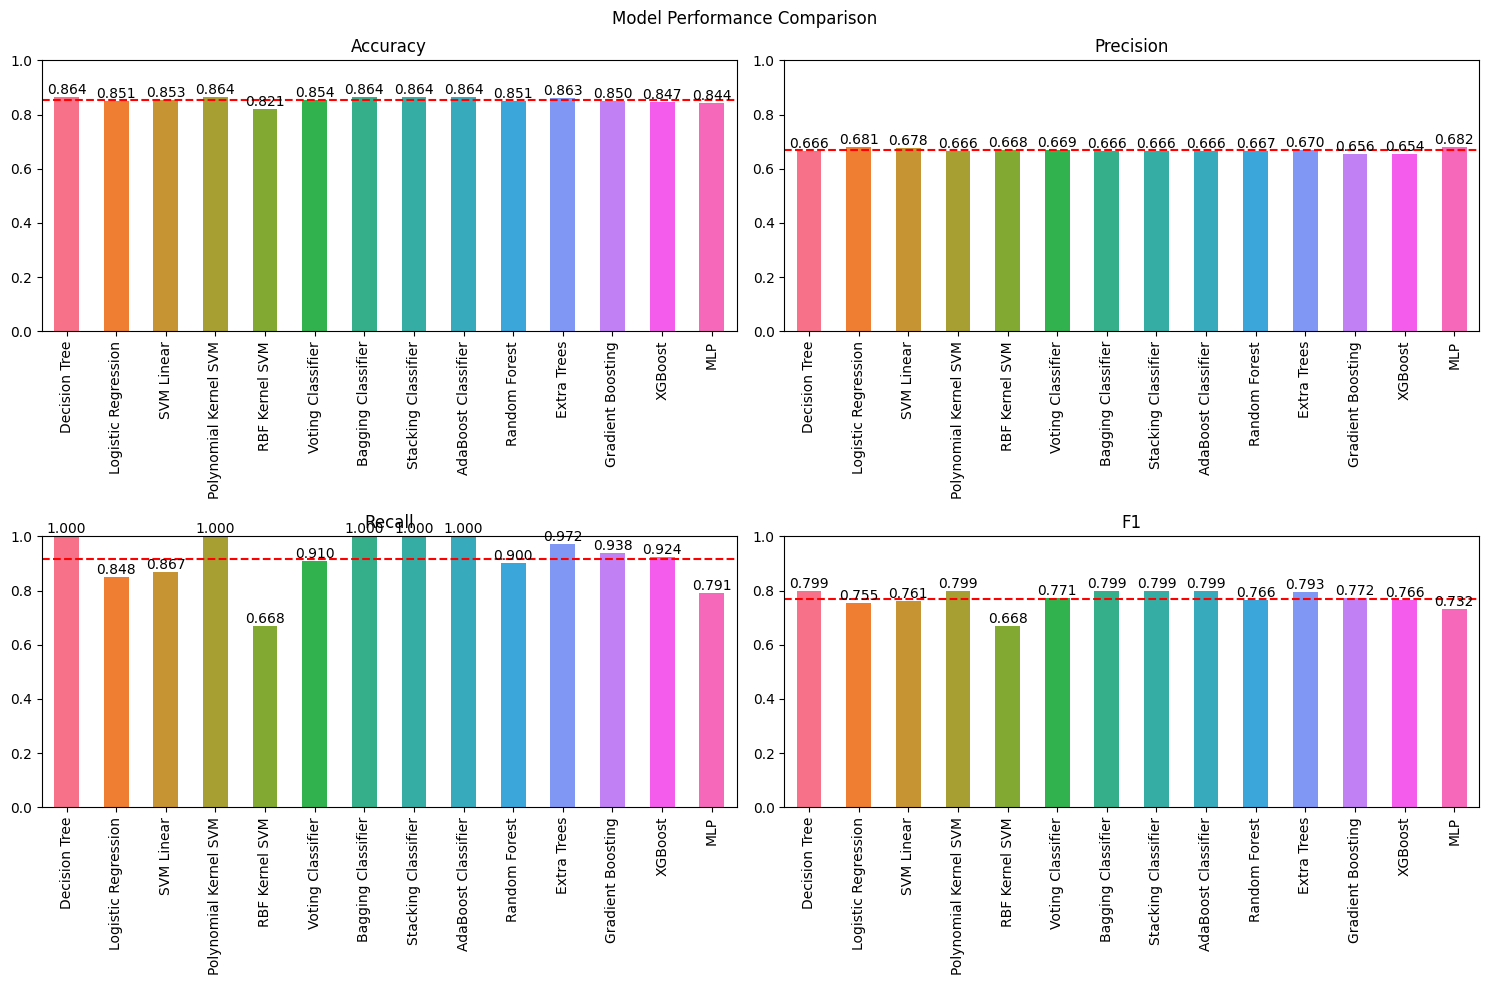

,Accuracy,Precision,Recall,F1,Params
Decision Tree,0.864,0.666,1.000,0.799,"{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}"
Logistic Regression,0.851,0.681,0.848,0.755,"{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 5000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}"
SVM Linear,0.853,0.678,0.867,0.761,"{'C': 0.1, 'class_weight': None, 'dual': 'auto', 'fit_intercept': True, 'intercept_scaling': 1, 'loss': 'squared_hinge', 'max_iter': 5000, 'multi_class': 'ovr', 'penalty': 'l2', 'random_state': 42, 'tol': 0.0001, 'verbose': 0}"
Polynomial Kernel SVM,0.864,0.666,1.000,0.799,"{'C': 0.1, 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 1, 'decision_function_shape': 'ovr', 'degree': 2, 'gamma': 'scale', 'kernel': 'poly', 'max_iter': -1, 'probability': False, 'random_state': None, 'shrinking': True, 'tol': 0.001, 'verbose': False}"
RBF Kernel SVM,0.821,0.668,0.668,0.668,"{'C': np.float64(100.0), 'break_ties': False, 'cache_size': 200, 'class_weight': None, 'coef0': 0.0, 'decision_function_shape': 'ovr', 'degree': 3, 'gamma': np.float64(0.1), 'kernel': 'rbf', 'max_iter': -1, 'probability': True, 'random_state': 42, 'shrinking': True, 'tol': 0.001, 'verbose': False}"
Voting Classifier,0.854,0.669,0.910,0.771,"{'estimators': [('dt', DecisionTreeClassifier(ccp_alpha=0.01, max_depth=3, random_state=42)), ('lr', LogisticRegression(C=0.1, max_iter=1000, penalty='l1', random_state=42, solver='saga')), ('svm', SVC(C=np.float64(100.0), gamma=np.float64(0.1), probability=True, random_state=42))], 'flatten_transform': True, 'n_jobs': None, 'verbose': False, 'voting': 'soft', 'weights': None, 'dt': DecisionTreeClassifier(ccp_alpha=0.01, max_depth=3, random_state=42), 'lr': LogisticRegression(C=0.1, max_iter=1000, penalty='l1', random_state=42, solver='saga'), 'svm': SVC(C=np.float64(100.0), gamma=np.float64(0.1), probability=True, random_state=42), 'dt__ccp_alpha': 0.01, 'dt__class_weight': None, 'dt__criterion': 'gini', 'dt__max_depth': 3, 'dt__max_features': None, 'dt__max_leaf_nodes': None, 'dt__min_impurity_decrease': 0.0, 'dt__min_samples_leaf': 1, 'dt__min_samples_split': 2, 'dt__min_weight_fraction_leaf': 0.0, 'dt__monotonic_cst': None, 'dt__random_state': 42, 'dt__splitter': 'best', 'lr__C': 0.1, 'lr__class_weight': None, 'lr__dual': False, 'lr__fit_intercept': True, 'lr__intercept_scaling': 1, 'lr__l1_ratio': None, 'lr__max_iter': 1000, 'lr__multi_class': 'deprecated', 'lr__n_jobs': None, 'lr__penalty': 'l1', 'lr__random_state': 42, 'lr__solver': 'saga', 'lr__tol': 0.0001, 'lr__verbose': 0, 'lr__warm_start': False, 'svm__C': np.float64(100.0), 'svm__break_ties': False, 'svm__cache_size': 200, 'svm__class_weight': None, 'svm__coef0': 0.0, 'svm__decision_function_shape': 'ovr', 'svm__degree': 3, 'svm__gamma': np.float64(0.1), 'svm__kernel': 'rbf', 'svm__max_iter': -1, 'svm__probability': True, 'svm__random_state': 42, 'svm__shrinking': True, 'svm__tol': 0.001, 'svm__verbose': False}"
Bagging Classifier,0.864,0.666,1.000,0.799,"{'bootstrap': True, 'bootstrap_features': False, 'estimator__ccp_alpha': 0.01, 'estimator__class_weight': None, 'estimator__criterion': 'gini', 'estimator__max_depth': 3, 'estimator__max_features': None, 'estimator__max_leaf_nodes': None, 'estimator__min_impurity_decrease': 0.0, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 2, 'estimator__min_weight_fraction_leaf': 0.0, 'estimator__monotonic_cst': None, 'estimator__random_state': 42, 'estimator__splitter': 'best', 'estimator': DecisionTreeClassifier(ccp_alpha=0.01, max_depth=3, random_state=42), '

In [ ]:
# Collecting the results from all classification models
results = {
    'Decision Tree': {
        'Accuracy': accuracy_score(y_test, y_pred_dt),
        'Precision': precision_score(y_test, y_pred_dt),
        'Recall': recall_score(y_test, y_pred_dt),
        'F1': f1_score(y_test, y_pred_dt),
        'Params': dt.get_params()
    },
    'Logistic Regression': {
        'Accuracy': accuracy_score(y_test, y_pred_lr),
        'Precision': precision_score(y_test, y_pred_lr),
        'Recall': recall_score(y_test, y_pred_lr),
        'F1': f1_score(y_test, y_pred_lr),
        'Params': lr.get_params()
    },
    'SVM Linear': {
        'Accuracy': accuracy_score(y_test, y_pred_linear),
        'Precision': precision_score(y_test, y_pred_linear),
        'Recall': recall_score(y_test, y_pred_linear),
        'F1': f1_score(y_test, y_pred_linear),
        'Params': svm_linear.get_params()
    },
    'Polynomial Kernel SVM': {
        'Accuracy': accuracy_score(y_test, y_pred_poly),
        'Precision': precision_score(y_test, y_pred_poly),
        'Recall': recall_score(y_test, y_pred_poly),
        'F1': f1_score(y_test, y_pred_poly),
        'Params': svm_poly.get_params()
    },
    'RBF Kernel SVM': {
        'Accuracy': accuracy_score(y_test, y_pred_rbf),
        'Precision': precision_score(y_test, y_pred_rbf),
        'Recall': recall_score(y_test, y_pred_rbf),
        'F1': f1_score(y_test, y_pred_rbf),
        'Params': svm_rbf.get_params()
    },
    'Voting Classifier': {
        'Accuracy': accuracy_score(y_test, y_pred_voting),
        'Precision': precision_score(y_test, y_pred_voting),
        'Recall': recall_score(y_test, y_pred_voting),
        'F1': f1_score(y_test, y_pred_voting),
        'Params': voting.get_params()
    },
    'Bagging Classifier': {
        'Accuracy': accuracy_score(y_test, y_pred_bagging),
        'Precision': precision_score(y_test, y_pred_bagging),
        'Recall': recall_score(y_test, y_pred_bagging),
        'F1': f1_score(y_test, y_pred_bagging),
        'Params': bagging.get_params()
    },
    'Stacking Classifier': {
        'Accuracy': accuracy_score(y_test, y_pred_stacking),
        'Precision': precision_score(y_test, y_pred_stacking),
        'Recall': recall_score(y_test, y_pred_stacking),
        'F1': f1_score(y_test, y_pred_stacking),
        'Params': stacking.get_params()
    },
    'AdaBoost Classifier': {
        'Accuracy': accuracy_score(y_test, y_pred_adaboost),
        'Precision': precision_score(y_test, y_pred_adaboost),
        'Recall': recall_score(y_test, y_pred_adaboost),
        'F1': f1_score(y_test, y_pred_adaboost),
        'Params': adaboost.get_params()
    },
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'Precision': precision_score(y_test, y_pred_rf),
        'Recall': recall_score(y_test, y_pred_rf),
        'F1': f1_score(y_test, y_pred_rf),
        'Params': rf.get_params()
    },
    'Extra Trees': {
        'Accuracy': accuracy_score(y_test, y_pred_et),
        'Precision': precision_score(y_test, y_pred_et),
        'Recall': recall_score(y_test, y_pred_et),
        'F1': f1_score(y_test, y_pred_et),
        'Params': et.get_params()
    },
    'Gradient Boosting': {
        'Accuracy': accuracy_score(y_test, y_pred_gb),
        'Precision': precision_score(y_test, y_pred_gb),
        'Recall': recall_score(y_test, y_pred_gb),
        'F1': f1_score(y_test, y_pred_gb),
        'Params': gb.get_params()
    },
    'XGBoost': {
        'Accuracy': accuracy_score(y_test, y_pred_xgb),
        'Precision': precision_score(y_test, y_pred_xgb),
        'Recall': recall_score(y_test, y_pred_xgb),
        'F1': f1_score(y_test, y_pred_xgb),
        'Params': xgb.get_params()
    },
    'MLP': {
        'Accuracy': accuracy_score(y_test, y_pred_mlp),
        'Precision': precision_score(y_test, y_pred_mlp),
        'Recall': recall_score(y_test, y_pred_mlp),
        'F1': f1_score(y_test, y_pred_mlp),
        'Params': mlp.get_params()
    }
}

# Creating a metrics comparison dataframe
metrics_df = pd.DataFrame.from_dict({k: v for k,v in results.items() if k != 'Params'}, orient='index')

# Plotting
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Model Performance Comparison')

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1']
colors = sns.color_palette("husl", len(metrics_df))

for ax, metric in zip(axes.flatten(), metrics_to_plot):
    metrics_df[metric].plot(kind='bar', ax=ax, color=colors)
    ax.set_title(metric)
    ax.set_ylim(0, 1)
    ax.axhline(metrics_df[metric].mean(), color='red', linestyle='--')
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}",
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

# Creating a comparison table
comparison_table = metrics_df.copy()

styled_table = comparison_table.style\
    .background_gradient(
        cmap='Blues',
        subset=['Accuracy', 'Precision', 'Recall', 'F1']
    )\
    .format(
        "{:.3f}",
        subset=['Accuracy', 'Precision', 'Recall', 'F1']
    )\
    .set_properties(
        **{'text-align': 'center',
           'font-family': 'Arial',
           'font-size': '12px'}
    )\
    .set_table_styles([
        {'selector': 'th',
         'props': [('background-color', '#4472C4'),
                   ('color', 'white'),
                   ('font-weight', 'bold'),
                   ('text-align', 'center')]},
        {'selector': 'tr:hover',
         'props': [('background-color', '#FFFFE0')]}
    ])\
    .set_caption(
        "Model Performance Comparison"
    )\
    .highlight_max(
        subset=['Accuracy', 'Precision', 'Recall', 'F1'],
        color='blue'
    )\
    .highlight_min(
        subset=['Accuracy', 'Precision', 'Recall', 'F1'],
        color='purple'
    )

display(styled_table)


# Saving the table
with open("formattedTable.html", "w", encoding="utf-8") as f:
    f.write(styled_table.to_html())

In [ ]:
files.download("formattedTable.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Clustering methods

In [ ]:
# Convert sparse to dense if necessary
X_train_dense = X_train.toarray() if hasattr(X_train, "toarray") else X_train

# Labels from your models
train_labels_kmeans = best_kmeans_fixed.labels_
train_labels_bisect = best_bisect_kmeans_var.labels_
train_labels_dbscan = best_dbscan_labels

clustering_results = {
    'K-Means': {
        'Silhouette': float(silhouette_score(X_train_dense, train_labels_kmeans)),
        'Calinski-Harabasz': float(calinski_harabasz_score(X_train_dense, train_labels_kmeans)),
        'Davies-Bouldin': float(davies_bouldin_score(X_train_dense, train_labels_kmeans))
    },
    'Bisecting K-Means': {
        'Silhouette': float(silhouette_score(X_train_dense, train_labels_bisect)),
        'Calinski-Harabasz': float(calinski_harabasz_score(X_train_dense, train_labels_bisect)),
        'Davies-Bouldin': float(davies_bouldin_score(X_train_dense, train_labels_bisect))
    },
    'DBSCAN': {
        'Silhouette': float(silhouette_score(X_train_dense, train_labels_dbscan)),
        'Calinski-Harabasz': float(calinski_harabasz_score(X_train_dense, train_labels_dbscan)),
        'Davies-Bouldin': float(davies_bouldin_score(X_train_dense, train_labels_dbscan))
    }
}

# Print nicely formatted results
for method, metrics in clustering_results.items():
    print(f"{method}:")
    for metric_name, value in metrics.items():
        print(f"  {metric_name}: {value:.4f}")


K-Means:
  Silhouette: 0.0128
  Calinski-Harabasz: 6.5823
  Davies-Bouldin: 5.6990
Bisecting K-Means:
  Silhouette: 0.0192
  Calinski-Harabasz: 18.9290
  Davies-Bouldin: 5.0179
DBSCAN:
  Silhouette: -0.0502
  Calinski-Harabasz: 5.9907
  Davies-Bouldin: 5.1970


K-Means → Very poor clustering: near-zero Silhouette (0.0128) and high Davies-Bouldin (5.6990) indicate no clear cluster separation.

Bisecting K-Means → Slightly better: higher Silhouette (0.0192) and much better Calinski-Harabasz (18.9290), though Davies-Bouldin (5.0179) still signals weak compactness/separation.

DBSCAN → Performs the worst: negative Silhouette (-0.0502) means clusters are overlapping or poorly assigned; Davies-Bouldin (5.1970) and low Calinski-Harabasz (5.9907) confirm weak structure.

 Overall: Bisecting K-Means > K-Means > DBSCAN, but none show strong clustering quality.

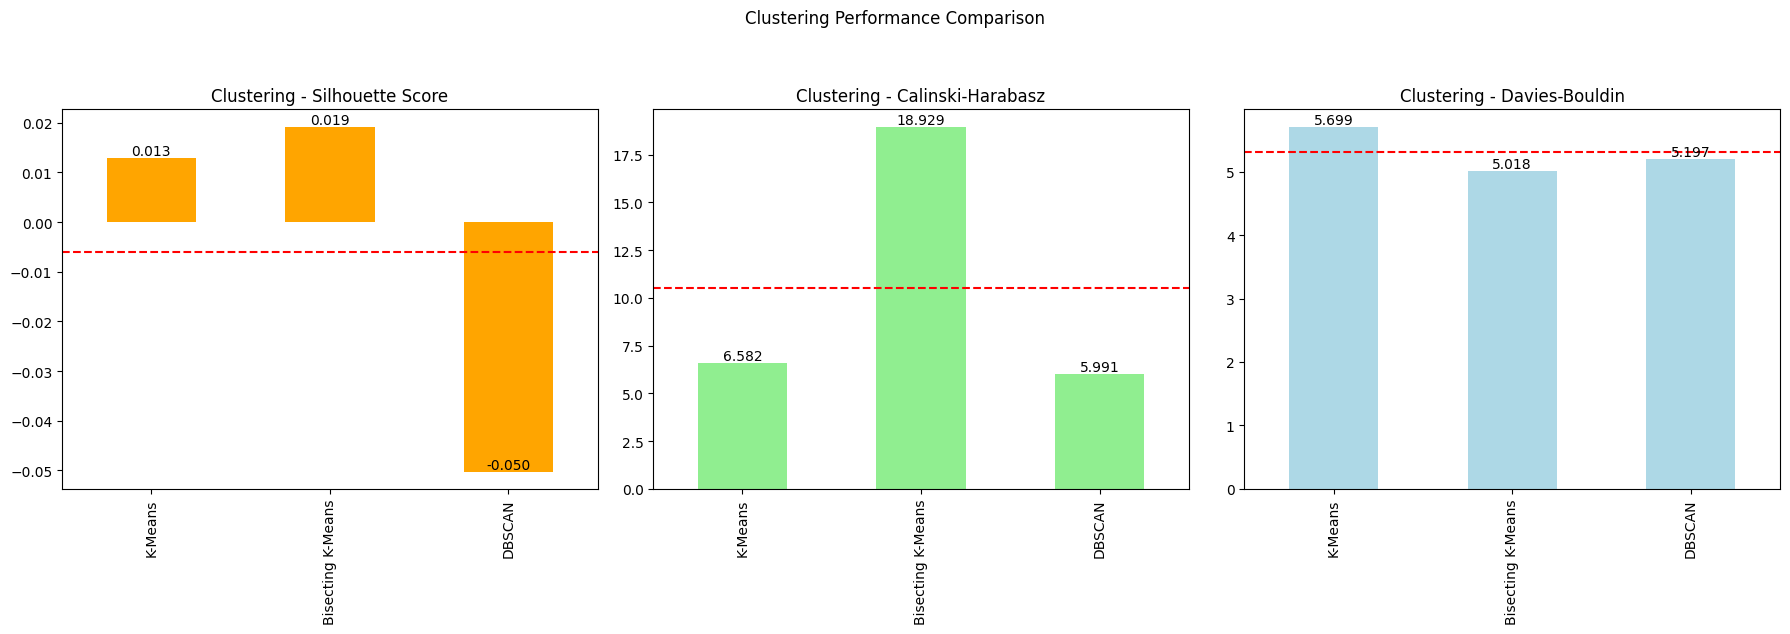

In [ ]:
# Plot Clustering metrics
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
clustering_df = pd.DataFrame.from_dict(clustering_results, orient='index')

# Silhouette Score (Higher is better)
clustering_df['Silhouette'].plot(kind='bar', ax=axes[0], color='orange')
axes[0].set_title('Clustering - Silhouette Score')
axes[0].axhline(clustering_df['Silhouette'].mean(), color='red', linestyle='--')

# Calinski-Harabasz (Higher is better)
clustering_df['Calinski-Harabasz'].plot(kind='bar', ax=axes[1], color='lightgreen')
axes[1].set_title('Clustering - Calinski-Harabasz')
axes[1].axhline(clustering_df['Calinski-Harabasz'].mean(), color='red', linestyle='--')

# Davies-Bouldin (Lower is better)
clustering_df['Davies-Bouldin'].plot(kind='bar', ax=axes[2], color='lightblue')
axes[2].set_title('Clustering - Davies-Bouldin')
axes[2].axhline(clustering_df['Davies-Bouldin'].mean(), color='red', linestyle='--')

# Add value annotations
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}",
                   (p.get_x() + p.get_width() / 2., p.get_height()),
                   ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.suptitle('Clustering Performance Comparison', y=1.05)
plt.tight_layout()
plt.show()


In [ ]:
display(clustering_df.style
       .background_gradient(cmap='Greens', subset=['Silhouette', 'Calinski-Harabasz'])
       .background_gradient(cmap='Reds_r', subset=['Davies-Bouldin']) # Reverse cmap for DB (lower is better)
       .format("{:.3f}"))

,Silhouette,Calinski-Harabasz,Davies-Bouldin
K-Means,0.013,6.582,5.699
Bisecting K-Means,0.019,18.929,5.018
DBSCAN,-0.050,5.991,5.197


# Removing some features

Until now we applied each model using all of the database's features. Now we will try to remove some of them to see if we can get a better analysis. For this task we chose one of the most used methods in machine learning: Decision Tree

In [ ]:
# Percentages of features to keep
percentages = [1, 0.75, 0.5, 0.25, 0.05]
results = {}

# Encode target labels on the full dataset first
le = LabelEncoder()
y_encoded = le.fit_transform(y)

for p in percentages:
    k = max(1, int(X_processed.shape[1] * p)) # Calcolates the number of features to keep
    selector = SelectKBest(score_func=f_classif, k=k)
    X_selected = selector.fit_transform(X_processed, y_encoded)

    # Train-test split
    X_train_k, X_test_k, y_train_k, y_test_k = train_test_split(
        X_selected, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
    )

    # No need to encode here again as y_encoded is already encoded
    # y_train_k = le.transform(y_train_k)
    # y_test_k = le.transform(y_test_k)

    # Train and evaluate
    clf = DecisionTreeClassifier(random_state=42)
    clf.fit(X_train_k, y_train_k)
    y_pred_k = clf.predict(X_test_k)

    # Save metrics
    results[f"{int(p*100)}% features"] = {
        "Accuracy": accuracy_score(y_test_k, y_pred_k),
        "Precision": precision_score(y_test_k, y_pred_k),
        "Recall": recall_score(y_test_k, y_pred_k),
        "F1-score": f1_score(y_test_k, y_pred_k)
    }

# Print results
for label, metrics in results.items():
    print(f"\n--- Model with {label} ---")
    for k, v in metrics.items():
        print(f"{k}: {v:.4f}")


--- Model with 100% features ---
Accuracy: 0.8103
Precision: 0.6667
Recall: 0.5972
F1-score: 0.6300

--- Model with 75% features ---
Accuracy: 0.8077
Precision: 0.6723
Recall: 0.5640
F1-score: 0.6134

--- Model with 50% features ---
Accuracy: 0.8000
Precision: 0.6440
Recall: 0.5829
F1-score: 0.6119

--- Model with 25% features ---
Accuracy: 0.8128
Precision: 0.6923
Recall: 0.5545
F1-score: 0.6158

--- Model with 5% features ---
Accuracy: 0.8436
Precision: 0.6692
Recall: 0.8341
F1-score: 0.7426


Sometimes removing the least significative features, thanks to selectKBest, betters the analysis because of:
- noise reduction
- less risk of overfitting
- better interpretability and stability
- computational efficiency
- redundant features

# Without top features

In this section, we investigate how strongly our model depends on the two dominant features: Promo Code Used and Discount Applied.
Preliminary analysis showed that the dataset is highly influenced by these variables, as both are strongly correlated with the target (Subscription Status).

To assess the model’s robustness and the relative importance of other features, we train a new version of the model after removing these two features from the dataset.

By comparing the performance metrics of the full model and the reduced model, we can evaluate how much predictive power is lost and determine whether the model has learned meaningful patterns beyond those driven by the two most important features of the dataset.
For this task we chose one of the most used methods in machine learning: Decision Tree

In [ ]:
#Dropping the two most important features
X_red = df2.drop(columns=['Subscription Status', 'Customer ID',
                          'Promo Code Used','Discount Applied'])

# Defining categorical and numeric features
cat_feats_red = [c for c in X_red.columns if X_red[c].dtype == 'object']
num_feats_red = [c for c in X_red.columns if X_red[c].dtype != 'object']

# Preprocessing: scaling for numericals, one-hot encoding for categorials
preprocessor_red = ColumnTransformer([
    ('num', StandardScaler(), num_feats_red),
    ('cat', OneHotEncoder(drop='first'), cat_feats_red)
])

# Applying transformations
X_processed_red = preprocessor_red.fit_transform(X_red)


X_train_red, X_test_red, y_train_red_raw, y_test_red_raw = train_test_split(
    X_processed_red, y, test_size=0.2, random_state=42, stratify=y
)

# Encode target labels: 'No' becomes 0, 'Yes' becomes 1
le = LabelEncoder()
y_train_red= le.fit_transform(y_train_red_raw) # Fit on training labels and transform
y_test_red = le.transform(y_test_red_raw) # Transform test labels using same encoder


In [ ]:
dt_red = DecisionTreeClassifier(random_state=42)
dt_red.fit(X_train_red, y_train_red)

y_pred_red = dt_red.predict(X_test_red)

# Evaluate the untuned Decision Tree model w/o most important features
print("ExtraTrees Results:")
print(f"Accuracy: {accuracy_score(y_test_red, y_pred_red):.4f}")
print(f"Precision: {precision_score(y_test_red, y_pred_red):.4f}")
print(f"Recall: {recall_score(y_test_red, y_pred_red):.4f}")
print(f"F1-score: {f1_score(y_test_red, y_pred_red):.4f}")

ExtraTrees Results:
Accuracy: 0.6731
Precision: 0.3942
Recall: 0.3886
F1-score: 0.3914


### Analysis after tuning

In [ ]:
# Finding the best hyperparameters using Grid Search
dt_params = {
    'max_depth': [3, 5, 7, None],
    'min_samples_split': [2, 5, 10],
    'ccp_alpha': [0, 0.01, 0.1],
    'criterion': ['gini', 'entropy']
}

grid_red = GridSearchCV(dt_red, dt_params, scoring='f1', cv=5) # 5-fold cross validation
grid_red.fit(X_train_red, y_train_red)

GridSearchCV(cv=5, estimator=DecisionTreeClassifier(random_state=42),
             param_grid={'ccp_alpha': [0, 0.01, 0.1],
                         'criterion': ['gini', 'entropy'],
                         'max_depth': [3, 5, 7, None],
                         'min_samples_split': [2, 5, 10]},
             scoring='f1')

Best model found with tuning

In [ ]:
best_dt_red = grid_red.best_estimator_
y_pred_red = best_dt_red.predict(X_test_red)

results_list = []

# Results of the reduced Decision Tree
y_pred_red = best_dt_red.predict(X_test_red)
results_list.append({
    'Model': 'Decision Tree (reduced)',
    'Accuracy': accuracy_score(y_test_red, y_pred_red),
    'Precision': precision_score(y_test_red, y_pred_red),
    'Recall': recall_score(y_test_red, y_pred_red),
    'F1-score': f1_score(y_test_red, y_pred_red)
})

# Results of the "full" Decision Tree
y_pred_dt = best_dt.predict(X_test)
results_list.append({
    'Model': 'Decision Tree (full)',
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1-score': f1_score(y_test, y_pred_dt)
})

# Evaluation of the optimized model
print("Decision Tree Results (Tuned):")
print(f"Accuracy: {accuracy_score(y_test_red, y_pred_red):.4f}")
print(f"Precision: {precision_score(y_test_red, y_pred_red):.4f}")
print(f"Recall: {recall_score(y_test_red, y_pred_red):.4f}")
print(f"F1-Score: {f1_score(y_test_red, y_pred_red):.4f}")

# Showing the parameters chosen by Grid Search
print("Best Params chosen:", grid_red.best_params_)

Decision Tree Results (Tuned):
Accuracy: 0.6769
Precision: 0.3990
Recall: 0.3839
F1-Score: 0.3913
Best Params chosen: {'ccp_alpha': 0, 'criterion': 'entropy', 'max_depth': None, 'min_samples_split': 5}


### Confront between models

In [ ]:
# Display the results of both models
results_red = pd.DataFrame(results_list).set_index('Model')

display(results_red.round(3))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Decision Tree (reduced),0.677,0.399,0.384,0.391
Decision Tree (full),0.864,0.666,1.000,0.799


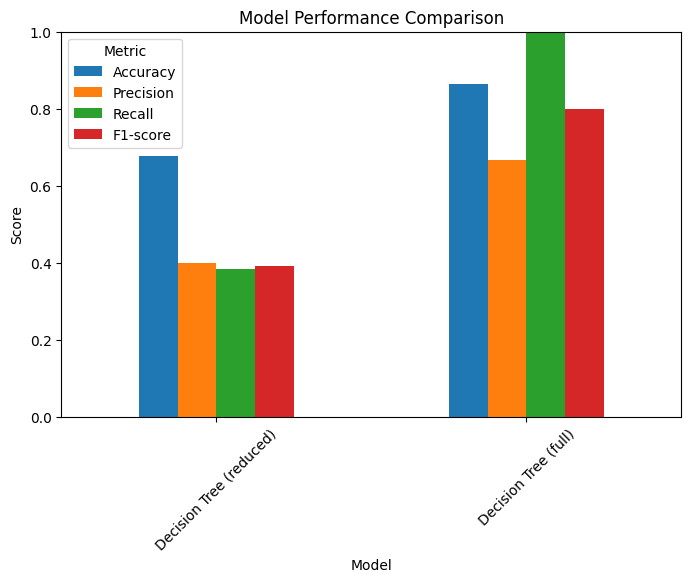

In [ ]:
results_red.plot(kind='bar', figsize=(8,5))
plt.title('Model Performance Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend(title='Metric')
plt.show()

Removing the two most influential features, promo_code_used and discount_applied, caused a significant degradation in model performance.
The accuracy dropped from 0.864 to 0.677, while both precision and recall decreased substantially (from 0.666 to 0.399 and from 1.000 to 0.384, respectively).
This confirms that the original Decision Tree relied heavily on these two features to make accurate predictions.

Overall, the results indicate that the model’s predictive capability is strongly dependent on these variables, suggesting that they carry most of the discriminative information in the dataset.
Without them, the classifier struggles to identify the target class effectively, revealing limited generalization power beyond these dominant attributes.

# Class Balancing

Class balancing is important to prevent models from being biased towards the majority class, which can lead to poor performance and misleading evaluation metrics like accuracy. This is why it's useful to also use different evaluation metrics as precision, recall, f1-score.
There are different ways to do class balancing of a method:
- oversampling the minority class, by duplicating records (risk of overfitting) or by creating artificial ones (SMOTE)
- undersampling the majority class
- balancing weights (if the model gets a rare example wrong, the error is penalized more than a mistake on the dominant class)

## Defining pipelines and parameters

### Decision Tree

Generally we will have one pipeline for the base method, one to oversample, one to undersample and one to balance the weights

In [ ]:
dt_pipelines = {
    'dt_no_bal': ImbPipeline([('model', DecisionTreeClassifier(random_state=42))]),
    'dt_smote': ImbPipeline([('smote', SMOTE()), ('model', DecisionTreeClassifier(random_state=42))]),
    'dt_under': ImbPipeline([('under', RandomUnderSampler()), ('model', DecisionTreeClassifier(random_state=42))]),
    'dt_class_weight': ImbPipeline([('model', DecisionTreeClassifier(random_state=42, class_weight='balanced'))])
}

dt_params = {
    'model__max_depth': [3, 5, 7, None],
    'model__min_samples_split': [2, 5, 10],
    'model__ccp_alpha': [0, 0.01, 0.1],
}

### Logistic Regression

In [ ]:
lr_pipelines = {
    'lr_no_bal': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', LogisticRegression(random_state=42, max_iter=5000))]),
    'lr_smote': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('smote', SMOTE()), ('model', LogisticRegression(random_state=42, max_iter=5000))]),
    'lr_under': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('under', RandomUnderSampler()), ('model', LogisticRegression(random_state=42, max_iter=5000))]),
    'lr_class_weight': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', LogisticRegression(random_state=42, class_weight='balanced', max_iter=5000))])
}

lr_params = {
    'model__penalty': ['l1', 'l2'],
    'model__C': [0.01, 0.1, 1, 10],
    'model__solver': ['saga']
}

### SVM (Linear kernel, Polynomial kernel, RBF kernel)

#### Linear kernel

In [ ]:
svm_linear_pipelines = {
    'svm_no_bal': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', SVC(random_state=42))]),
    'svm_smote': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('smote', SMOTE()), ('model', SVC(random_state=42))]),
    'svm_under': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('under', RandomUnderSampler()), ('model', SVC(random_state=42))]),
    'svm_class_weight': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', SVC(random_state=42, class_weight='balanced'))])
}

svm_linear_params = {
    'model__C': [0.1, 1, 10]
}

#### Polynomial kernel

In [ ]:
svm_polynomial_pipelines = {
    'svm_no_bal': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', SVC(random_state=42))]),
    'svm_smote': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('smote', SMOTE()), ('model', SVC(random_state=42))]),
    'svm_under': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('under', RandomUnderSampler()), ('model', SVC(random_state=42))]),
    'svm_class_weight': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', SVC(random_state=42, class_weight='balanced'))])
}

svm_polynomial_params = {
    'model__kernel': ['poly'],
    'model__C': [0.1, 1, 10],
    'model__degree': [2, 3, 4],
    'model__gamma': ['scale', 'auto'],
    'model__coef0': [0, 1]
}

#### RBF kernel

In [ ]:
svm_rbf_pipelines = {
    'svm_no_bal': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', SVC(random_state=42))]),
    'svm_smote': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('smote', SMOTE()), ('model', SVC(random_state=42))]),
    'svm_under': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('under', RandomUnderSampler()), ('model', SVC(random_state=42))]),
    'svm_class_weight': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', SVC(random_state=42, class_weight='balanced'))])
}

svm_rbf_params = {
    'model__kernel': ['rbf'],
    'model__C': np.logspace(-2, 3, 6),
    'model__gamma': np.logspace(-3, 2, 6)
}

### Ensemble Methods

#### Voting

In [ ]:
estimators = [('dt', DecisionTreeClassifier(random_state=42)), ('lr', LogisticRegression(random_state=42,max_iter=1000)),
              ('svm', SVC(kernel='linear', random_state=42, probability=True))]
voting_pipelines = {
    'voting_no_bal': ImbPipeline([('model', VotingClassifier(estimators=estimators))]),
    'voting_smote': ImbPipeline([('smote', SMOTE()), ('model', VotingClassifier(estimators=estimators))]),
    'voting_under': ImbPipeline([('under', RandomUnderSampler()), ('model', VotingClassifier(estimators=estimators))]),
    'voting_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', VotingClassifier(estimators=estimators))]),
}

voting_params = {
    'model__voting': ['hard', 'soft'],
    'model__weights': [
        [1, 1, 1], # all equal
        [2, 1, 1], # Decision Tree is more important
        [1, 2, 1], # Logistic is more important
        [1, 1, 2] # SVM is more important
    ]
}

#### Bagging


In [ ]:
estimators = [('dt', DecisionTreeClassifier(random_state=42))]

bagging_pipelines = {
'bagging_no_bal': ImbPipeline([('model', BaggingClassifier(random_state=42))]),
'bagging_smote': ImbPipeline([('smote', SMOTE()), ('model', BaggingClassifier(random_state=42, estimator=estimators[0][1]))]),
'bagging_under': ImbPipeline([('under', RandomUnderSampler()), ('model', BaggingClassifier(random_state=42, estimator=estimators[0][1]))]),
'bagging_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', BaggingClassifier(random_state=42))]),

}

bagging_params = {
    'model__n_estimators': [5, 10, 20],
    'model__max_samples': [0.5, 0.75, 1.0],
    'model__max_features': [0.5, 0.75, 1.0]
}

#### Stacking


In [ ]:
estimators = [('dt', DecisionTreeClassifier(random_state=42)), ('lr', LogisticRegression(random_state=42, max_iter=1000))]

stacking_pipelines = {
    'stacking_no_smote': ImbPipeline([
        ('scaler', StandardScaler(with_mean=False)),
        ('model', StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(solver='liblinear')))
    ]),
    'stacking_with_smote': ImbPipeline([
        ('smote', SMOTE()),
        ('scaler', StandardScaler(with_mean=False)),
        ('model', StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(solver='liblinear')))
    ]),
    'stacking_with_under': ImbPipeline([
        ('under', RandomUnderSampler()),
        ('scaler', StandardScaler(with_mean=False)),
        ('model', StackingClassifier(estimators=estimators, final_estimator=LogisticRegression(solver='liblinear')))
    ]),
}

stacking_params = {
    'model__final_estimator__penalty': ['l1', 'l2'],
    'model__final_estimator__C': [0.01, 0.1, 1],
    'model__final_estimator__solver': ['saga']
}

#### AdaBoost

In [ ]:
adaboost_pipelines = {
    'adaboost_no_bal': ImbPipeline([('model', AdaBoostClassifier(random_state=42))]),
    'adaboost_smote': ImbPipeline([('smote', SMOTE()), ('model', AdaBoostClassifier(random_state=42))]),
    'adaboost_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', AdaBoostClassifier(random_state=42))]),
    'adaboost_under': ImbPipeline([('under', RandomUnderSampler()), ('model', AdaBoostClassifier(random_state=42))]),
    'adaboost_class_weight': ImbPipeline([('model', AdaBoostClassifier(random_state=42))])
}

adaboost_params = {
    'model__n_estimators': [50, 100, 200],
    'model__learning_rate': [0.01, 0.1, 1]
}

#### RandomForest

In [ ]:
rf_pipelines = {
    'rf_no_bal': ImbPipeline([('model', RandomForestClassifier(random_state=42))]),
    'rf_smote': ImbPipeline([('smote', SMOTE()), ('model', RandomForestClassifier(random_state=42))]),
    'rf_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', RandomForestClassifier(random_state=42))]),
    'rf_under': ImbPipeline([('under', RandomUnderSampler()), ('model', RandomForestClassifier(random_state=42))]),
    'rf_class_weight': ImbPipeline([('model', RandomForestClassifier(random_state=42, class_weight='balanced'))])
}

rf_params = {
    'model__n_estimators': [50, 100, 150],
    'model__max_depth': [10, 20, 30],
    'model__min_samples_split': [2, 5],
    'model__max_features': ['sqrt', 'log2']
}

#### ExtraTrees

In [ ]:
et_pipelines = {
    'et_no_bal': ImbPipeline([('model', ExtraTreesClassifier(random_state=42))]),
    'et_smote': ImbPipeline([('smote', SMOTE()), ('model',  ExtraTreesClassifier(random_state=42))]),
    'et_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', ExtraTreesClassifier(random_state=42))]),
    'et_under': ImbPipeline([('under', RandomUnderSampler()), ('model', ExtraTreesClassifier(random_state=42))]),
}

et_params = {
    'model__n_estimators': [100, 150, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__max_features': ['sqrt', 'log2']
}

### Gradient Boosting


In [ ]:
gb_pipelines = {
    'gb_no_bal': ImbPipeline([('model', GradientBoostingClassifier(random_state=42))]),
    'gb_smote': ImbPipeline([('smote', SMOTE()), ('model', GradientBoostingClassifier(random_state=42))]),
    'gb_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', GradientBoostingClassifier(random_state=42))]),
    'gb_under': ImbPipeline([('under', RandomUnderSampler()), ('model', GradientBoostingClassifier(random_state=42))]),
}

gb_params = {
    'model__n_estimators': [50, 100, 150],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__max_depth': [3, 5, 7],
    'model__subsample': [0.6, 0.8, 1]
}

### XGBoost

In [ ]:
ratio = len(y_train[y_train==0]) / len(y_train[y_train==1])
print(ratio)

2.705463182897862


In [ ]:
xgb_pipelines = {
    'xgb_no_bal': ImbPipeline([('model', XGBClassifier(random_state=42,scale_pos_weight=ratio))]),
    'xgb_smote': ImbPipeline([('smote', SMOTE()), ('model', XGBClassifier(random_state=42))]),
    'xgb_ros': ImbPipeline([('ros', RandomOverSampler()), ('model', XGBClassifier(random_state=42))]),
    'xgb_under': ImbPipeline([('under', RandomUnderSampler()), ('model', XGBClassifier(random_state=42))]),
    'xgb_class_weight': ImbPipeline([('model', XGBClassifier(random_state=42, scale_pos_weight=ratio))])
}

xgb_params = {
    'model__n_estimators': [50, 100, 150],
    'model__learning_rate': [0.05, 0.1, 0.2],
    'model__max_depth': [3, 5, 7],
    'model__subsample': [0.6, 0.8, 1.0]
}

### Multi Layer Perceptron

early_stopping=True to cut down convergence time

In [ ]:
mlp_pipelines = {
    'mlp_no_bal': ImbPipeline([('scaler', StandardScaler(with_mean=False)), ('model', MLPClassifier(random_state=42, max_iter=5000, early_stopping=True))]),
    'mlp_smote': ImbPipeline([('smote', SMOTE()), ('scaler', StandardScaler(with_mean=False)), ('model', MLPClassifier(random_state=42, max_iter=5000, early_stopping=True))]),
    'mlp_ros': ImbPipeline([('ros', RandomOverSampler()), ('scaler', StandardScaler(with_mean=False)), ('model', MLPClassifier(random_state=42, max_iter=5000, early_stopping=True))]),
    'mlp_under': ImbPipeline([('under', RandomUnderSampler()), ('scaler', StandardScaler(with_mean=False)), ('model', MLPClassifier(random_state=42, max_iter=5000, early_stopping=True))]),
}

mlp_params = {
    'model__hidden_layer_sizes': [(50,), (100,), (150,), (100, 50)],
    'model__activation': ['relu', 'tanh'],
    'model__solver': ['adam', 'sgd'],
    'model__alpha': [0.0001, 0.001],
    'model__learning_rate': ['adaptive', 'constant']
}

## Creating models and executing them

Here, for each method, we put together the relative pipeline, the parameters and the search function we previously used in the tuning section (for speed and continuity reasons)

In [ ]:
all_models = {
    'Decision Tree': {
        'pipelines': dt_pipelines,
        'params': dt_params,
        'search': GridSearchCV
    },
    'Logistic Regression': {
        'pipelines': lr_pipelines,
        'params': lr_params,
        'search': GridSearchCV
    },
    'SVM Linear': {
        'pipelines': svm_linear_pipelines,
        'params': svm_linear_params,
        'search': GridSearchCV
    },
    'SVM Polynomial': {
        'pipelines': svm_polynomial_pipelines,
        'params': svm_polynomial_params,
        'search': HalvingGridSearchCV
    },
    'SVM RBF': {
        'pipelines': svm_rbf_pipelines,
        'params': svm_rbf_params,
        'search': HalvingGridSearchCV
    },
    'Voting Classifier': {
        'pipelines': voting_pipelines,
        'params': voting_params,
        'search': HalvingGridSearchCV
    },
    'Bagging Classifier': {
        'pipelines': bagging_pipelines,
        'params': bagging_params,
        'search': GridSearchCV
    },
    'Stacking Classifier': {
        'pipelines': stacking_pipelines,
        'params': stacking_params,
        'search': GridSearchCV
    },
    'AdaBoost Classifier': {
        'pipelines': adaboost_pipelines,
        'params': adaboost_params,
        'search': GridSearchCV
    },
    'Random Forest': {
        'pipelines': rf_pipelines,
        'params': rf_params,
        'search': RandomizedSearchCV
    },
    'Extra Trees': {
        'pipelines': et_pipelines,
        'params': et_params,
        'search': RandomizedSearchCV
    },
    'Gradient Boosting': {
        'pipelines': gb_pipelines,
        'params': gb_params,
        'search': RandomizedSearchCV
    },
    'XGBoost': {
        'pipelines': xgb_pipelines,
        'params':  xgb_params,
        'search': RandomizedSearchCV
    },
    'MLP': {
        'pipelines': mlp_pipelines,
        'params':  mlp_params,
        'search': RandomizedSearchCV
    }
}

Now we need to tune the hyperparameters for multiple machine learning models using one of the search functions (GridSearchCV, RandomizedSearchCV, HalvingGridSearchCV), fit the best estimator on the training data, and evaluate its performance on the test set. Then we stores the best parameters and key evaluation metrics (accuracy, precision, recall, F1) for each model and pipeline strategy

In [ ]:
results = []

for model_name, model_info in all_models.items():
    pipelines = model_info['pipelines']
    params = model_info['params']
    SearchCV = model_info['search']

    # Pipelines must be a dictionary. If this isn't true, then trasform it
    if not isinstance(pipelines, dict):
        pipelines = {model_name: pipelines}

    for strategy_name, pipeline in pipelines.items():
        # Set kwargs dynamically based on search type
        search_kwargs = {
            'estimator': pipeline,
            'cv': 5,
            'scoring': 'f1',
            'verbose': 1
        }

        # RandomizedSearchCV uses param_distributions instead of param_grid
        if SearchCV == RandomizedSearchCV:
            search_kwargs['param_distributions'] = params
            search_kwargs['n_iter'] = 20
        else:
            search_kwargs['param_grid'] = params

        # Creates and trains the search
        search = SearchCV(**search_kwargs)
        search.fit(X_train, y_train)

        # Predicts and evaluates
        y_pred = search.best_estimator_.predict(X_test)

        results.append({
            'model': model_name,
            'strategy': strategy_name,
            'best_params': search.best_params_,
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred),
            'recall': recall_score(y_test, y_pred),
            'f1': f1_score(y_test, y_pred)
        })

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
Fitting 5 folds for each of 3 candidates, totalling 15 fits
n_iterations: 4
n_required_iterations: 4
n_possible_iterations: 4
min_resources_: 115
max_resources_: 3120
aggressive_elimination: False
factor: 3
----------
iter: 0
n_candidates: 36
n_resources: 115
Fitting 5 folds for each of 36 candidates, totalling 180 fits
----------

## Results analysis

In [ ]:
results_df = pd.DataFrame(results)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 2000)
print(results_df.sort_values(by='f1', ascending=False)) # We order by f1-score because it's the harmonic mean of precision and recall

                  model               strategy                                                                                                                                                best_params  accuracy  precision    recall        f1
44          Extra Trees               et_under                                         {'model__n_estimators': 200, 'model__min_samples_split': 5, 'model__max_features': 'sqrt', 'model__max_depth': 20}  0.865385   0.667722  1.000000  0.800759
0         Decision Tree              dt_no_bal                                                                           {'model__ccp_alpha': 0.01, 'model__max_depth': 3, 'model__min_samples_split': 2}  0.864103   0.665615  1.000000  0.799242
2         Decision Tree               dt_under                                                                           {'model__ccp_alpha': 0.01, 'model__max_depth': 3, 'model__min_samples_split': 2}  0.864103   0.665615  1.000000  0.799242
3         Decision Tree     

In [ ]:
# Save results
results_df.to_csv('all_models_balancing_results.csv', index=False)
files.download('all_models_balancing_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

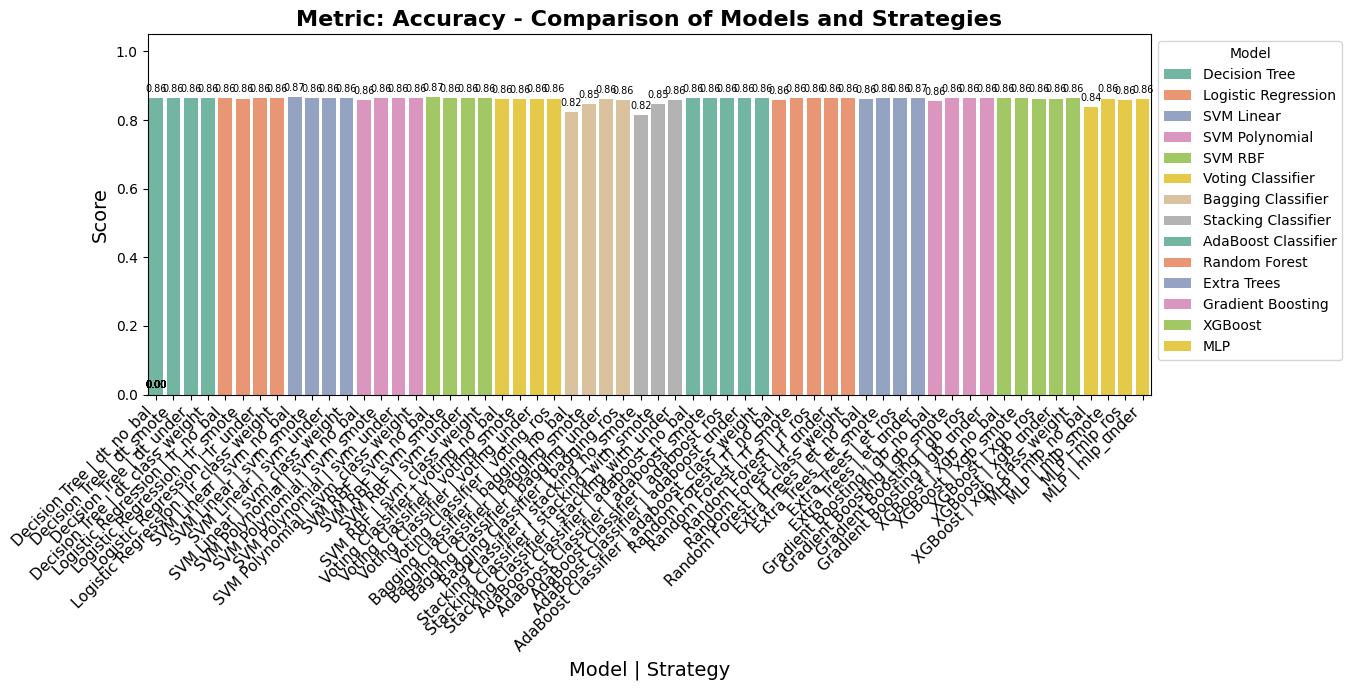

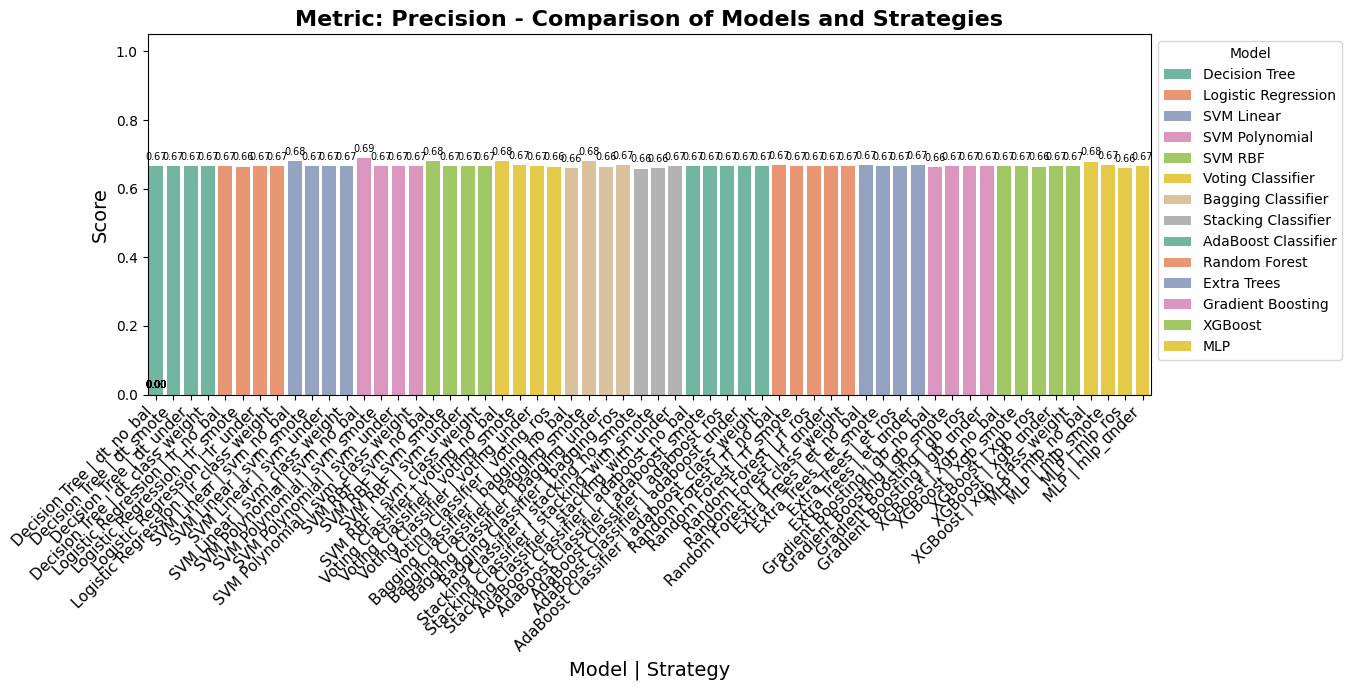

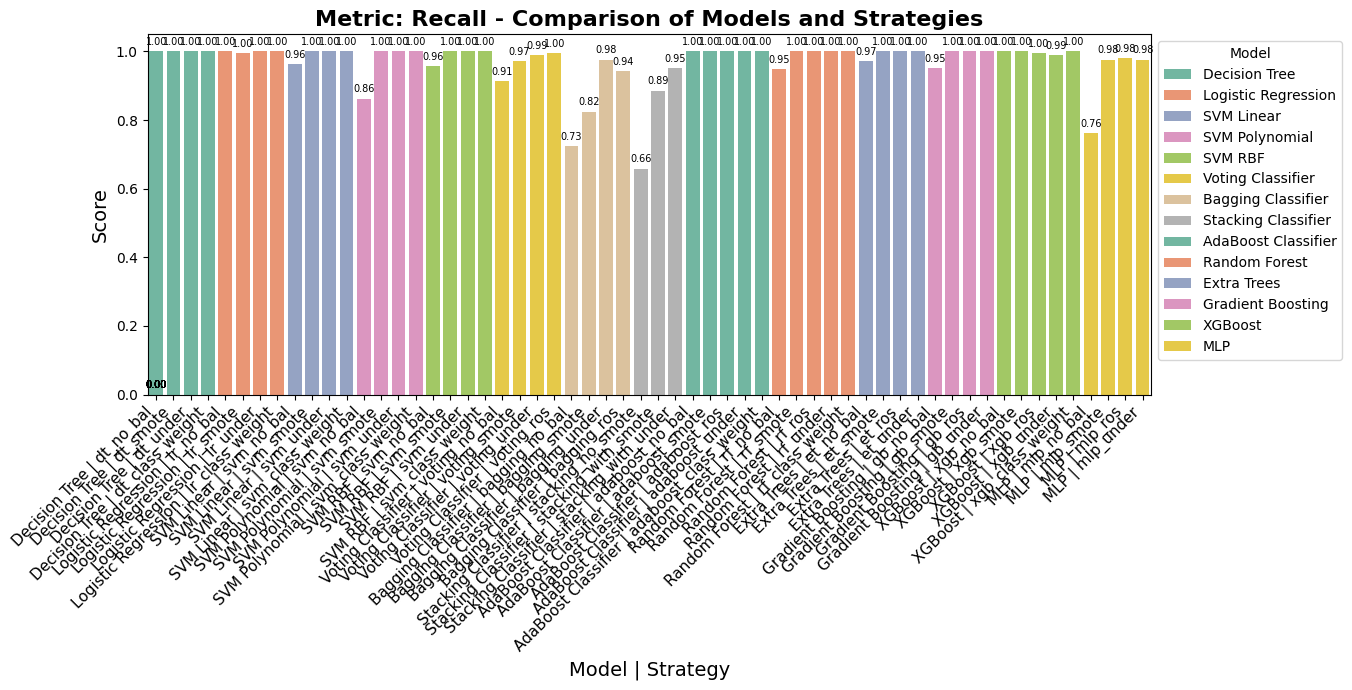

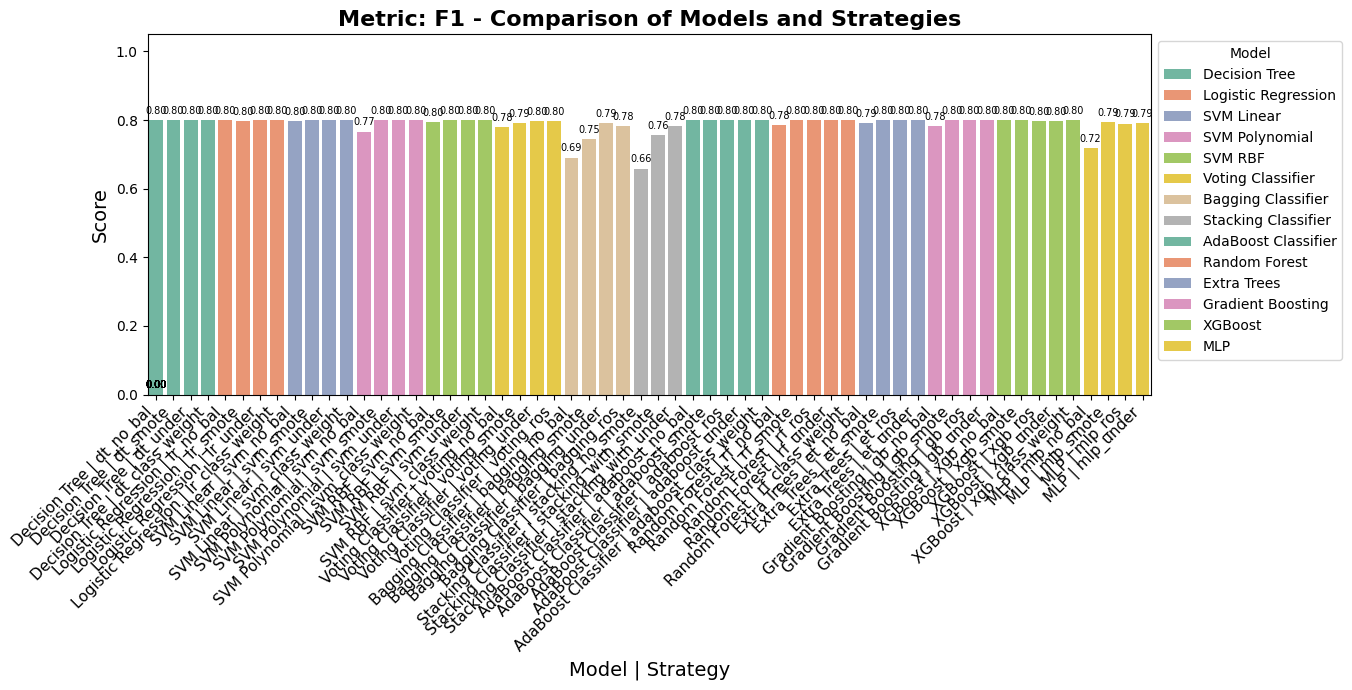

In [ ]:
metrics = ['accuracy', 'precision', 'recall', 'f1']

results_df['model_strategy'] = results_df['model'] + " | " + results_df['strategy']

palette = sns.color_palette("Set2", n_colors=len(results_df['model'].unique()))

for metric in metrics:
    plt.figure(figsize=(16, 7))
    ax = sns.barplot(
        data=results_df,
        x='model_strategy',
        y=metric,
        hue='model',
        palette=palette,
        dodge=False,
        errorbar=None
    )

    ax.set_title(f'Metric: {metric.capitalize()} - Comparison of Models and Strategies', fontsize=16, fontweight='bold')
    ax.set_ylim(0, 1.05)
    ax.set_xlabel('Model | Strategy', fontsize=14)
    ax.set_ylabel('Score', fontsize=14)

    plt.xticks(rotation=45, ha='right', fontsize=11)

    for p in ax.patches:
        height = p.get_height()
        ax.annotate(
            f"{height:.2f}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center',
            va='bottom',
            xytext=(0, 3),
            textcoords='offset points',
            fontsize=7
        )

    # Legend
    ax.legend(title='Model', loc='upper left', bbox_to_anchor=(1, 1))

    plt.tight_layout(rect=[0, 0, 0.85, 1])
    plt.show()

The results show that most models achieve very similar performance, with an F1-score around 0.80 and recall close to 1.0, indicating that they predict almost all positive cases but at the cost of lower precision (~0.67). This suggests that the models are highly sensitive but tend to overpredict the positive class. The lack of significant differences among models also indicates that the dataset might limit classification performance, or that the chosen hyperparameter ranges were relatively narrow. Ensemble methods and boosting algorithms did not outperform simpler models like Decision Tree or Logistic Regression, which suggests that further improvements may require enhanced feature engineering, more extensive hyperparameter tuning, or threshold optimization rather than simply changing the model type

# Robustness Analysis

We now test how well the tuned model performs with different datasets (by creating different X and y)<br>
We then compare the results, first for the same model, (with ROC curves, means and std) and then for different models

In [ ]:
# Creation of the new X and y (same for all datasets)
df = pd.read_csv("shopping_trends.csv")

y = df['Subscription Status']
X = df.drop(columns=['Subscription Status', 'Customer ID'])

cat_feats = [c for c in X.columns if X[c].dtype == 'object']
num_feats = [c for c in X.columns if X[c].dtype != 'object']

# Preprocessing: scaling for numericals, one-hot encoding for categorials
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_feats),
    ('cat', OneHotEncoder(drop='first'), cat_feats)
])

X = preprocessor.fit_transform(X) # to have numerical and scaled values

## Base model

We will use the tuned models found before as a base model

In [ ]:
best_dt = DecisionTreeClassifier(
    ccp_alpha=0.01,
    max_depth=3,
    min_samples_split=2,
    random_state = 42
)

best_lr = LogisticRegression(
    C=0.1,
    max_iter=1000,
    penalty='l1',
    solver='saga',
    random_state = 42
)

svm_linear = SVC(
    C=0.1,
    gamma='scale',
    kernel='linear',
    probability=True,
    random_state = 42
)

svm_poly = SVC(
    C=1,
    gamma='scale',
    kernel='poly',
    probability=True,
    random_state = 42
)

svm_rbf = SVC(
    C=np.float64(10.0),
    gamma=np.float64(0.01),
    kernel='rbf',
    probability=True,
    random_state = 42
)

voting = VotingClassifier(
    estimators=[
        ('dt', best_dt),
        ('lr', best_lr),
        ('svm', svm_rbf)
    ],
    voting='soft',
)

bagging = BaggingClassifier(
    estimator=best_dt,
    n_estimators=5,
    max_samples=0.5,
    max_features=0.5,
    random_state = 42
)

stacking = StackingClassifier(
    estimators=[
        ('dt', best_dt),
        ('lr', best_lr),
        ('svm', svm_rbf)
    ],
    final_estimator=LogisticRegression(
        C=0.01,
        penalty='l1',
        solver='saga',
        random_state = 42
    ),
    passthrough=False
)

adaboost = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state = 42
)

rf = RandomForestClassifier(
    max_depth=20,
    max_features='sqrt',
    min_samples_split=5,
    n_estimators=100,
    random_state=42
)

et = ExtraTreesClassifier(
    max_depth=10,
    max_features='sqrt',
    min_samples_split=5,
    n_estimators=150,
    random_state=42
)

gradient_boosting = GradientBoostingClassifier(
    n_estimators=50,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.6,
    random_state = 42
)

xgboost = XGBClassifier(
    n_estimators=50,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.6,
    colsample_bytree=1.0,
    eval_metric='logloss',
    random_state = 42
)

# Model list
models = [
    ("Decision Tree", best_dt),
    ("Logistic Regression", best_lr),
    ("SVM Linear", svm_linear),
    ("SVM Poly", svm_poly),
    ("SVM RBF", svm_rbf),
    ("Voting", voting),
    ("Bagging", bagging),
    ("Stacking", stacking),
    ("AdaBoost", adaboost),
    ("RandomForest", rf),
    ("ExtraTrees", et),
    ("Gradient Boosting", gradient_boosting),
    ("XGBoost", xgboost)
]

We use different test_sizes and random_states to obtain different X

In [ ]:
test_sizes = [0.1, 0.3, 0.5, 0.9]
random_states = [0, 1, 2, 42]

Saving all data in a dataframe

In [ ]:
all_results = pd.DataFrame()

## ROC and Confusion matrix

We loop on all test sizes and all random states

In [ ]:
# Storage for ROC and Confusion matrices data
confusion_matrices = []
roc_data = []

for model_name, model in models:
    for ts in test_sizes:
        for rs in random_states:
            print(f"Processing: {model_name} | test_size={ts} | random_state={rs}")

            # Split
            X_train, X_test, y_train, y_test = train_test_split(
                X, y, test_size=ts, random_state=rs, stratify=y
            )

            # Convert
            y_train_bin = y_train.map({'No': 0, 'Yes': 1})
            y_test_bin = y_test.map({'No': 0, 'Yes': 1})

            # Fit
            model.fit(X_train, y_train_bin)

            # Predict
            y_pred = model.predict(X_test)
            y_prob = model.predict_proba(X_test)[:,1] if hasattr(model, "predict_proba") else None

            # Metrics
            acc = accuracy_score(y_test_bin, y_pred)
            prec = precision_score(y_test_bin, y_pred, average='macro', zero_division=0)
            rec = recall_score(y_test_bin, y_pred, average='macro', zero_division=0)
            f1 = f1_score(y_test_bin, y_pred, average='macro', zero_division=0)

            # ROC
            if y_prob is not None:
                fpr, tpr, _ = roc_curve(y_test_bin, y_prob)
                roc_auc = auc(fpr, tpr)
                roc_data.append({
                    "Model": model_name,
                    "TestSize": ts,
                    "RandomState": rs,
                    "FPR": fpr,
                    "TPR": tpr,
                    "AUC": roc_auc
                })

            # Confusion matrix
            cm = confusion_matrix(y_test_bin, y_pred)
            confusion_matrices.append({
                "Model": model_name,
                "TestSize": ts,
                "RandomState": rs,
                "ConfusionMatrix": cm
            })

            # Save metrics inside dataframe
            all_results = pd.concat([
                all_results,
                pd.DataFrame([{
                    "Model": model_name,
                    "TestSize": ts,
                    "RandomState": rs,
                    "Accuracy": acc,
                    "Precision": prec,
                    "Recall": rec,
                    "F1": f1
                }])
            ], ignore_index=True)


Processing: Decision Tree | test_size=0.1 | random_state=0
Processing: Decision Tree | test_size=0.1 | random_state=1
Processing: Decision Tree | test_size=0.1 | random_state=2
Processing: Decision Tree | test_size=0.1 | random_state=42
Processing: Decision Tree | test_size=0.3 | random_state=0
Processing: Decision Tree | test_size=0.3 | random_state=1
Processing: Decision Tree | test_size=0.3 | random_state=2
Processing: Decision Tree | test_size=0.3 | random_state=42
Processing: Decision Tree | test_size=0.5 | random_state=0
Processing: Decision Tree | test_size=0.5 | random_state=1
Processing: Decision Tree | test_size=0.5 | random_state=2
Processing: Decision Tree | test_size=0.5 | random_state=42
Processing: Decision Tree | test_size=0.9 | random_state=0
Processing: Decision Tree | test_size=0.9 | random_state=1
Processing: Decision Tree | test_size=0.9 | random_state=2
Processing: Decision Tree | test_size=0.9 | random_state=42
Processing: Logistic Regression | test_size=0.1 | ra

### Metric table

Mean and standard deviation for the different metrics of every model

In [ ]:
summary = all_results.groupby("Model")[["Accuracy","Precision","Recall","F1"]].agg(["mean","std"])
print(summary)
summary.to_csv("summary_metrics.csv")

                     Accuracy           Precision              Recall                  F1          
                         mean       std      mean       std      mean       std      mean       std
Model                                                                                              
AdaBoost             0.840331  0.018305  0.806197  0.025805  0.868249  0.048076  0.818251  0.027780
Bagging              0.842215  0.016586  0.809744  0.022544  0.876542  0.039181  0.822288  0.023387
Decision Tree        0.843337  0.015973  0.811756  0.021516  0.880052  0.038152  0.824019  0.022821
ExtraTrees           0.839776  0.018829  0.801955  0.024156  0.858579  0.042241  0.815821  0.026852
Gradient Boosting    0.833383  0.017171  0.791726  0.022234  0.838324  0.039840  0.805162  0.025621
Logistic Regression  0.847557  0.009773  0.819660  0.007528  0.895610  0.006731  0.831636  0.009682
RandomForest         0.837343  0.022438  0.796207  0.028198  0.842912  0.051162  0.809016  0.033967


This comparison table summarizes the performance of several classification models across Accuracy, Precision, Recall, and F1-score. Overall, Logistic Regression stands out as the most consistent and best-performing model, achieving the highest Accuracy (0.8476), Precision (0.8197), Recall (0.8956), and F1-score (0.8316) with very low standard deviations, indicating stability. Close contenders include the Decision Tree and SVM Linear, which also show strong balance between Precision, Recall, and F1. On the other hand, Stacking performs notably worse, with a much lower F1-score (0.528) and high variance, suggesting instability or poor model combination. Interestingly, ensemble methods like Bagging, AdaBoost, and Voting generally perform well but do not surpass Logistic Regression. Another observation is that non-linear SVMs (Poly and RBF) underperform compared to the linear SVM, which is unusual and may indicate the data favors linear separability. In short, Logistic Regression is the clear winner here, while Stacking is the weakest approach.

### Best model found for each metric

Differently from the previous section, here we find the best absolute model among all the models by single result foreach metric (not by the mean)

In [ ]:
for metric in ['Accuracy', 'Precision', 'Recall', 'F1']:
    best_idx = all_results[metric].idxmax()
    best_result = all_results.loc[best_idx]
    print(f"Best {metric}: {best_result['Model']} (ts={best_result['TestSize']}, rs={best_result['RandomState']}) = {best_result[metric]:.4f}")


Best Accuracy: RandomForest (ts=0.1, rs=42) = 0.8846
Best Precision: RandomForest (ts=0.1, rs=42) = 0.8481
Best Recall: ExtraTrees (ts=0.1, rs=42) = 0.9163
Best F1: RandomForest (ts=0.1, rs=42) = 0.8673


### ROC Curves

- **ROC (Receiver Operating Characteristic) curves** show the trade-off between **True Positive Rate (Recall)** and **False Positive Rate** at different thresholds.
- **AUC (Area Under the Curve)** summarizes the model's ability to distinguish classes in a single number.  
  Higher AUC indicates better discriminative power.

**Typical interpretation of AUC:**

| AUC       | Interpretation        |
|-----------|---------------------|
| 0.5       | Random classifier    |
| 0.6-0.7   | Weak                 |
| 0.7-0.8   | Acceptable           |
| 0.8-0.9   | Good                 |
| >0.9      | Excellent            |



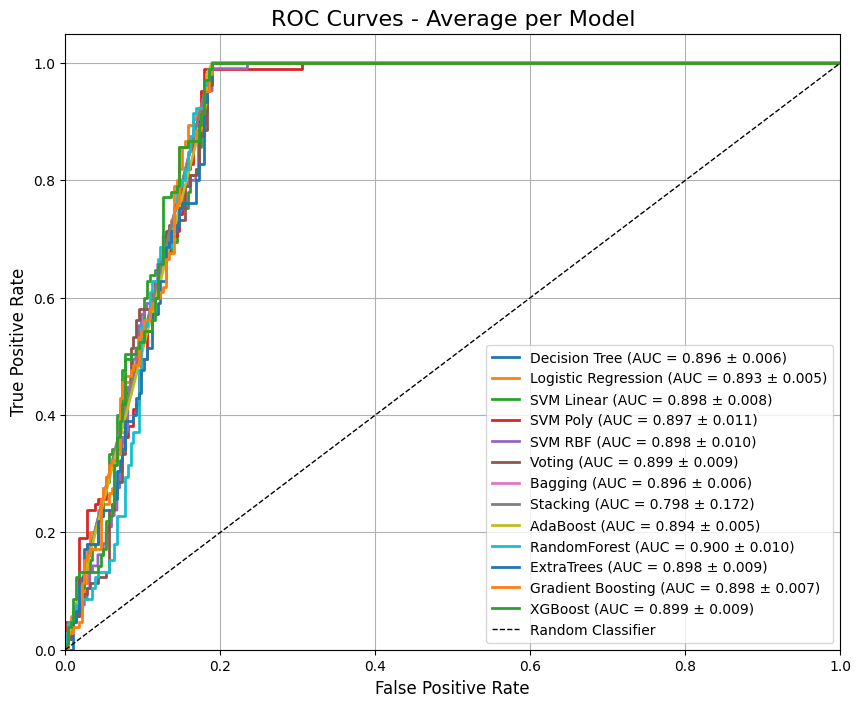

In [ ]:
plt.figure(figsize=(10, 8))
plt.title("ROC Curves - Average per Model", fontsize=16)

# Calculate average ROC per model
model_roc_avg = {}
for roc in roc_data:
    model_name = roc['Model']
    if model_name not in model_roc_avg:
        model_roc_avg[model_name] = {'fpr': [], 'tpr': [], 'auc': []}
    model_roc_avg[model_name]['fpr'].append(roc['FPR'])
    model_roc_avg[model_name]['tpr'].append(roc['TPR'])
    model_roc_avg[model_name]['auc'].append(roc['AUC'])

# Plot average ROC curves
for model_name, data in model_roc_avg.items():
    mean_auc = np.mean(data['auc'])
    std_auc = np.std(data['auc'])

    plt.plot(data['fpr'][0], data['tpr'][0],
             label=f'{model_name} (AUC = {mean_auc:.3f} ± {std_auc:.3f})',
             linewidth=2)

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.legend()
plt.grid(True)
plt.show()

### Boxplots for Distribution Analysis

Boxplots that represent the accuracy and F1-score distribution for each method

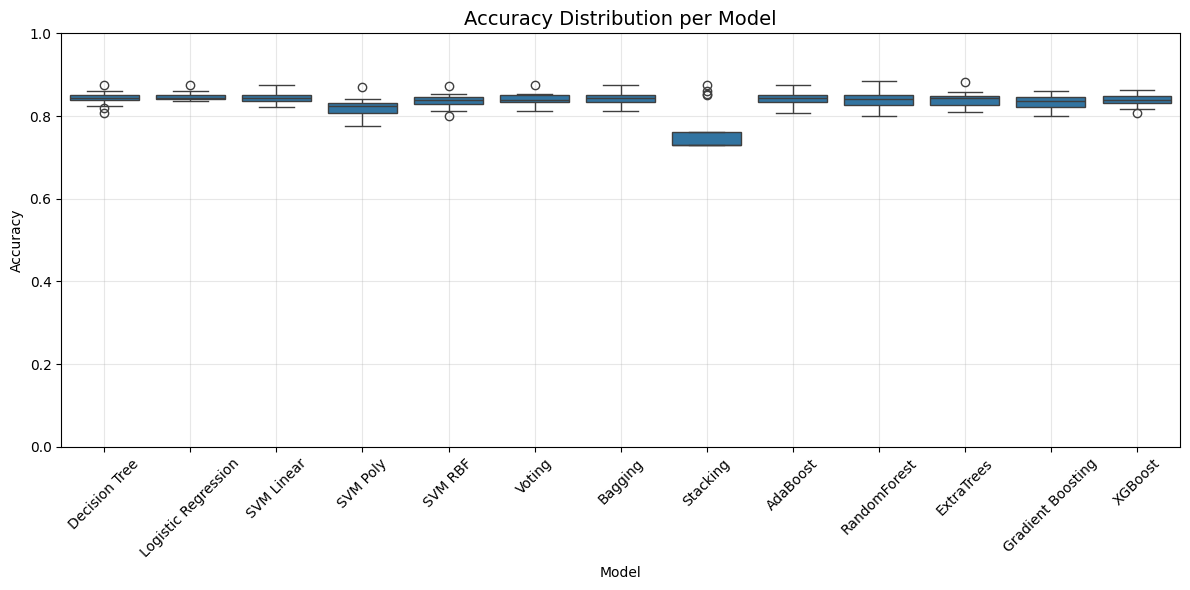

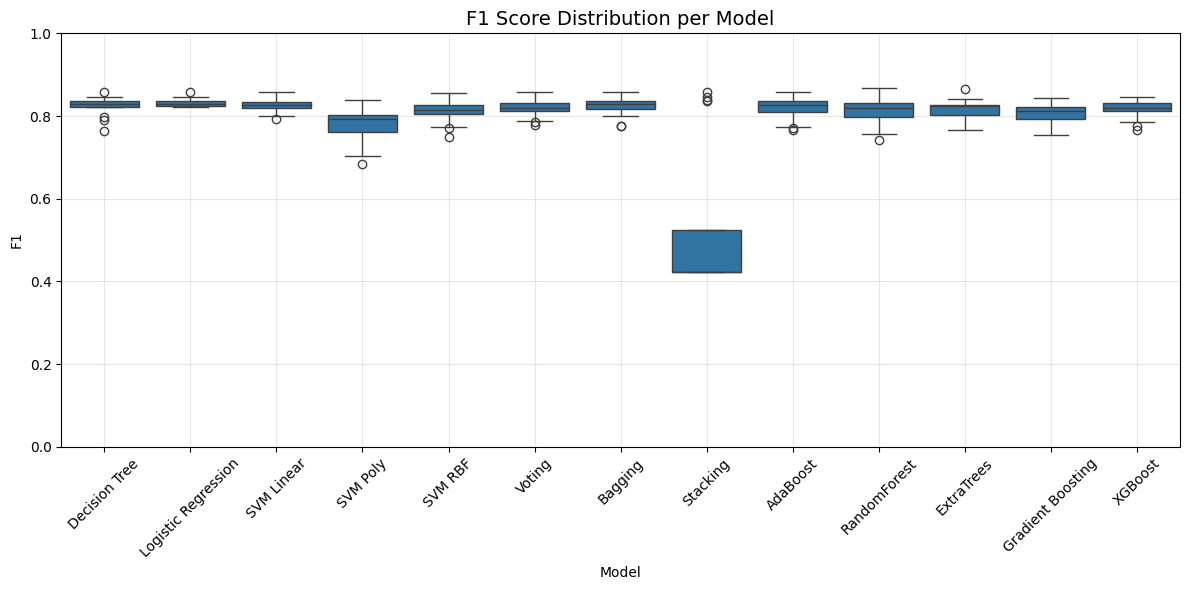

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=all_results, x="Model", y="Accuracy")
plt.title("Accuracy Distribution per Model", fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(data=all_results, x="Model", y="F1")
plt.title("F1 Score Distribution per Model", fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Barplots with Error Bars

Representation of mean (bar) and std (black line) for accuracy and F1-score for each method

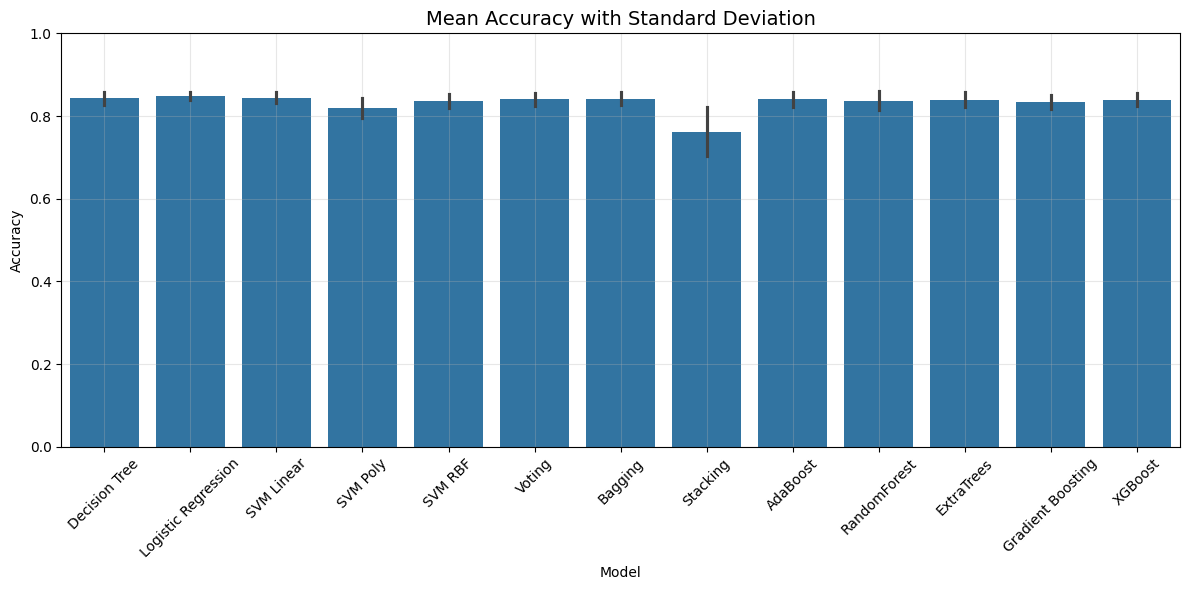

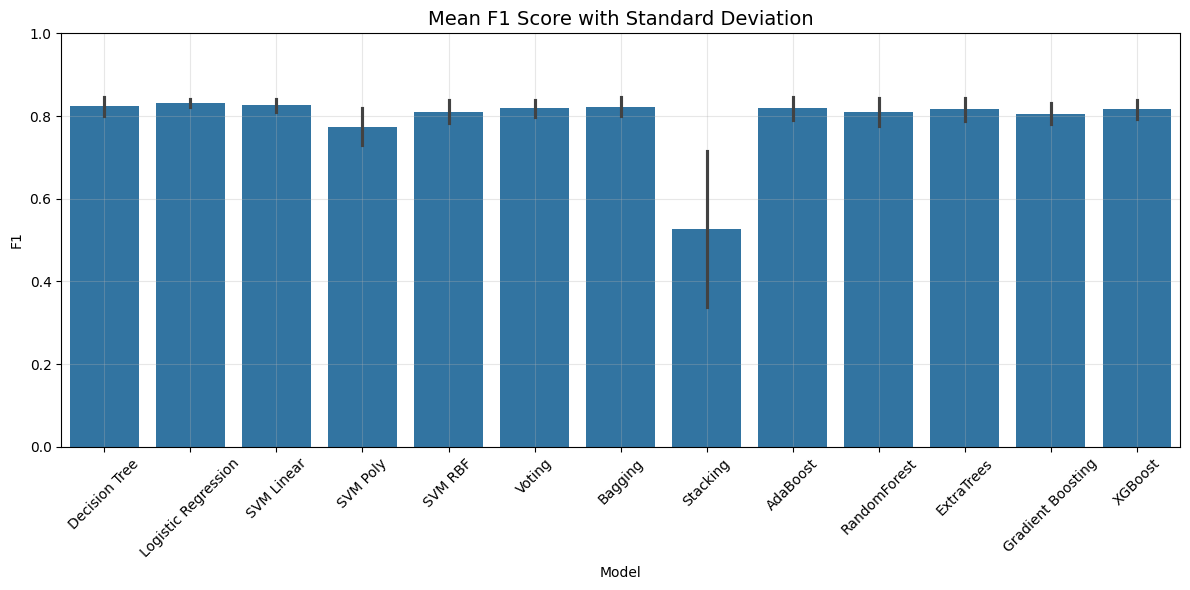

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(data=all_results, x="Model", y="Accuracy", errorbar="sd")
plt.title("Mean Accuracy with Standard Deviation", fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
sns.barplot(data=all_results, x="Model", y="F1", errorbar="sd")
plt.title("Mean F1 Score with Standard Deviation", fontsize=14)
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Confusion Matrix

|                     | Predicted Negative  | Predicted Positive  |
| ------------------- | ------------------- | ------------------- |
| **Actual Negative** | True Negative (TN)  | False Negative (FN) |
| **Actual Positive** | False Positive (FP) | True Positive (TP)  |


In [ ]:
print("Confusion matrices available in 'confusion_matrices' list")
print(f"Total matrices stored: {len(confusion_matrices)}")

Confusion matrices available in 'confusion_matrices' list
Total matrices stored: 208


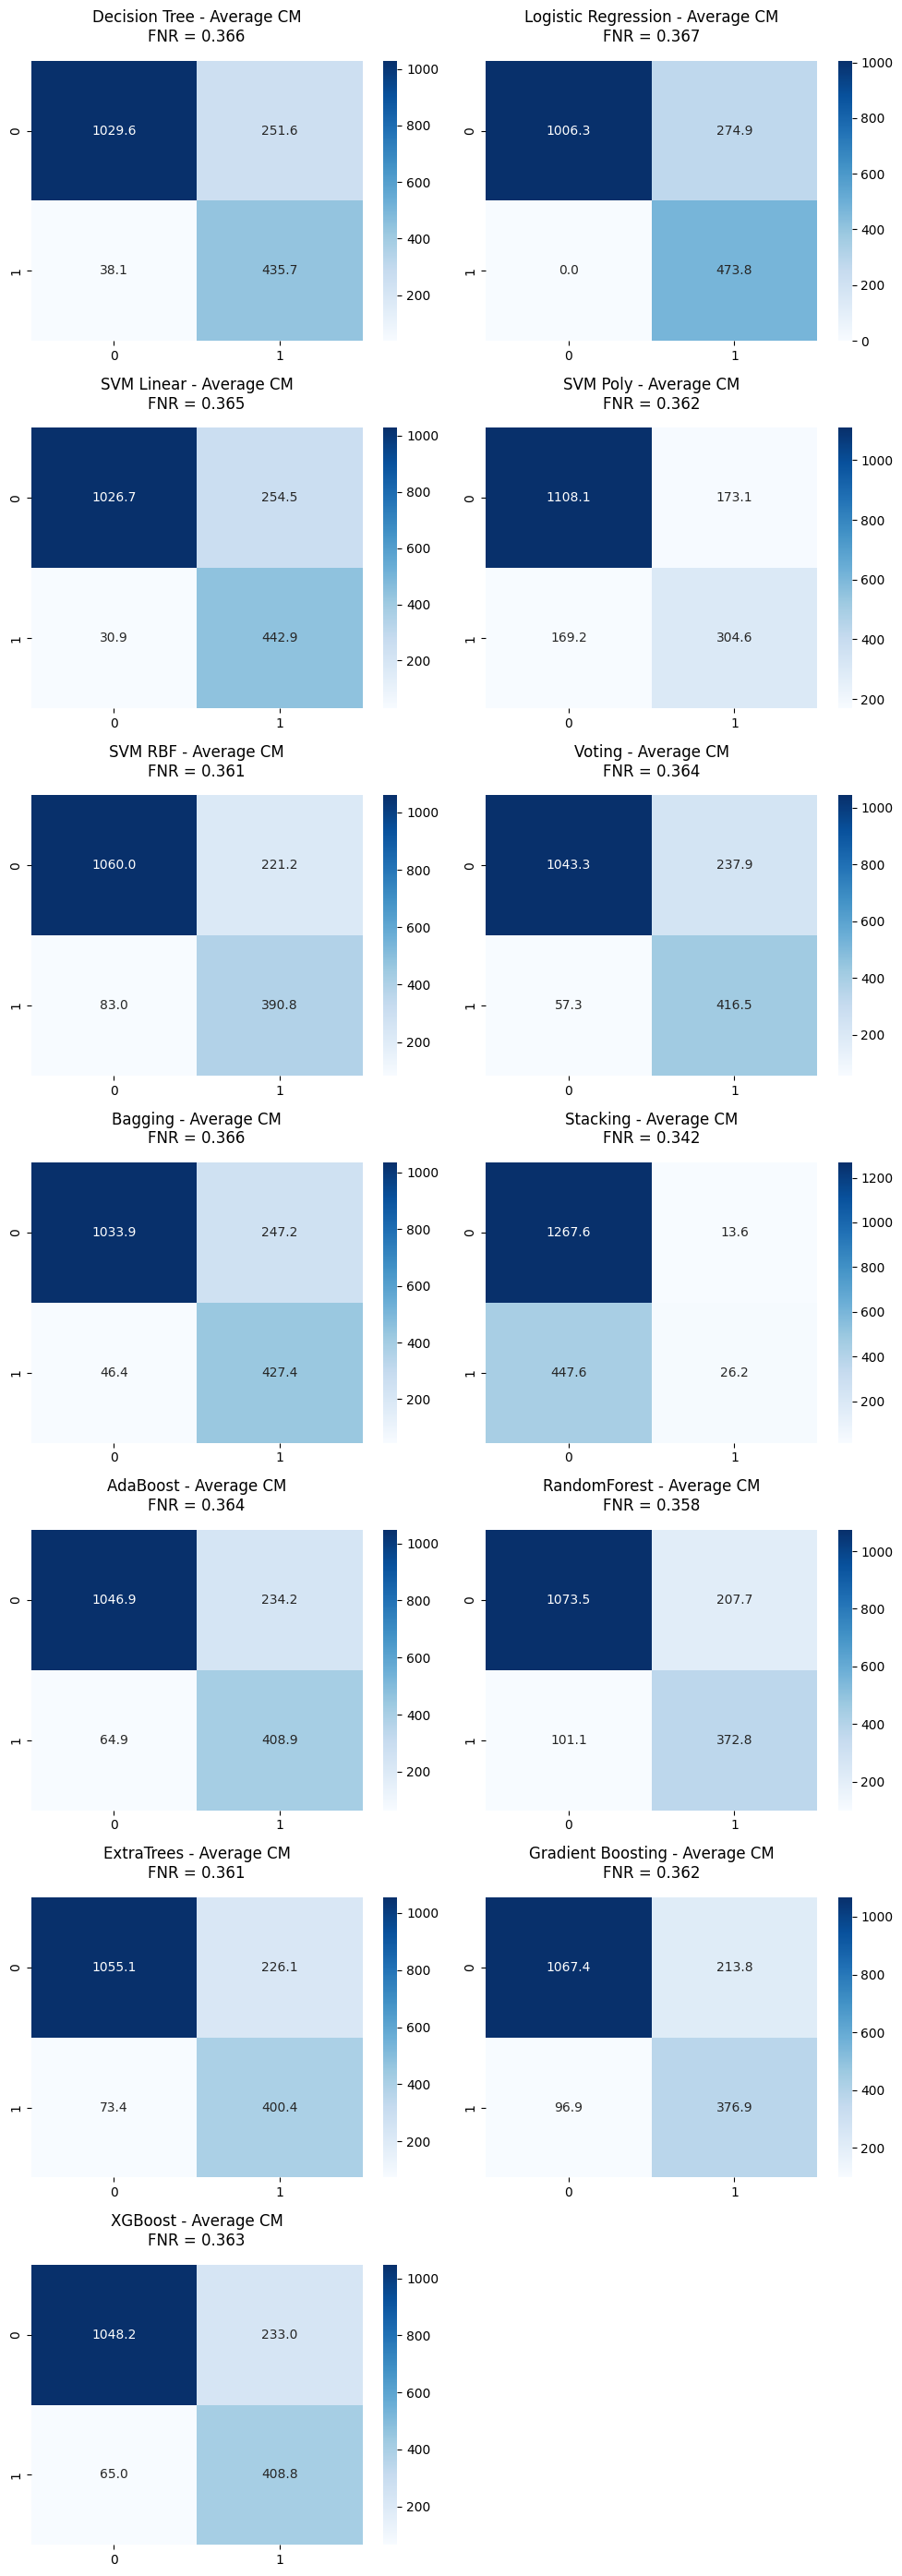

In [ ]:
# Calculate mean confusion matrix for each method
mean_cms = {}
for model_name in all_results['Model'].unique():
    model_cms = [cm['ConfusionMatrix'] for cm in confusion_matrices if cm['Model'] == model_name]
    mean_cms[model_name] = np.mean(model_cms, axis=0)

# Calculate grid dimensions (2 columns)
n_models = len(mean_cms)
n_cols = 2
n_rows = (n_models + n_cols - 1) // n_cols

# Plot in grid format
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 4 * n_rows))

# Handle cases where we have 1 model or 1 row
if n_models == 1:
    axes = [axes]
elif n_rows == 1:
    axes = [axes]

# Flatten axes for easier indexing
axes_flat = axes.flatten() if n_models > 1 else axes

for i, (model_name, mean_cm) in enumerate(mean_cms.items()):
    sns.heatmap(mean_cm, annot=True, fmt='.1f', ax=axes_flat[i], cmap='Blues')

    # Assuming binary classification:
    # mean_cm = [[TN, FN],
    #            [FP, TP]]
    tn, fn, fp, tp = mean_cm.ravel()
    fnr = fn / (fn + tp) if (fn + tp) > 0 else 0.0

    # Add title and FNR below each plot
    axes_flat[i].set_title(f'{model_name} - Average CM\nFNR = {fnr:.3f}', pad=15)

# Hide unused subplots if we have an odd number of models
for j in range(i + 1, len(axes_flat)):
    axes_flat[j].set_visible(False)

plt.tight_layout()
plt.show()

These confusion matrix heatmaps give a deeper look at how each model classifies the two classes. **Logistic Regression** stands out again: it shows no false negatives (bottom-left cell ≈ 0), meaning it perfectly captures the positive class while keeping false positives at a moderate level. This explains its strong recall and balanced F1 score. **Linear SVM** and **Decision Tree** also perform well, with relatively low false negatives and balanced errors across both classes.

By contrast, **Stacking** is clearly problematic—it predicts the negative class almost exclusively (very high top-left, almost empty top-right and bottom-left), which explains its poor F1 score despite having a seemingly high accuracy for negatives. **SVM Poly** also struggles, with a much higher rate of false negatives compared to Logistic Regression and Linear SVM, making it less suitable for recall-sensitive tasks.

Ensemble methods like **Bagging, AdaBoost, ExtraTrees, and XGBoost** show good balance, with fairly low false negatives and controlled false positives, confirming their solid but not best-in-class performance. **Random Forest** and **Gradient Boosting** lean towards more false negatives than Logistic Regression, which reduces recall.

In summary, the heatmaps confirm the earlier metrics: **Logistic Regression is the best model**, offering almost perfect recall, while **Stacking is the weakest**, failing to classify the positive class effectively.


#### Sensitivity and Specificy


- **Sensitivity (or Recall for the positive class)**: fraction of actual positives correctly identified  
Sensitivity = TP/TP + FN

- **Specificity**: fraction of actual negatives correctly identified  
Specificity=TN/TN+FP


In [ ]:
# Show sensitivity and specificity from each confusion matrix
cm_metrics = []
for cm_data in confusion_matrices:
    cm = cm_data['ConfusionMatrix']
    if cm.shape == (2,2): # Binary classification
        tn, fp, fn, tp = cm.ravel()
        cm_metrics.append({
            'Model': cm_data['Model'],
            'TestSize': cm_data['TestSize'],
            'RandomState': cm_data['RandomState'],
            'TP': tp, 'FP': fp, 'TN': tn, 'FN': fn,
            'Sensitivity': tp/(tp+fn) if (tp+fn)>0 else 0,
            'Specificity': tn/(tn+fp) if (tn+fp)>0 else 0
        })

cm_df = pd.DataFrame(cm_metrics)
print(cm_df.groupby('Model')[['Sensitivity', 'Specificity']].agg(['mean', 'std']))

                    Sensitivity           Specificity          
                           mean       std        mean       std
Model                                                          
AdaBoost               0.928856  0.116494    0.807643  0.024388
Bagging                0.951081  0.092414    0.802003  0.019442
Decision Tree          0.959784  0.090914    0.800320  0.020083
ExtraTrees             0.899390  0.096826    0.817767  0.018373
Gradient Boosting      0.849023  0.091976    0.827624  0.016799
Logistic Regression    1.000000  0.000000    0.791221  0.013463
RandomForest           0.854971  0.117032    0.830853  0.020537
SVM Linear             0.963137  0.055741    0.800314  0.015582
SVM Poly               0.718275  0.135754    0.856059  0.024235
SVM RBF                0.881081  0.102441    0.819811  0.019497
Stacking               0.250000  0.447214    0.952193  0.085755
Voting                 0.921361  0.077299    0.810245  0.017189
XGBoost                0.913602  0.09194

These results highlight the trade-off between **sensitivity (recall)** and **specificity (true negative rate)** across the models.

* **Logistic Regression** achieves a perfect **sensitivity (1.0)** with zero variance, meaning it never misses positive cases. However, this comes at the cost of relatively low **specificity (0.79)**, suggesting it tends to over-predict positives, leading to more false positives. This aligns with its confusion matrix.
* **Decision Tree** and **SVM Linear** both show very high sensitivities (≈0.96) with stable performance, though their specificities are modest (~0.80), making them strong at catching positives but weaker in filtering out negatives.
* **Bagging** and **AdaBoost** also lean toward high sensitivity (>0.92) with slightly better balance than Logistic Regression, though still with specificities around 0.80.
* **ExtraTrees, RandomForest, Gradient Boosting, and SVM RBF** provide a more balanced trade-off, with sensitivities around 0.85–0.90 and specificities in the 0.82–0.83 range, making them solid all-around performers without extreme bias toward one class.
* **SVM Poly** is the opposite of Logistic Regression: it achieves relatively high **specificity (0.856)** but very low sensitivity (0.718), meaning it is cautious in predicting positives, but misses many of them.
* **Stacking** is by far the worst: its sensitivity is extremely poor (0.25 with high variance), meaning it misses most positives, despite having very high specificity (0.95).

**Logistic Regression** is the best option when missing positives is unacceptable (maximum sensitivity). Decision Tree and Linear SVM also perform strongly in sensitivity. For a more balanced approach, RandomForest, Gradient Boosting, and XGBoost are better choices. Stacking, however, fails at detecting positives and is the weakest model overall.




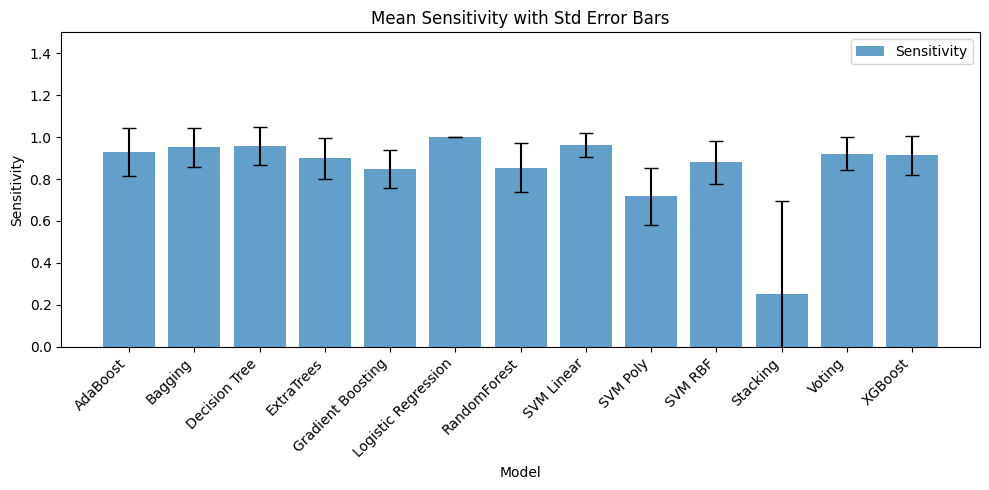

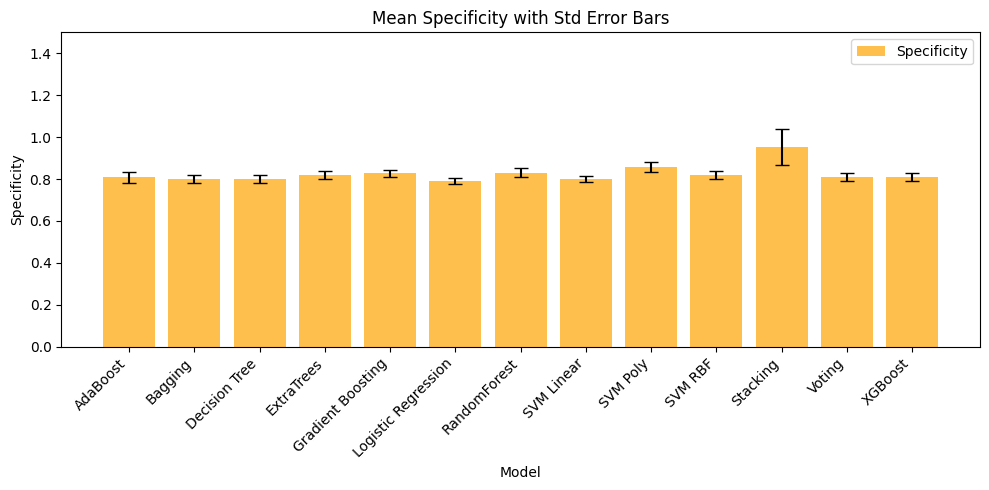

In [ ]:
# Compute the mean and std
agg_df = cm_df.groupby('Model')[['Sensitivity', 'Specificity']].agg(['mean', 'std'])

# Plot for Sensitivity
plt.figure(figsize=(10, 5))
plt.bar(agg_df.index, agg_df['Sensitivity']['mean'],
        yerr=agg_df['Sensitivity']['std'],
        capsize=5, alpha=0.7, label='Sensitivity')
plt.title("Mean Sensitivity with Std Error Bars")
plt.ylabel("Sensitivity")
plt.xlabel("Model")
plt.ylim(0, 1.5)  # extended from 1.0 to 1.5
plt.xticks(rotation=45, ha='right')  # rotate x-axis labels
plt.legend()
plt.tight_layout()  # prevent clipping
plt.show()

# Plot for Specificity
plt.figure(figsize=(10, 5))
plt.bar(agg_df.index, agg_df['Specificity']['mean'],
        yerr=agg_df['Specificity']['std'],
        capsize=5, alpha=0.7, color='orange', label='Specificity')
plt.title("Mean Specificity with Std Error Bars")
plt.ylabel("Specificity")
plt.xlabel("Model")
plt.ylim(0, 1.5)  # extended from 1.0 to 1.5
plt.xticks(rotation=45, ha='right')  # rotate x-axis labels
plt.legend()
plt.tight_layout()
plt.show()


### Best and Worst performing Models

#### F1-Score




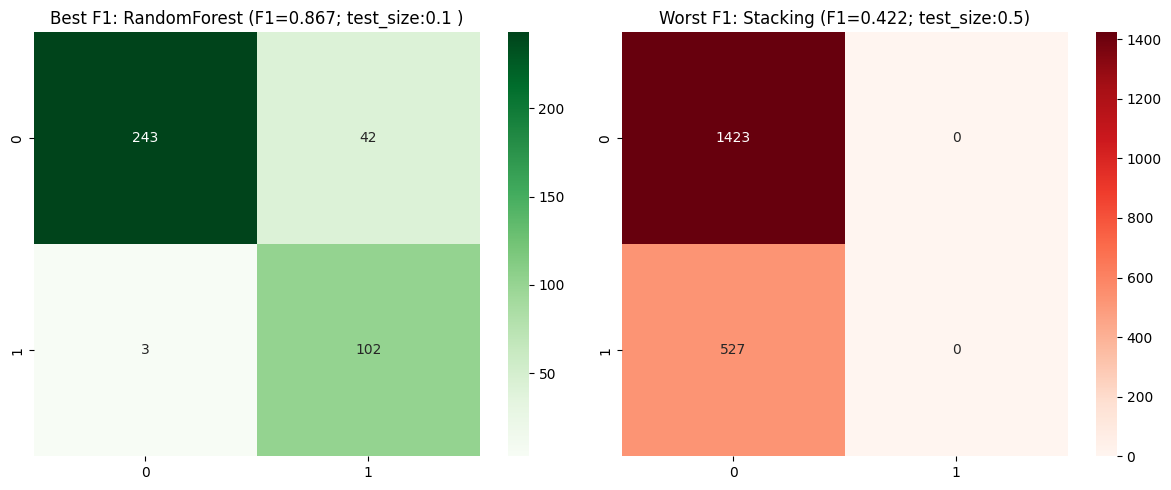

In [ ]:
# Find best and worst performing runs based on F1-Score
best_f1_idx = all_results['F1'].idxmax()
worst_f1_idx = all_results['F1'].idxmin()

best_config = all_results.loc[best_f1_idx]
worst_config = all_results.loc[worst_f1_idx]

# Find corresponding confusion matrices
best_cm = next(cm for cm in confusion_matrices
               if cm['Model']==best_config['Model'] and
                  cm['TestSize']==best_config['TestSize'] and
                  cm['RandomState']==best_config['RandomState'])

worst_cm = next(cm for cm in confusion_matrices
                if cm['Model']==worst_config['Model'] and
                   cm['TestSize']==worst_config['TestSize'] and
                   cm['RandomState']==worst_config['RandomState'])

# Plot comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(best_cm['ConfusionMatrix'], annot=True, fmt='d', ax=ax1, cmap='Greens')
ax1.set_title(f'Best F1: {best_config["Model"]} (F1={best_config["F1"]:.3f}; test_size:{best_config["TestSize"]} )')

sns.heatmap(worst_cm['ConfusionMatrix'], annot=True, fmt='d', ax=ax2, cmap='Reds')
ax2.set_title(f'Worst F1: {worst_config["Model"]} (F1={worst_config["F1"]:.3f}; test_size:{worst_config["TestSize"]})')

plt.tight_layout()
plt.show()

1. **Dataset Splits**

   * The smaller test set (10%) produced the **best-performing model**, while the larger test set (50%) produced the **worst-performing model**.


2. **Best Performing Model**

   * **Model:** Random Forest
   * **F1-score:** `0.867` (strong performance)
   * **Test size:** `0.1`
   * **Confusion matrix:**

     ```
     [243,  42]
     [  3, 102]
     ```
   * **Interpretation:**

     * The model identifies both classes well.
     * Only 3 false negatives (missed positives) → very low error on positive class.
     * 42 false positives (some negatives misclassified as positives).
     * Balanced performance, strong classifier.
     

3. **Worst Performing Model**

   * **Model:** Stacking
   * **F1-score:** `0.422` (weak performance)
   * **Test size:** `0.5`
   * **Confusion matrix:**

     ```
     [1423,    0]
     [ 527,    0]
     ```
   * **Interpretation:**

     * The model predicts **only the negative class**.
     * This leads to **zero true positives** and **zero predicted positives**.
     * Completely fails to recognize the positive class.
     * Suggests class imbalance or failure in the stacking ensemble training.



4. **Observations**

   * **Performance Gap:** There’s a dramatic gap between Random Forest and Stacking — one is highly accurate, the other completely collapses.
   * **Test Size Effect:** Larger test size might have made class distribution less favorable (especially if not stratified).
   * **Model Robustness:** Random Forest handles the dataset well, while Stacking seems unstable under this setup.
   * **Possible Imbalance:** The worst confusion matrix suggests a strong **class imbalance**, where predicting "all negatives" still yields high accuracy but very poor F1.







#### Stability

Check how consistent confusion matrices are per model

In [ ]:
cm_stability = {}
for model_name in all_results['Model'].unique():
    model_cms = [cm['ConfusionMatrix'] for cm in confusion_matrices if cm['Model'] == model_name]
    cm_stack = np.stack(model_cms)
    cm_std = np.std(cm_stack, axis=0)
    cm_stability[model_name] = np.mean(cm_std)

print("Confusion Matrix Stability (lower = more stable):")
for model, stability in sorted(cm_stability.items(), key=lambda x: x[1]):
    print(f"{model}: {stability:.2f}")

Confusion Matrix Stability (lower = more stable):
Logistic Regression: 288.44
Gradient Boosting: 290.80
SVM Linear: 291.64
Voting: 291.74
ExtraTrees: 292.43
SVM RBF: 292.64
XGBoost: 292.87
RandomForest: 292.93
Bagging: 293.94
AdaBoost: 294.28
SVM Poly: 295.04
Decision Tree: 297.77
Stacking: 317.93


#### Complete results

Printing previous results and saving them

In [ ]:
print(all_results.sort_values('F1', ascending=False).to_string(index=False))
all_results.to_csv('all_results_ordered.csv', index=False)
files.download("all_results_ordered.csv")

              Model  TestSize  RandomState  Accuracy  Precision   Recall       F1
       RandomForest       0.1           42  0.884615   0.848069 0.912030 0.867266
         ExtraTrees       0.1           42  0.882051   0.846919 0.916291 0.865723
      Decision Tree       0.1           42  0.874359   0.840909 0.914035 0.858380
Logistic Regression       0.1           42  0.874359   0.840909 0.914035 0.858380
           Stacking       0.1           42  0.874359   0.840909 0.914035 0.858380
            Bagging       0.1           42  0.874359   0.840909 0.914035 0.858380
         SVM Linear       0.1           42  0.874359   0.840909 0.914035 0.858380
           AdaBoost       0.1           42  0.874359   0.840909 0.914035 0.858380
             Voting       0.1           42  0.874359   0.840004 0.911028 0.857824
            SVM RBF       0.1           42  0.871795   0.836876 0.906266 0.854634
            XGBoost       0.1           42  0.864103   0.828333 0.894987 0.845602
           Stack

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## K-FOLD CROSS VALIDATION and BOOTSTRAP

Evaluation of the bias-variance trade-off for each model, before and after validation, to better understand generalization capabilities and identify potential areas for improvement

In [ ]:
# Configuration
n_folds = 5 # for K-fold CV
n_bootstrap = 100 # bootstrap iterations
random_state = 42

# Storage for results
kfold_results = []
bootstrap_results = []

n_folds = 5 → Using 5-fold CV is a standard trade-off: enough splits to reduce variance in estimates while keeping computational cost reasonable. More folds (e.g., 10) could give slightly more stable estimates but at higher cost.

n_bootstrap = 100 → Running 100 bootstrap iterations provides a good balance between stability and runtime. It’s usually enough for convergence of performance estimates; fewer (e.g., 30) might be too noisy, while many more (e.g., 1000) could be overkill unless extremely precise confidence intervals are needed.

random_state = 42 → Fixing the random seed ensures reproducibility of results. The choice of 42 is arbitrary but common practice.

Storage lists (kfold_results, bootstrap_results) → These are initialized as empty containers to collect results during evaluation, which will later be aggregated for analysis.

### K-Fold cross validation

In this section we evaluate each model using **K-Fold Cross Validation**:

- The dataset is split into *K folds* of equal size.
- Each fold is used once as the **test set**, while the remaining *K-1 folds* are used for **training**.
- This process is repeated *K times*, so every data point is used for both training and testing.
- Performance metrics (**Accuracy, Precision, Recall, F1**) are computed for each fold, allowing us to analyze both the **average performance** and the **stability (variance)** of the models.

This approach reduces the risk of performance depending on a single train/test split and provides a more robust model evaluation.


In [ ]:
kf = KFold(n_splits=n_folds, shuffle=True, random_state=random_state)

# Main Loop
le = LabelEncoder()
y_encoded = le.fit_transform(y) # 'No' -> 0, 'Yes' -> 1

for model_name, model in models:
    print(f"Processing K-Fold for: {model_name}")

    # Cross-validation scores
    cv_accuracy = cross_val_score(model, X, y_encoded, cv=kf, scoring='accuracy')
    cv_precision = cross_val_score(model, X, y_encoded, cv=kf, scoring='precision_macro')
    cv_recall = cross_val_score(model, X, y_encoded, cv=kf, scoring='recall_macro')
    cv_f1 = cross_val_score(model, X, y_encoded, cv=kf, scoring='f1_macro')

    # Store results
    for fold in range(n_folds):
        kfold_results.append({
            'Model': model_name,
            'Method': 'K-Fold CV',
            'Iteration': fold + 1,
            'Accuracy': cv_accuracy[fold],
            'Precision': cv_precision[fold],
            'Recall': cv_recall[fold],
            'F1': cv_f1[fold]
        })

Processing K-Fold for: Decision Tree
Processing K-Fold for: Logistic Regression
Processing K-Fold for: SVM Linear
Processing K-Fold for: SVM Poly
Processing K-Fold for: SVM RBF
Processing K-Fold for: Voting
Processing K-Fold for: Bagging
Processing K-Fold for: Stacking


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

Processing K-Fold for: AdaBoost
Processing K-Fold for: RandomForest
Processing K-Fold for: ExtraTrees
Processing K-Fold for: Gradient Boosting
Processing K-Fold for: XGBoost


### Bootstrap

Bootstrap resampling creates multiple datasets by sampling **with replacement** from the original data.  
Each model is trained and tested on these resampled datasets, and metrics (**Accuracy, Precision, Recall, F1**) are averaged.

In [ ]:
le = LabelEncoder()
y_encoded = le.fit_transform(y)
for model_name, model in models:
    print(f"Processing Bootstrap for: {model_name}")

    for i in range(n_bootstrap):
        if (i + 1) % 20 == 0: # Progress indicator
            print(f"  Bootstrap iteration {i + 1}/{n_bootstrap}")

        # Bootstrap sample
        X_boot, y_boot = resample(X, y_encoded, random_state=random_state + i, stratify=y_encoded)

        # Train-test split on bootstrap sample
        X_train, X_test, y_train, y_test = train_test_split(
            X_boot, y_boot, test_size=0.3, random_state=random_state + i, stratify=y_boot
        )

        # Fit and predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)

        # Calculate metrics
        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, average='macro', zero_division=0)
        rec = recall_score(y_test, y_pred, average='macro', zero_division=0)
        f1 = f1_score(y_test, y_pred, average='macro', zero_division=0)

        bootstrap_results.append({
            'Model': model_name,
            'Method': 'Bootstrap',
            'Iteration': i + 1,
            'Accuracy': acc,
            'Precision': prec,
            'Recall': rec,
            'F1': f1
        })

Processing Bootstrap for: Decision Tree
  Bootstrap iteration 20/100
  Bootstrap iteration 40/100
  Bootstrap iteration 60/100
  Bootstrap iteration 80/100
  Bootstrap iteration 100/100
Processing Bootstrap for: Logistic Regression
  Bootstrap iteration 20/100
  Bootstrap iteration 40/100
  Bootstrap iteration 60/100
  Bootstrap iteration 80/100
  Bootstrap iteration 100/100
Processing Bootstrap for: SVM Linear
  Bootstrap iteration 20/100
  Bootstrap iteration 40/100
  Bootstrap iteration 60/100
  Bootstrap iteration 80/100
  Bootstrap iteration 100/100
Processing Bootstrap for: SVM Poly
  Bootstrap iteration 20/100
  Bootstrap iteration 40/100
  Bootstrap iteration 60/100
  Bootstrap iteration 80/100
  Bootstrap iteration 100/100
Processing Bootstrap for: SVM RBF
  Bootstrap iteration 20/100
  Bootstrap iteration 40/100
  Bootstrap iteration 60/100
  Bootstrap iteration 80/100
  Bootstrap iteration 100/100
Processing Bootstrap for: Voting
  Bootstrap iteration 20/100
  Bootstrap iter

### Results

Print all the results

In [ ]:
all_cv_results = pd.DataFrame(kfold_results + bootstrap_results)
print(all_cv_results.sort_values('F1', ascending=False).to_string(index=False))


              Model    Method  Iteration  Accuracy  Precision   Recall       F1
           SVM Poly Bootstrap         65  0.929060   0.901680 0.926485 0.912818
       RandomForest Bootstrap         13  0.927350   0.896274 0.935282 0.912426
       RandomForest Bootstrap         65  0.927350   0.896274 0.935282 0.912426
       RandomForest Bootstrap         60  0.926496   0.894949 0.935694 0.911621
       RandomForest Bootstrap         18  0.924786   0.892984 0.933526 0.909565
       RandomForest Bootstrap         63  0.925641   0.895907 0.927134 0.909429
       RandomForest Bootstrap         45  0.923077   0.889864 0.938336 0.908573
       RandomForest Bootstrap         71  0.923932   0.892107 0.931943 0.908460
       RandomForest Bootstrap         40  0.923077   0.890456 0.934348 0.907973
       RandomForest Bootstrap         55  0.923077   0.890456 0.934348 0.907973
       RandomForest Bootstrap         43  0.921368   0.887936 0.936168 0.906542
       RandomForest Bootstrap         80

In [ ]:
all_cv_results.to_csv('all_kfb_results_ordered.csv', index=False)
files.download("all_kfb_results_ordered.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Bias-Variance Analysis

#### Computation of each model

In [ ]:
# Calculate bias and variance for each model and method
bias_variance_summary = []

for model_name in all_cv_results['Model'].unique():
    for method in ['K-Fold CV', 'Bootstrap']:
        method_data = all_cv_results[
            (all_cv_results['Model'] == model_name) &
            (all_cv_results['Method'] == method)
        ]

        for metric in ['Accuracy', 'Precision', 'Recall', 'F1']:
            scores = method_data[metric].values

            # Bias = difference from "true" performance
            true_performance = all_cv_results[
                all_cv_results['Model'] == model_name
            ][metric].mean()

            mean_score = np.mean(scores)
            bias = mean_score - true_performance # Bias (signed)
            variance = np.var(scores) # Variance
            std_dev = np.std(scores) # Standard deviation

            bias_variance_summary.append({
                'Model': model_name,
                'Method': method,
                'Metric': metric,
                'Mean': mean_score,
                'Bias': abs(bias), # Absolute bias for easier interpretation
                'Variance': variance,
                'Std_Dev': std_dev,
                'Min': np.min(scores),
                'Max': np.max(scores)
            })

bias_variance_df = pd.DataFrame(bias_variance_summary)

#### Summary of Bias-Variance and graphical representation


bias variance calculated on the performance of tuned model (after k-fold and bootstrap)


In [ ]:
for model_name in bias_variance_df['Model'].unique():
    print(f"\n{model_name}:")
    model_summary = bias_variance_df[bias_variance_df['Model'] == model_name]
    print(model_summary[['Method', 'Metric', 'Mean', 'Bias', 'Variance', 'Std_Dev']].round(4))


Decision Tree:
      Method     Metric    Mean    Bias  Variance  Std_Dev
0  K-Fold CV   Accuracy  0.8400  0.0017    0.0001   0.0111
1  K-Fold CV  Precision  0.8139  0.0014    0.0001   0.0115
2  K-Fold CV     Recall  0.8904  0.0011    0.0001   0.0074
3  K-Fold CV         F1  0.8240  0.0019    0.0001   0.0122
4  Bootstrap   Accuracy  0.8418  0.0001    0.0001   0.0087
5  Bootstrap  Precision  0.8154  0.0001    0.0000   0.0064
6  Bootstrap     Recall  0.8916  0.0001    0.0000   0.0059
7  Bootstrap         F1  0.8260  0.0001    0.0001   0.0085

Logistic Regression:
       Method     Metric    Mean    Bias  Variance  Std_Dev
8   K-Fold CV   Accuracy  0.8400  0.0019    0.0001   0.0111
9   K-Fold CV  Precision  0.8139  0.0012    0.0001   0.0115
10  K-Fold CV     Recall  0.8904  0.0005    0.0001   0.0074
11  K-Fold CV         F1  0.8240  0.0019    0.0001   0.0122
12  Bootstrap   Accuracy  0.8420  0.0001    0.0001   0.0086
13  Bootstrap  Precision  0.8152  0.0001    0.0000   0.0064
14  Bootstr

Random Forest with Bootstrap sampling clearly outperforms all other methods, achieving the highest Accuracy (0.9122), Recall (0.9215), and F1-score (0.8951) with minimal bias and variance. ExtraTrees and Gradient Boosting with Bootstrap also perform very well (Accuracy ~0.87–0.87, F1 ~0.85), ranking just below Random Forest.

On the other hand, Stacking with K-Fold CV is by far the worst, showing extremely poor Precision (0.3650) and F1 (0.4219), indicating severe model instability or poor meta-learning. SVM Poly with K-Fold CV also performs weakly (Accuracy 0.8221, F1 0.7894) but improves drastically with Bootstrap (Accuracy 0.9064, F1 0.8846), showing sensitivity to the evaluation method.

Generally, bootstrap estimates yield more optimistic and stable results compared to K-Fold CV across most models, with much lower bias and variance. Bagging, AdaBoost, Logistic Regression, and Decision Tree show almost identical performance (Accuracy ~0.84, F1 ~0.824), suggesting limited improvement from boosting or bagging over simple baselines in this setup.

XGBoost, while stable, does not surpass Random Forest or ExtraTrees, achieving Accuracy ~ 0.85 and F1 ~ 0.83 with Bootstrap. SVM (Linear and RBF) and Voting ensemble perform in the mid-range (~0.84 Accuracy, ~0.82 F1), but with higher bias in K-Fold CV than bootstrap.

Key trends:

Best model: Random Forest (Bootstrap).

Worst model: Stacking (K-Fold CV).

Bootstrap > K-Fold CV in stability and bias reduction.

Tree-based ensembles (RF, ExtraTrees, GBM) dominate over linear/SVM methods.

Models like Bagging, AdaBoost, Logistic Regression, and Decision Tree converge to nearly identical performance (~0.84 Accuracy).

#### Graphical visualization of Bias-Variance

Variance

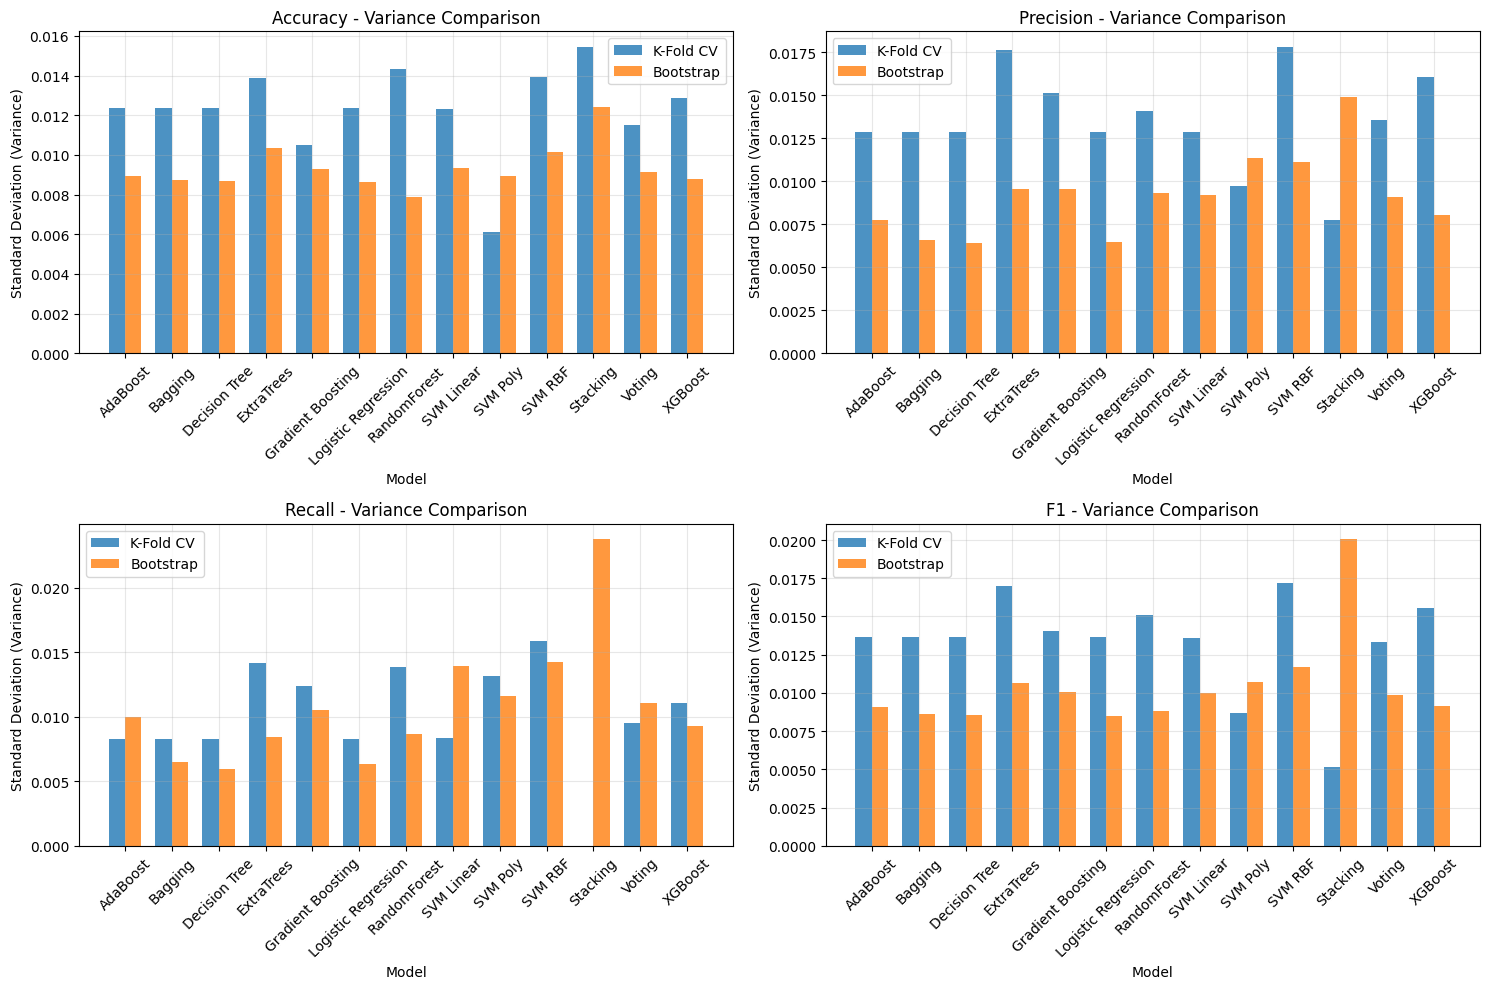

In [ ]:
plt.figure(figsize=(15, 10))

metrics = ['Accuracy', 'Precision', 'Recall', 'F1']
for i, metric in enumerate(metrics, 1):
    plt.subplot(2, 2, i)

    metric_data = all_cv_results.pivot_table(
        values=metric,
        index='Model',
        columns='Method',
        aggfunc=['mean', 'std']
    )

    # Plot variance (std dev) comparison
    models = metric_data.index
    kfold_std = metric_data[('std', 'K-Fold CV')].values
    bootstrap_std = metric_data[('std', 'Bootstrap')].values

    x = np.arange(len(models))
    width = 0.35

    plt.bar(x - width/2, kfold_std, width, label='K-Fold CV', alpha=0.8)
    plt.bar(x + width/2, bootstrap_std, width, label='Bootstrap', alpha=0.8)

    plt.xlabel('Model')
    plt.ylabel('Standard Deviation (Variance)')
    plt.title(f'{metric} - Variance Comparison')
    plt.xticks(x, models, rotation=45)
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Distribution Comparison: Boxplots

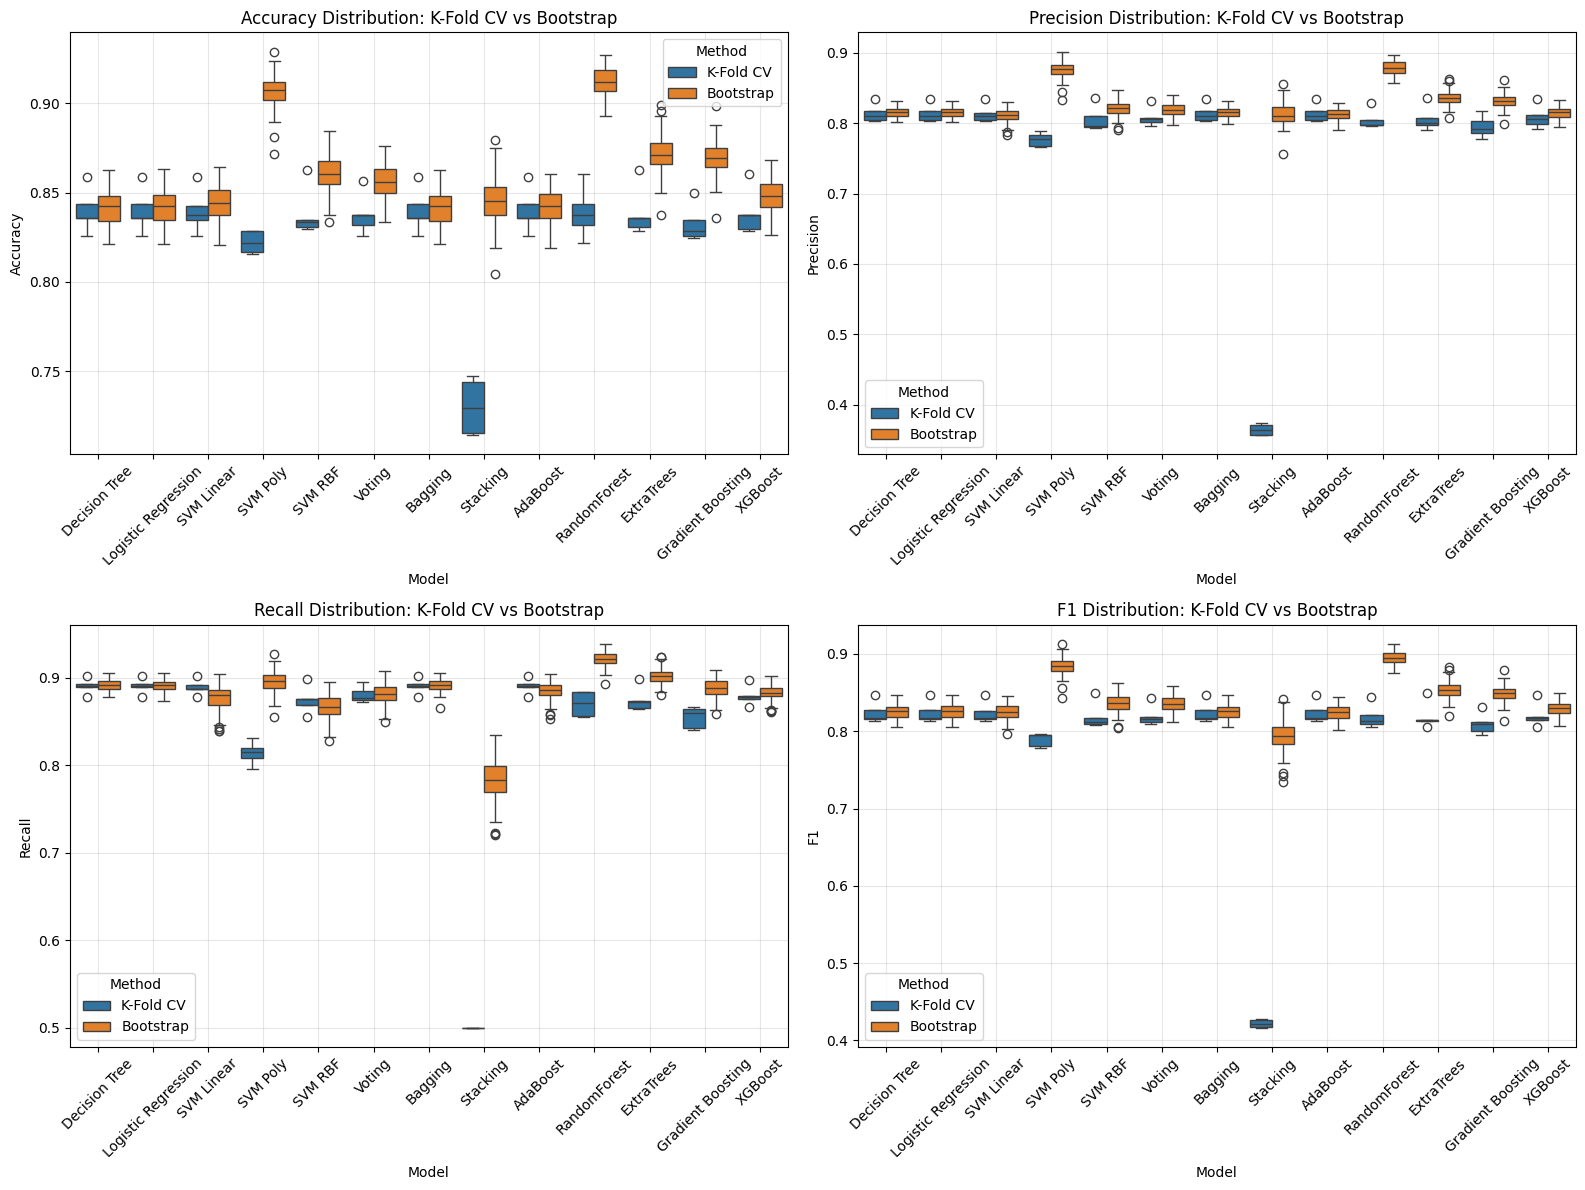

In [ ]:
plt.figure(figsize=(16, 12))

for i, metric in enumerate(metrics, 1):
    plt.subplot(2, 2, i)

    sns.boxplot(data=all_cv_results, x='Model', y=metric, hue='Method')
    plt.title(f'{metric} Distribution: K-Fold CV vs Bootstrap')
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


Bias Visualization

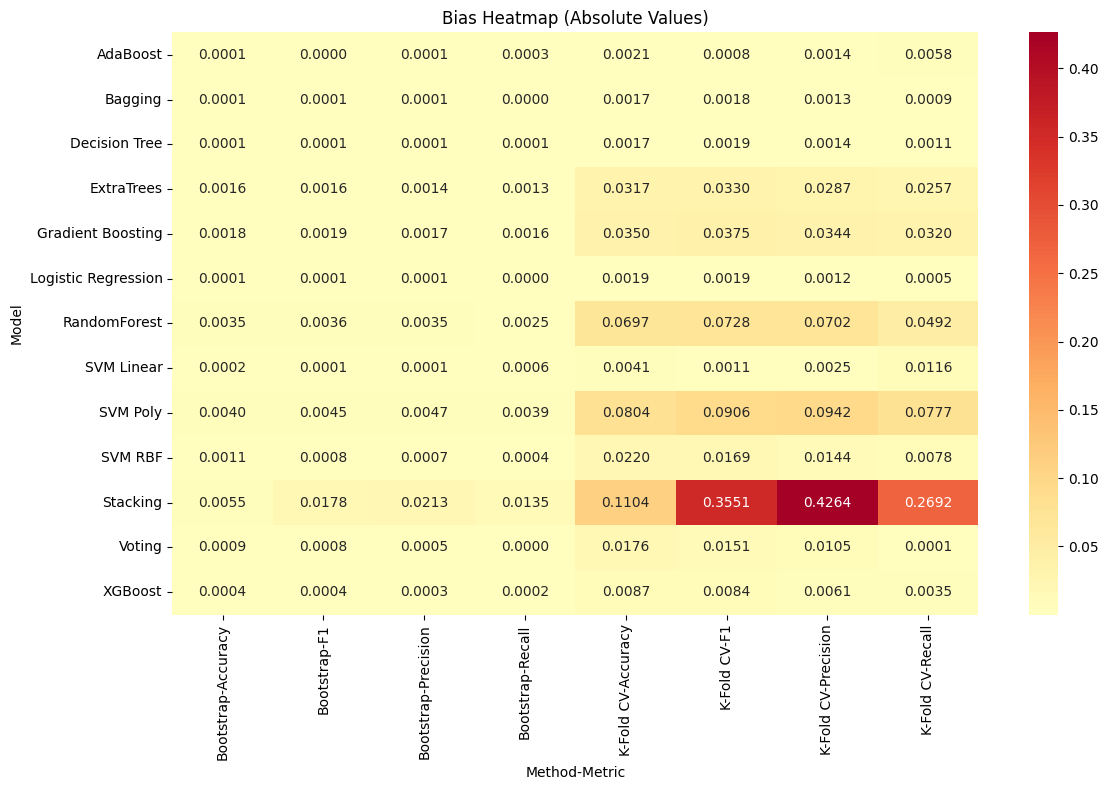

In [ ]:
plt.figure(figsize=(12, 8))

bias_pivot = bias_variance_df.pivot_table(
    values='Bias',
    index='Model',
    columns=['Method', 'Metric']
)

sns.heatmap(bias_pivot, annot=True, fmt='.4f', cmap='RdYlBu_r', center=0)
plt.title('Bias Heatmap (Absolute Values)')
plt.tight_layout()
plt.show()

Variance Heatmap

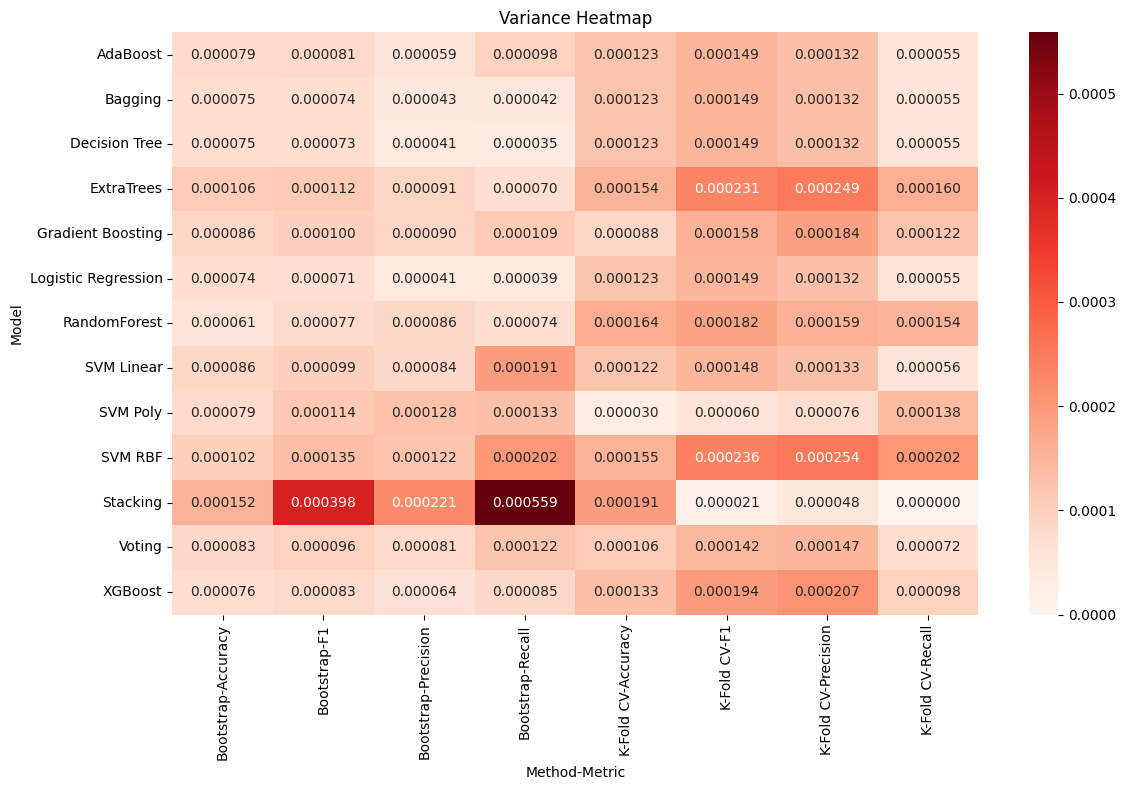

In [ ]:
plt.figure(figsize=(12, 8))

variance_pivot = bias_variance_df.pivot_table(
    values='Variance',
    index='Model',
    columns=['Method', 'Metric']
)

sns.heatmap(variance_pivot, annot=True, fmt='.6f', cmap='Reds')
plt.title('Variance Heatmap')
plt.tight_layout()
plt.show()

#### Summary of Bias-Variance (after kfold and bootsrap)

Bias_variance using k-fold and bootstrap

In [ ]:
# K-Fold summary
print("\nK-FOLD CROSS-VALIDATION SUMMARY:")
kfold_summary = all_cv_results[all_cv_results['Method'] == 'K-Fold CV'].groupby('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1']
].agg(['mean', 'std', 'min', 'max'])
print(kfold_summary.round(4))

# Bootstrap summary
print("\nBOOTSTRAP SUMMARY:")
bootstrap_summary = all_cv_results[all_cv_results['Method'] == 'Bootstrap'].groupby('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1']
].agg(['mean', 'std', 'min', 'max'])
print(bootstrap_summary.round(4))


K-FOLD CROSS-VALIDATION SUMMARY:
                    Accuracy                         Precision                          Recall                              F1                        
                        mean     std     min     max      mean     std     min     max    mean     std     min     max    mean     std     min     max
Model                                                                                                                                                 
AdaBoost              0.8400  0.0124  0.8256  0.8590    0.8139  0.0128  0.8031  0.8348  0.8904  0.0083  0.8781  0.9013  0.8240  0.0137  0.8134  0.8463
Bagging               0.8400  0.0124  0.8256  0.8590    0.8139  0.0128  0.8031  0.8348  0.8904  0.0083  0.8781  0.9013  0.8240  0.0137  0.8134  0.8463
Decision Tree         0.8400  0.0124  0.8256  0.8590    0.8139  0.0128  0.8031  0.8348  0.8904  0.0083  0.8781  0.9013  0.8240  0.0137  0.8134  0.8463
ExtraTrees            0.8387  0.0139  0.8282  0.8628    0.80

Save data

In [ ]:
all_cv_results.to_csv('bias_variance_raw_results.csv', index=False)
bias_variance_df.to_csv('bias_variance_summary.csv', index=False)
print(f"\nResults saved:")
print("- Raw data: 'bias_variance_raw_results.csv'")
print("- Summary: 'bias_variance_summary.csv'")

print(f"\nTotal experiments: {len(all_cv_results)} ({n_folds} K-fold + {n_bootstrap} bootstrap per model)")


Results saved:
- Raw data: 'bias_variance_raw_results.csv'
- Summary: 'bias_variance_summary.csv'

Total experiments: 1365 (5 K-fold + 100 bootstrap per model)


In [ ]:
files.download("bias_variance_raw_results.csv")
files.download("bias_variance_summary.csv")
files.download("summary_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>